# AI-Powered CHRIST University Student Helpdesk Chatbot
## Local LLM and RAG Experiments (Ollama, FAISS, Sentence-Transformers) with LLMOps Monitoring


---
# Section 1: Project Introduction

## 1.1 Problem statement
A university student handbook is long, dense and written in formal language. Rules on attendance, examinations, leave, discipline and support services are spread over many pages, and the answer to a single practical question ("Can I write the exam if my attendance is short?") may depend on several clauses. Students often ask the same questions repeatedly, and support staff spend time answering them. Wrong or outdated answers can have real academic consequences.

**Problem:** *How can students get fast, accurate, source-backed answers from the official handbook, without the system inventing policies, and on modest hardware?*

## 1.2 Motivation for a CHRIST University student-support chatbot
* **Availability:** answers outside office hours.
* **Consistency:** every student receives an answer derived from the same official text.
* **Findability:** natural-language questions instead of browsing a PDF.
* **Staff workload:** routine queries are deflected, complex cases go to humans.

## 1.3 Why a conventional FAQ chatbot is insufficient
| Limitation of FAQ/keyword bots | Consequence |
|---|---|
| Fixed question-answer pairs | Cannot answer paraphrased or combined questions. |
| Manual curation | Every handbook revision requires manual FAQ edits; content drifts from the source. |
| No grounding in the full document | Misses clauses that nobody wrote an FAQ for. |
| Brittle matching | "Shortage of attendance" and "low attendance" may not match. |

## 1.4 Why Retrieval-Augmented Generation (RAG) is appropriate
A plain LLM answers from what it memorised during training, which does not include this university's current handbook, so it will tend to produce plausible but **fabricated** policies. RAG instead **retrieves** the relevant handbook passages at question time and instructs the model to answer **only from those passages**. This gives (a) up-to-date knowledge by re-indexing the PDF instead of retraining, (b) page-level citations a student can verify, and (c) a testable behaviour: "say you do not know when the context lacks the answer".

## 1.5 Why local LLMs are being explored
* **Privacy:** student questions are never sent to a third-party LLM API; inference runs inside your own Colab runtime (the Colab VM itself is hosted by Google, so a production deployment should run on infrastructure the university controls).
* **Cost:** no per-token API fees.
* **Control and reproducibility:** pinned model tags and fixed generation settings.
* **Feasibility study:** can a *small quantized model running locally in a Google Colab runtime (CPU-only, or with a modest GPU if Colab allocates one)* be good enough for a helpdesk? This is an empirical question that this notebook is designed to answer.

## 1.6 Role of LLMOps
LLMOps applies operational discipline to LLM applications. Here it means **logging every request** (model tag, latency, memory, retrieved chunks, errors), **evaluating models consistently** on a fixed question set, **comparing** them with recorded evidence, and keeping runs **reproducible** (configuration hashes, model digests, saved outputs). It turns "this model feels better" into evidence.

## 1.7 Project objectives
1. Build a reusable PDF-to-answer RAG pipeline (extraction, cleaning, chunking, embeddings, FAISS, retrieval, grounded prompting).
2. Run three small local LLMs through Ollama **sequentially** with identical retrieval and prompts.
3. Measure latency, generation speed, RAM, error rate (automated) and correctness, groundedness, hallucination (manual).
4. Test hallucination resistance with questions whose answers are intentionally absent.
5. Log all runs with lightweight LLMOps instrumentation.
6. Select a model for the final Streamlit application **based on recorded evidence**.

## 1.8 Scope and limitations
**In scope:** one handbook PDF, text-based extraction, three Ollama models, CPU-compatible local inference (a Colab GPU is used only if one is allocated), a fixed question set, manual scoring.

**Limitations (be honest about these in your report):**
* Scanned/image PDFs need OCR, which is not included.
* Tables and multi-column layouts may extract imperfectly with PyPDF.
* Small LLMs (1 to 2 billion parameters) are weaker at reasoning and instruction following.
* A small question set and a single reviewer limit statistical strength.
* Latency and RAM depend on your hardware, background load and Ollama version.
* Retrieval quality limits answer quality: if the right chunk is not retrieved, no LLM can answer correctly.
* This is a prototype; it is not an authoritative source of university policy.

---
# Section 2: System Architecture

## 2.1 End-to-end pipeline
**Student Handbook PDF → Text Extraction → Text Cleaning → Token-Aware Chunking → Chunk Validation → Embedding Generation → Embedding Validation → FAISS Vector Database → Retrieval → Local LLM → Context-Grounded Response → Evaluation and Monitoring**

## 2.2 Mermaid architecture diagram
*(Colab does not render Mermaid blocks. Use the plain-text fallback below, or paste the diagram into https://mermaid.live. It renders on GitHub and in VS Code with a Mermaid extension.)*

```mermaid
flowchart TB
    subgraph OFFLINE["Offline indexing (run once per handbook version)"]
        A["Student Handbook PDF"] --> B["Text Extraction<br/>pypdf, page numbers kept"]
        B --> C["Text Cleaning<br/>whitespace, hyphenation, control chars"]
        C --> D["Token-aware chunking<br/>real tokenizer offsets, overlap, chunk IDs, page metadata"]
        D --> V["Chunk validation<br/>token limit incl. special tokens, coverage, unique IDs"]
        V --> E["Embedding Generation<br/>all-MiniLM-L6-v2, CPU, batched, normalised"]
        E --> F[("FAISS Vector Index<br/>+ vector-ID to chunk map<br/>vector count verified")]
    end

    subgraph ONLINE["Online query (per student question)"]
        Q["Student question"] --> QE["Query embedding"]
        QE --> R["Retrieval<br/>top-k by cosine similarity"]
        F --> R
        R --> P["Grounded prompt<br/>system rules + context + question"]
        P --> L["Local LLM via Ollama (server started manually in Colab)<br/>llama3.2:1b / qwen2.5:1.5b / gemma2:2b<br/>one model loaded at a time, unload verified"]
        L --> ANS["Context-grounded answer<br/>with page references"]
    end

    R -. "retrieval latency, chunk IDs, scores" .-> M
    L -. "latency, tokens/s, RAM, errors" .-> M
    ANS -. "manual scoring: correctness, groundedness" .-> M
    M["Evaluation and Monitoring<br/>JSONL/CSV logs, comparison charts, decision table"]
```

**Plain-text fallback**
```
PDF -> extract -> clean -> token-aware chunk -> validate -> embed -> verify -> [FAISS index]
                                                  |
Question -> embed query -> retrieve top-k --------+
                               |
                      grounded prompt -> local LLM (Ollama) -> answer + page refs
                               |                 |                    |
                               +---- logs: retrieval ----- logs: latency/RAM/errors ---- manual scores
                                                  -> Evaluation and Monitoring
```

## 2.3 Component responsibilities
| Stage | Responsibility | Key design choice here |
|---|---|---|
| Extraction | Read text per page with PyPDF | Keep page number and filename on everything downstream. |
| Cleaning | Normalise whitespace and artefacts | Preserve line/paragraph structure; do not rewrite content. |
| Chunking | Split pages into retrievable units | Token-aware (real tokenizer offsets, original text preserved); configurable token size/overlap; chunks never cross page boundaries so citations stay exact. |
| Embedding | Convert text to vectors | Small CPU model, batched; vectors L2-normalised; count, dimension and finiteness verified. |
| FAISS | Fast nearest-neighbour search | Exact inner-product index (suitable for a few thousand chunks); vector count verified; index tied to a chunk-set fingerprint so a stale index cannot be used. |
| Retrieval | Find the top-k chunks for a question | Shared by all three LLMs for fairness. |
| Local LLM | Write the answer from the context | Ollama, one model in memory at a time. |
| Evaluation/Monitoring | Measure and log | Automated metrics and manual scores kept separate. |

## 2.4 Key distinctions
| Concept | What it is | What it is *not* |
|---|---|---|
| **LLM** | A large generative language model that produces text token by token (here: Llama 3.2 1B, Qwen2.5 1.5B, Gemma 2 2B). Decides *what to say*. | It does not search your documents by itself and it has no knowledge of your handbook unless you put it in the prompt. |
| **Embedding model** | A much smaller encoder that maps text to a fixed-length vector so that similar meanings are close. Used for *finding* text. | It does not generate answers. |
| **Vector database** | A store/index (FAISS here) that finds the nearest vectors quickly and returns IDs. | It does not understand text; it only compares numbers. |
| **RAG** | A *pattern* that combines retrieval (embeddings + vector index) with generation (LLM) so the LLM answers from retrieved evidence. | It is not a model; it is a pipeline design. |
| **LLMOps** | The *practices and tooling* for deploying, monitoring, evaluating and reproducing LLM applications. | It is not a model or a library; it is a discipline (here implemented as lightweight logging and evaluation). |

---
# Section 3: Environment and Dependency Setup (Google Colab)
Nothing in this section has been executed. Run the cells yourself, in order.

| Step | Purpose |
|---|---|
| 3.1 | Detect the Colab runtime (Python, platform, GPU runtime or not) |
| 3.2 | Install only the Python libraries that are missing |
| 3.3 | Import dependencies and set safe environment variables |
| 3.4 | Install Ollama inside Colab (skipped if it is already installed) |
| 3.5 | Start the Ollama server **manually** (no systemd) with reuse detection, timeout and health check |
| 3.6 to 3.8 | RAM, CPU and GPU detection with warnings |
| 3.8a | Choose where outputs live: Google Drive (persistent) or local `/content` |
| 3.9 | Global configuration and shared helpers |
| 3.10 | Runtime and resource monitor (RAM, CPU, GPU, Ollama server, loaded models) |
| 3.11 | **Ollama verification experiment**: download Llama 3.2 1B, generate one answer, record the duration |

**Colab-specific notes**
* If `pip` upgrades a package that was already imported, Colab shows a *Restart session* button. Restart, then continue from 3.1. Cell 3.2 only installs what is missing, so this is rare.
* If you restart the session, a running `ollama serve` process may survive. Cell 3.5 detects that and **reuses it instead of starting a second server**.
* `OLLAMA_MAX_LOADED_MODELS=1` is set when *this notebook* starts the server, so the server itself refuses to keep two models in memory. If a server was already running, this setting cannot be verified from here.

### 3.1 [RUN] Detect the Google Colab runtime

In [1]:
import sys, os, platform, shutil

IN_COLAB = ("google.colab" in sys.modules) or ("COLAB_RELEASE_TAG" in os.environ) or ("COLAB_GPU" in os.environ)

print("Python version :", sys.version.split()[0])
print("Executable     :", sys.executable)
print("Platform       :", platform.platform())
print("Google Colab   :", IN_COLAB)

if platform.system() != "Linux":
    raise RuntimeError("This notebook is written for the Linux runtime of Google Colab. "
                       f"Detected '{platform.system()}'. Open it in Colab (Runtime > Connect).")
if sys.version_info < (3, 9):
    raise RuntimeError("Python 3.9 or newer is required.")
if not IN_COLAB:
    print("WARNING: this does not look like Google Colab. The notebook still tries to continue on a generic Linux machine, "
          "but cell 3.4 needs root (apt-get) and cell 3.8a (Google Drive) will fall back to local storage.")
if hasattr(os, "geteuid") and os.geteuid() != 0:
    print("WARNING: not running as root. 'apt-get' and the Ollama installer in cell 3.4 normally need root (Colab runs as root).")

print("GPU runtime    :", "nvidia-smi found (a GPU may be allocated)" if shutil.which("nvidia-smi")
      else "no nvidia-smi: CPU runtime. This is fully supported.")

Python version : 3.13.16
Executable     : /usr/bin/python3
Platform       : Linux-6.6.159+-x86_64-with-glibc2.39
Google Colab   : True
GPU runtime    : nvidia-smi found (a GPU may be allocated)


### 3.2 [RUN ONCE] Install missing Python libraries
Only packages that cannot be imported are installed (Colab already ships pandas, numpy, matplotlib, seaborn, psutil, tqdm, torch and usually sentence-transformers). This avoids needless upgrades of Colab's pre-installed scientific stack. If Colab asks you to **restart the session**, do so and continue from cell 3.1.

In [2]:
import importlib, importlib.util, subprocess, sys

# import name -> pip name
REQUIRED_PACKAGES = {
    "requests": "requests", "ollama": "ollama", "sentence_transformers": "sentence-transformers",
    "faiss": "faiss-cpu", "pypdf": "pypdf", "pandas": "pandas", "numpy": "numpy",
    "matplotlib": "matplotlib", "seaborn": "seaborn", "psutil": "psutil", "tqdm": "tqdm",
}
_missing = [pip_name for mod, pip_name in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]

if not _missing:
    print("All required Python packages are already installed. Nothing to do.")
else:
    print("Installing missing packages:", _missing)
    _rc = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *_missing]).returncode
    importlib.invalidate_caches()
    still_missing = [pip_name for mod, pip_name in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
    if _rc != 0 or still_missing:
        raise RuntimeError(f"pip install failed or incomplete (exit code {_rc}, still missing: {still_missing}). "
                           "Check the internet connection of the runtime and run this cell again.")
    print("Installed. If a later import fails, use Runtime > Restart session and re-run from cell 3.1.")

Installing missing packages: ['ollama', 'faiss-cpu', 'pypdf']
Installed. If a later import fails, use Runtime > Restart session and re-run from cell 3.1.


### 3.3 [DEFINE] Import dependencies
`sentence_transformers` (which imports PyTorch) is imported **later**, only when the embedding model is loaded. No environment variable here hides the GPU: the Ollama server inherits this process's environment, so hiding CUDA devices here would also hide the GPU from Ollama.

In [3]:
# ---- Colab-safe environment: this cell must run BEFORE torch or faiss are imported ----
# NOTE: CUDA_VISIBLE_DEVICES is deliberately NOT modified. A child process (ollama serve) inherits this environment,
# so blanking it here would silently hide a Colab GPU from Ollama.
import os
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")       # avoids HF tokenizers fork warnings

import sys, gc, json, time, re, math, hashlib, shutil, subprocess, platform, threading, unicodedata, random, warnings, bisect, uuid
from datetime import datetime, timezone
from pathlib import Path
from importlib import metadata as importlib_metadata

import numpy as np
import pandas as pd
import requests
import psutil
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display

missing_packages = []
try:
    import ollama
except ImportError:
    ollama = None
    missing_packages.append("ollama")
try:
    import faiss
except ImportError:
    faiss = None
    missing_packages.append("faiss-cpu")
try:
    from pypdf import PdfReader
except ImportError:
    PdfReader = None
    missing_packages.append("pypdf")

import importlib.util
if importlib.util.find_spec("sentence_transformers") is None:
    missing_packages.append("sentence-transformers")

if missing_packages:
    print("MISSING PACKAGES:", ", ".join(missing_packages))
    print("Run cell 3.2 (pip install), restart the session if Colab asks you to, then run this cell again.")
else:
    print("Core imports OK.")

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
MB = 1024 ** 2

def package_version(dist_name):
    """Return installed version of a package, or None."""
    try:
        return importlib_metadata.version(dist_name)
    except importlib_metadata.PackageNotFoundError:
        return None

for _pkg in ["ollama", "sentence-transformers", "transformers", "tokenizers", "torch", "faiss-cpu", "pypdf", "requests", "pandas", "numpy", "matplotlib", "seaborn", "psutil", "scikit-learn", "tqdm"]:
    print(f"{_pkg:22s} {package_version(_pkg)}")

Core imports OK.
ollama                 0.6.3
sentence-transformers  5.7.0
transformers           5.22.1
tokenizers             0.23.3
torch                  2.14.1+cu130
faiss-cpu              1.16.0
pypdf                  7.1.0
requests               2.32.4
pandas                 2.2.3
numpy                  2.4.6
matplotlib             3.10.0
seaborn                0.13.2
psutil                 5.9.5
scikit-learn           1.6.1
tqdm                   4.67.3


### 3.4 [RUN] Install Ollama inside the Colab runtime
Uses the documented procedure: `zstd` first (the installer ships a `.tar.zst`), then the official install script. `pciutils` (`lspci`) is installed as well, because a previous Colab run of this project printed *"Unable to detect NVIDIA/AMD GPU. Install lspci or lshw"*; with `lspci` the installer can detect a GPU runtime.

**Expected and harmless:** the installer prints `WARNING: systemd is not running`. That is why Section 3.5 starts the server manually.

The cell is **idempotent**: if the `ollama` executable already exists, nothing is downloaded again. Use `install_ollama(force=True)` to reinstall.

In [4]:
def find_ollama_executable():
    """Locate the Ollama CLI on PATH or in the usual Linux install locations."""
    exe = shutil.which("ollama")
    if exe:
        return exe
    for candidate in ("/usr/local/bin/ollama", "/usr/bin/ollama", "/opt/ollama/bin/ollama"):
        if os.path.isfile(candidate) and os.access(candidate, os.X_OK):
            return candidate
    return None

def run_streaming(command, shell=True):
    """Run a command, print its output line by line (so Colab shows progress) and return the exit code."""
    proc = subprocess.Popen(command, shell=shell, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                            bufsize=1, executable="/bin/bash" if shell else None)
    for line in proc.stdout:
        print(line.rstrip())
    return proc.wait()

def install_ollama(force=False):
    """Install Ollama on Linux (Colab). Returns the path of the executable. Raises RuntimeError with the reason on failure."""
    exe = find_ollama_executable()
    if exe and not force:
        print(f"Ollama is already installed: {exe} (nothing downloaded). Use install_ollama(force=True) to reinstall.")
        return exe
    if platform.system() != "Linux":
        raise RuntimeError("Ollama installation here targets the Linux runtime of Google Colab.")
    print("Step 1/2: installing helper packages (zstd, pciutils) ...")
    rc = run_streaming("apt-get update -qq && apt-get install -y -qq zstd pciutils")
    if rc != 0:
        print(f"WARNING: apt-get returned {rc}. Continuing only if 'zstd' is available.")
    if shutil.which("zstd") is None:
        raise RuntimeError("zstd is not available, so the Ollama installer cannot unpack its archive. "
                           "Check the apt output above (internet access / package index) and run this cell again.")
    print("\nStep 2/2: running the official Ollama install script (a 'systemd is not running' warning is expected) ...")
    rc = run_streaming("curl -fsSL https://ollama.com/install.sh | sh")
    exe = find_ollama_executable()
    if exe is None:
        raise RuntimeError(f"The Ollama installer finished with exit code {rc} but no 'ollama' executable was found. "
                           "Read the installer output above; check that the runtime has internet access.")
    if rc != 0:
        print(f"NOTE: the installer exited with code {rc}, but the executable exists ({exe}). "
              "This can happen when systemd is missing; the next cell starts the server manually.")
    print(f"\nOllama installed: {exe}")
    return exe

OLLAMA_EXE = install_ollama()
try:
    _v = subprocess.run([OLLAMA_EXE, "--version"], capture_output=True, text=True, timeout=30)
    print("CLI version output:", (_v.stdout + _v.stderr).strip())
except Exception as exc:
    print("Could not run 'ollama --version':", exc)

Step 1/2: installing helper packages (zstd, pciutils) ...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package pci.ids.
(Reading database ...
(Reading database ... 5%
(Reading database ... 10%
(Reading database ... 15%
(Reading database ... 20%
(Reading database ... 25%
(Reading database ... 30%
(Reading database ... 35%
(Reading database ... 40%
(Reading database ... 45%
(Reading database ... 50%
(Reading database ... 55%
(Reading database ... 60%
(Reading database ... 65%
(Reading database ... 70%
(Reading database ... 75%
(Reading database ... 80%
(Reading database ... 85%
(Reading database ... 90%
(Reading database ... 95%
(Reading database ... 100%
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../pci.ids_0.0~2024.03.31-1ubuntu0.1_all.deb ...
Unpacking pci.ids (

### 3.5 [RUN] Start the Ollama server manually (no systemd) and check its health
Colab has no systemd, so the server is started with `ollama serve` as a background process. This cell is safe to **run again and again**:

1. If a healthy server already answers at `OLLAMA_HOST`, it is **reused** and no process is started.
2. If an `ollama serve` process exists (started by this notebook or by an earlier session) but does not answer yet, the cell **waits** for it instead of starting a duplicate.
3. Only otherwise is a new server started (detached from the kernel, so *Interrupt execution* does not kill it). Server output goes to `/tmp/ollama_server.log`, which is printed if startup fails.
4. Startup is bounded by `OLLAMA_STARTUP_TIMEOUT_S`. A server that exits early, or never answers, raises an error with the log tail.

The same cell defines the **Ollama control layer** used everywhere else: HTTP helpers for version, model list, model download (clean progress, no ANSI spinner garbage), the list of **loaded** models, and **model unloading with verification**. Unloading uses Ollama's documented mechanism (`keep_alive = 0`), then checks `/api/ps` to confirm the model is really gone, with `ollama stop <tag>` as a fallback.

In [5]:
from urllib.parse import urlparse

def normalise_host(host):
    """Make an Ollama host string usable by HTTP clients."""
    host = host.strip().replace("0.0.0.0", "127.0.0.1")
    if not host.startswith(("http://", "https://")):
        host = "http://" + host
    return host.rstrip("/")

OLLAMA_HOST = normalise_host(os.environ.get("OLLAMA_HOST", "http://127.0.0.1:11434"))
OLLAMA_STARTUP_TIMEOUT_S = 90
OLLAMA_SERVER_LOG = Path("/tmp/ollama_server.log")          # local disk on purpose (not Drive)
ollama_process = globals().get("ollama_process")            # keeps the handle when this cell is run again

def _get(obj, key, default=None):
    """Read a field from either a dict or an attribute-style object (ollama-python versions differ)."""
    if obj is None:
        return default
    if isinstance(obj, dict):
        return obj.get(key, default)
    return getattr(obj, key, default)

def cleanup_memory():
    gc.collect()
    gc.collect()

def _server_bind_address():
    u = urlparse(OLLAMA_HOST)
    return f"{u.hostname or '127.0.0.1'}:{u.port or 11434}"

def ollama_server_healthy(timeout=2.0):
    try:
        return requests.get(f"{OLLAMA_HOST}/api/tags", timeout=timeout).status_code == 200
    except requests.exceptions.RequestException:
        return False

def _serve_pids():
    """PIDs of running 'ollama serve' processes (the model runner sub-processes are 'ollama runner', not matched)."""
    pids = []
    for p in psutil.process_iter(["pid", "cmdline"]):
        try:
            cmd = p.info.get("cmdline") or []
            if len(cmd) >= 2 and os.path.basename(cmd[0]) == "ollama" and cmd[1] == "serve":
                pids.append(p.info["pid"])
        except (psutil.NoSuchProcess, psutil.AccessDenied):
            continue
    return pids

def tail_server_log(n_lines=25):
    try:
        return "\n".join(OLLAMA_SERVER_LOG.read_text(errors="replace").splitlines()[-n_lines:]) or "(log is empty)"
    except OSError:
        return "(no server log available)"

def ensure_ollama_server(timeout_s=None, verbose=True):
    """
    Make sure a healthy Ollama server answers at OLLAMA_HOST. Reuse > wait for a starting process > start one.
    Never starts a second server while one exists. Raises RuntimeError with a clear reason on failure.
    """
    global ollama_process
    timeout_s = OLLAMA_STARTUP_TIMEOUT_S if timeout_s is None else timeout_s
    if ollama_server_healthy():
        if verbose:
            mine = ollama_process is not None and ollama_process.poll() is None
            print(f"Ollama server is healthy at {OLLAMA_HOST} "
                  f"({'started by this notebook' if mine else 'already running: reused'}). No new process started.")
        return True
    exe = find_ollama_executable()
    if exe is None:
        raise RuntimeError("Ollama is not installed in this runtime. Run cell 3.4 first.")
    own_alive = ollama_process is not None and ollama_process.poll() is None
    others = [pid for pid in _serve_pids() if not (own_alive and pid == ollama_process.pid)]
    if own_alive or others:
        print("An 'ollama serve' process already exists but is not answering yet; waiting for it instead of starting another one ...")
    else:
        env = os.environ.copy()
        env["OLLAMA_HOST"] = _server_bind_address()
        env.setdefault("OLLAMA_MAX_LOADED_MODELS", "1")      # the SERVER refuses to keep two models in memory
        env.setdefault("OLLAMA_NUM_PARALLEL", "1")           # one request at a time: clean latency/RAM measurements
        with open(OLLAMA_SERVER_LOG, "ab") as log:
            log.write(f"\n--- starting ollama serve at {datetime.now().isoformat(timespec='seconds')} ---\n".encode())
            ollama_process = subprocess.Popen([exe, "serve"], stdout=log, stderr=subprocess.STDOUT, env=env,
                                              start_new_session=True)
        print(f"Started 'ollama serve' (pid {ollama_process.pid}). Server log: {OLLAMA_SERVER_LOG}")
    t0 = time.time()
    while time.time() - t0 < timeout_s:
        if ollama_server_healthy():
            print(f"Ollama server is running! (answered after {time.time() - t0:.1f} s)")
            return True
        if ollama_process is not None and ollama_process.poll() is not None and not others:
            raise RuntimeError(f"'ollama serve' exited right after starting (exit code {ollama_process.returncode}). "
                               f"Last log lines:\n{tail_server_log()}\n"
                               "Common causes: the port is in use by another program, or the installation is incomplete "
                               "(re-run cell 3.4 with install_ollama(force=True)).")
        time.sleep(1.0)
    raise RuntimeError(f"The Ollama server did not answer at {OLLAMA_HOST} within {timeout_s} s. Last log lines:\n{tail_server_log()}\n"
                       "Run this cell again to keep waiting: it will NOT start a second server while one exists.")

def stop_ollama_server():
    """Optional: stop the server that THIS notebook started (a server started elsewhere is left alone)."""
    if ollama_process is not None and ollama_process.poll() is None:
        ollama_process.terminate()
        try:
            ollama_process.wait(timeout=15)
        except subprocess.TimeoutExpired:
            ollama_process.kill()
        print("Stopped the Ollama server started by this notebook.")
    else:
        print("This notebook did not start a running server; nothing was stopped.")

# ------------------------------------------------------------------ HTTP control layer
def ollama_version_http():
    try:
        return requests.get(f"{OLLAMA_HOST}/api/version", timeout=10).json().get("version")
    except (requests.exceptions.RequestException, ValueError):
        return None

def ollama_list_models_http():
    """Downloaded models as a list of dicts, or None if the server cannot be reached."""
    try:
        r = requests.get(f"{OLLAMA_HOST}/api/tags", timeout=10)
        r.raise_for_status()
        out = []
        for m in r.json().get("models", []):
            d = m.get("details") or {}
            out.append({"name": m.get("model") or m.get("name"), "size_mb": round((m.get("size") or 0) / MB, 1),
                        "parameter_size": d.get("parameter_size"), "quantization": d.get("quantization_level")})
        return out
    except (requests.exceptions.RequestException, ValueError):
        return None

def _tag_matches(installed_name, tag):
    return installed_name == tag or (":" not in tag and installed_name == f"{tag}:latest")

def ollama_loaded_models():
    """Models currently held in memory (from /api/ps). None means the server could not report it."""
    try:
        r = requests.get(f"{OLLAMA_HOST}/api/ps", timeout=10)
        r.raise_for_status()
        return [{"name": m.get("model") or m.get("name"), "size_mb": round((m.get("size") or 0) / MB, 1),
                 "size_vram_mb": round((m.get("size_vram") or 0) / MB, 1)} for m in r.json().get("models", [])]
    except (requests.exceptions.RequestException, ValueError):
        return None

def unload_model(tag, wait_s=20, verbose=True):
    """
    Unload one model with Ollama's supported mechanism (keep_alive=0) and VERIFY via /api/ps that it is gone.
    Falls back to 'ollama stop <tag>'. Returns True only when the model is verified to be unloaded.
    """
    def gone():                                   # True = not loaded, False = still loaded, None = cannot tell
        loaded = ollama_loaded_models()
        return None if loaded is None else not any(_tag_matches(m["name"], tag) for m in loaded)

    try:
        requests.post(f"{OLLAMA_HOST}/api/generate", json={"model": tag, "keep_alive": 0}, timeout=60)
    except requests.exceptions.RequestException as exc:
        if verbose:
            print(f"Unload request for {tag} failed ({type(exc).__name__}); checking state anyway.")
    state, deadline = None, time.time() + wait_s
    while time.time() < deadline:
        state = gone()
        if state is not False:
            break
        time.sleep(0.5)
    if state is False:                            # still loaded: fall back to the CLI
        exe = find_ollama_executable()
        if exe:
            try:
                subprocess.run([exe, "stop", tag], capture_output=True, timeout=30)
            except Exception as exc:
                if verbose:
                    print(f"'ollama stop {tag}' failed: {exc}")
        deadline = time.time() + 10
        while time.time() < deadline:
            state = gone()
            if state is not False:
                break
            time.sleep(0.5)
    cleanup_memory()
    verified = gone() is True
    if verbose:
        loaded = ollama_loaded_models()
        names = [m["name"] for m in loaded] if loaded is not None else "unknown"
        print(f"Unloaded {tag}: {'VERIFIED' if verified else 'NOT VERIFIED'}. Models still loaded: {names}")
    return verified

def unload_all_models(verbose=True):
    """Unload every loaded model; True only if all were verified gone (or none were loaded)."""
    loaded = ollama_loaded_models()
    if loaded is None:
        if verbose:
            print("Cannot ask the Ollama server which models are loaded (is it running?).")
        return False
    ok = True
    for m in loaded:
        ok = unload_model(m["name"], verbose=verbose) and ok
    return ok

def assert_no_models_loaded():
    """Raise unless the server confirms that NO model is in memory (used between models)."""
    loaded = ollama_loaded_models()
    if loaded is None:
        raise RuntimeError("Cannot verify that models are unloaded: the Ollama server did not answer /api/ps.")
    if loaded:
        raise RuntimeError(f"Models are still loaded: {[m['name'] for m in loaded]}. Run unload_all_models() and check again.")
    return True

def pull_model(tag):
    """
    Download ONE model through the HTTP API with throttled progress lines (the CLI's spinner prints thousands of
    ANSI escape codes in a notebook). Returns True only if the model is listed afterwards.
    """
    ensure_ollama_server(verbose=False)
    free_gb = shutil.disk_usage("/").free / 1024 ** 3
    if free_gb < 5:
        print(f"WARNING: only {free_gb:.1f} GB of disk is free; models need roughly 1 to 2 GB each.")
    print(f"Downloading '{tag}' ...")
    last_step, last_status = {}, None
    try:
        with requests.post(f"{OLLAMA_HOST}/api/pull", json={"model": tag, "stream": True}, stream=True,
                           timeout=(10, 900)) as r:
            if r.status_code != 200:
                raise RuntimeError(f"HTTP {r.status_code}: {r.text[:300]}")
            for raw in r.iter_lines():
                if not raw:
                    continue
                msg = json.loads(raw)
                if "error" in msg:
                    raise RuntimeError(msg["error"])
                status, total, done = msg.get("status"), msg.get("total"), msg.get("completed")
                if total and done is not None:
                    pct = int(100 * done / total)
                    if pct // 20 > last_step.get(status, -1):
                        last_step[status] = pct // 20
                        print(f"  {status}: {pct}% ({done / MB:,.0f} / {total / MB:,.0f} MB)")
                elif status and status != last_status:
                    print(f"  {status}")
                last_status = status
    except Exception as exc:
        print(f"Download failed: {type(exc).__name__}: {exc}")
        print("Check the tag at https://ollama.com/library, the disk space and the internet connection. "
              "No other model was substituted.")
        return False
    ok = any(_tag_matches(m["name"], tag) for m in (ollama_list_models_http() or []))
    print(f"Finished: '{tag}' is {'now available' if ok else 'NOT listed by the server (unexpected)'}.")
    return ok

def ensure_model_available(tag, auto_pull=True):
    """True if the model is downloaded; downloads ONLY this model, and only if it is missing (and auto_pull is True)."""
    ensure_ollama_server(verbose=False)
    models = ollama_list_models_http() or []
    if any(_tag_matches(m["name"], tag) for m in models):
        print(f"Model '{tag}' is already downloaded.")
        return True
    if not auto_pull:
        print(f"Model '{tag}' is not downloaded and automatic download is disabled.")
        return False
    print(f"Model '{tag}' is missing.")
    return pull_model(tag)

ensure_ollama_server()
print("Ollama server version:", ollama_version_http())

Started 'ollama serve' (pid 5827). Server log: /tmp/ollama_server.log
Ollama server is running! (answered after 4.0 s)
Ollama server version: 0.40.16


### 3.6 [RUN] Available RAM (detected dynamically) with warnings
Colab's RAM differs between runtimes and over time, so nothing is hard-coded. The two thresholds below are **rule-of-thumb warning levels**, not measurements; the measured RAM of each model is recorded in Section 9.

In [6]:
RAM_CRITICAL_GB = 2.5     # rule of thumb: below this, loading even a 1B model is likely to fail or swap
RAM_WARN_GB     = 4.0     # rule of thumb: below this, the larger models (about 2B parameters) may be tight

def get_ram_info():
    vm = psutil.virtual_memory()
    return {"total_gb": round(vm.total / 1024**3, 2), "available_gb": round(vm.available / 1024**3, 2),
            "used_percent": vm.percent}

def memory_warnings(tag=None):
    """Human-readable warnings about insufficient free RAM (empty list = no warning)."""
    msgs = []
    avail_gb = psutil.virtual_memory().available / 1024**3
    if avail_gb < RAM_CRITICAL_GB:
        msgs.append(f"Only {avail_gb:.1f} GB RAM is free (< {RAM_CRITICAL_GB} GB). Model loading is likely to fail or become very slow. "
                    "Unload models, free the embedding model, or use Runtime > Restart session.")
    elif avail_gb < RAM_WARN_GB:
        msgs.append(f"{avail_gb:.1f} GB RAM is free (< {RAM_WARN_GB} GB). Small models may work; larger ones may fail.")
    if tag:
        for m in (ollama_list_models_http() or []):
            if _tag_matches(m["name"], tag) and m.get("size_mb"):
                need_gb = m["size_mb"] / 1024 * 1.5
                if avail_gb < need_gb:
                    msgs.append(f"{tag}: the model file is {m['size_mb']:.0f} MB; about {need_gb:.1f} GB free RAM is advisable "
                                f"(file size x 1.5, a rule of thumb) but only {avail_gb:.1f} GB is free. "
                                "If Ollama offloads layers to a GPU, the real need may be lower.")
    return msgs

ram_info = get_ram_info()
print(f"Total RAM     : {ram_info['total_gb']} GB")
print(f"Available RAM : {ram_info['available_gb']} GB")
print(f"Used          : {ram_info['used_percent']} %")
_du = shutil.disk_usage("/")
print(f"Disk (/)      : {_du.free / 1024**3:.1f} GB free of {_du.total / 1024**3:.1f} GB")
for _w in memory_warnings():
    print("WARNING:", _w)
if not memory_warnings():
    print("RAM looks sufficient for the small models used here (this is not a guarantee; see Section 9 for measurements).")

Total RAM     : 12.67 GB
Available RAM : 9.67 GB
Used          : 23.7 %
Disk (/)      : 110.0 GB free of 112.6 GB
RAM looks sufficient for the small models used here (this is not a guarantee; see Section 9 for measurements).


### 3.7 [RUN] CPU information

In [7]:
def _cpu_model_name():
    try:
        with open("/proc/cpuinfo", "r", encoding="utf-8", errors="replace") as f:
            for line in f:
                if line.lower().startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()

def get_cpu_info():
    freq = psutil.cpu_freq()
    try:
        usable = len(os.sched_getaffinity(0))
    except AttributeError:
        usable = psutil.cpu_count(logical=True)
    return {"processor": _cpu_model_name(),
            "physical_cores": psutil.cpu_count(logical=False),
            "logical_cores": psutil.cpu_count(logical=True),
            "usable_cores": usable,
            "max_freq_mhz": round(freq.max, 0) if freq and freq.max else None}

cpu_info = get_cpu_info()
for key, value in cpu_info.items():
    print(f"{key:15s}: {value}")

processor      : Intel(R) Xeon(R) CPU @ 2.00GHz
physical_cores : 1
logical_cores  : 2
usable_cores   : 2
max_freq_mhz   : None


### 3.8 [RUN] GPU availability
A GPU is **optional**. Colab may or may not allocate one, and Ollama uses it automatically only if it can. This cell only *detects* the runtime GPU. Whether Ollama *actually* put a model on the GPU is measured later (cell 3.11c and Section 9, column `offload_gpu_pct`). If you want a strictly CPU-only comparison, set `FORCE_CPU_INFERENCE = True` in cell 3.9.

In [8]:
def get_gpu_info():
    info = {"nvidia_smi_found": False, "nvidia_gpus": [], "nvidia_smi_error": None, "torch_cuda_available": None}
    smi = shutil.which("nvidia-smi")
    if smi:
        info["nvidia_smi_found"] = True
        try:
            out = subprocess.run([smi, "--query-gpu=name,memory.total,memory.used", "--format=csv,noheader"],
                                 capture_output=True, text=True, timeout=15)
            if out.returncode == 0:
                info["nvidia_gpus"] = [line.strip() for line in out.stdout.splitlines() if line.strip()]
            else:
                info["nvidia_smi_error"] = (out.stderr or out.stdout).strip()[:200]
        except Exception as exc:
            info["nvidia_smi_error"] = f"{type(exc).__name__}: {exc}"
    # Only inspect torch if it is already imported (importing it here would use RAM unnecessarily).
    if "torch" in sys.modules:
        try:
            info["torch_cuda_available"] = bool(sys.modules["torch"].cuda.is_available())
        except Exception:
            info["torch_cuda_available"] = None
    return info

gpu_info = get_gpu_info()
print(gpu_info)
if gpu_info["nvidia_gpus"]:
    print("A GPU is allocated to this runtime. Ollama may use it automatically (verify in cell 3.11c). "
          "The embedding model stays on the CPU by default (EMBEDDING_DEVICE in cell 3.9).")
else:
    print("No GPU detected: the notebook runs in CPU-only mode. This is fully supported (inference is simply slower).")

{'nvidia_smi_found': True, 'nvidia_gpus': ['Tesla T4, 15360 MiB, 0 MiB'], 'nvidia_smi_error': None, 'torch_cuda_available': None}
A GPU is allocated to this runtime. Ollama may use it automatically (verify in cell 3.11c). The embedding model stays on the CPU by default (EMBEDDING_DEVICE in cell 3.9).


### 3.8a [EDIT][RUN] Choose where results are stored: Google Drive (persistent) or local `/content`
* `USE_GOOGLE_DRIVE = True`: Drive is mounted (Colab shows an authorisation pop-up) and **logs, results, review sheets and the FAISS index** are kept in `MyDrive/christ_helpdesk_rag/` so they survive a recycled runtime.
* `USE_GOOGLE_DRIVE = False`, or if mounting fails or is refused: the notebook **continues without Drive** and stores everything under `/content/christ_helpdesk_rag/` (lost when the runtime is recycled; download what you need).
* Ollama models are **not** stored on Drive; they are re-downloaded (only when missing) in a new runtime.

In [9]:
USE_GOOGLE_DRIVE = True                 # <-- EDIT: False = continue without Google Drive
DRIVE_PROJECT_FOLDER = "christ_helpdesk_rag"

def setup_storage(use_drive=True, folder=DRIVE_PROJECT_FOLDER):
    """Return (root_path, mode). Falls back to local storage if Drive is not requested, not available or refused."""
    if use_drive and IN_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            root = Path("/content/drive/MyDrive") / folder
            root.mkdir(parents=True, exist_ok=True)
            probe = root / ".write_test"
            probe.write_text("ok")
            probe.unlink()
            return root, "google_drive"
        except Exception as exc:
            print(f"Google Drive could not be used ({type(exc).__name__}: {exc}). Continuing WITHOUT Drive.")
    elif use_drive:
        print("Not running in Colab: Google Drive is unavailable. Continuing with local storage.")
    root = (Path("/content") if IN_COLAB else Path.cwd()) / folder
    root.mkdir(parents=True, exist_ok=True)
    return root, "local"

STORAGE_ROOT, STORAGE_MODE = setup_storage(USE_GOOGLE_DRIVE)
print(f"Storage mode : {STORAGE_MODE}")
print(f"Storage root : {STORAGE_ROOT}")
if STORAGE_MODE == "local" and IN_COLAB:
    print("NOTE: local storage is temporary. Download results before the runtime is recycled.")

Mounted at /content/drive
Storage mode : google_drive
Storage root : /content/drive/MyDrive/christ_helpdesk_rag


### 3.9 [EDIT] Global configuration, pipeline state and shared helpers
All tunable parameters live here. **Edit `PDF_PATH`** to point at your handbook, or simply upload the PDF with cell 4.1b (which sets `PDF_PATH` for you). The storage root comes from cell 3.8a (Google Drive or local `/content`). Changing any chunking, retrieval, prompt or generation setting changes the *configuration hash* (Section 9), so results from different configurations are never silently mixed.

**Chunking parameters** (`TOKEN_CHUNK_SIZE`, `TOKEN_CHUNK_OVERLAP`, `EMBED_SAFETY_MARGIN`, `CHUNK_MIN_FILL`) are *starting values*, not hard-coded limits: cell 5.2 reads the embedding model's real maximum sequence length and special-token count, and cell 5.3 clamps the chunk size to what actually fits (and tells you when it does).

After changing a chunking value, re-run **3.9 → 5.1 → 5.2 → 5.3 → 5.4 → 6.2 → 6.3**. Cell 5.3 invalidates the previous chunks, embeddings, FAISS index (memory and disk) and retrieval cache automatically, so an old index can never be retrieved from by accident.

After editing any other value here, re-run this cell and then the `[DEFINE]` cells. Functions in this notebook read configuration values at **call time** rather than freezing them as default arguments, which removes a class of "stale default" bugs.

In [10]:
# ---------------------------------------------------------------- paths (storage root chosen in cell 3.8a)
if "STORAGE_ROOT" not in globals():
    STORAGE_ROOT = (Path("/content") if IN_COLAB else Path.cwd()) / "christ_helpdesk_rag"
    STORAGE_MODE = "local"
    print("NOTE: cell 3.8a was not run; using local storage:", STORAGE_ROOT)
BASE_DIR   = Path(STORAGE_ROOT)
DATA_DIR   = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
LOG_DIR    = OUTPUT_DIR / "logs"
FIG_DIR    = OUTPUT_DIR / "figures"
INDEX_DIR  = OUTPUT_DIR / "faiss_index"
for _d in (DATA_DIR, OUTPUT_DIR, LOG_DIR, FIG_DIR, INDEX_DIR):
    _d.mkdir(parents=True, exist_ok=True)

PDF_PATH = DATA_DIR / "christ_student_handbook.pdf"          # <-- EDIT: path to the handbook PDF
PAGES_PATH           = OUTPUT_DIR / "extracted_pages.json"
CHUNKS_PATH          = OUTPUT_DIR / "chunks.jsonl"
RETRIEVAL_CACHE_PATH = OUTPUT_DIR / "retrieval_cache.json"
RESULTS_PATH         = OUTPUT_DIR / "experiment_results.jsonl"
OPS_LOG_PATH         = LOG_DIR / "ops_log.jsonl"
OPS_LOG_CSV_PATH     = LOG_DIR / "ops_log.csv"

# ---------------------------------------------------------------- ingestion / cleaning
CLEAN_DEHYPHENATE     = True    # join words split by a line-end hyphen (lowercase letters only)
MIN_CHARS_PER_PAGE    = 50      # pages with fewer characters are flagged as poorly extracted
MIN_ALPHA_RATIO       = 0.50    # pages with a lower share of letters are flagged (garbled text)
REMOVE_REPEATED_LINES = False   # optional header/footer removal (inspect candidates in cell 4.5 first)

# ---------------------------------------------------------------- chunking (token space, STARTING values)
# The embedding model's real maximum sequence length is read from the loaded model in cell 5.2.
TOKEN_CHUNK_SIZE    = 180   # target content tokens per chunk (clamped to what the model can really take)
TOKEN_CHUNK_OVERLAP = 24    # tokens shared by neighbouring chunks (must be < chunk size)
EMBED_SAFETY_MARGIN = 8     # tokens kept free below the model limit (limit counted INCLUDING special tokens)
CHUNK_MIN_FILL      = 0.5   # a chunk should reach at least this fraction of the target before snapping to a boundary

# ---------------------------------------------------------------- embeddings / retrieval
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDING_DEVICE     = "cpu"   # the 22M-parameter embedder is fast on CPU; keeping it there leaves any GPU memory to Ollama
EMBEDDING_BATCH_SIZE = 16      # small batches keep RAM bounded on any Colab runtime
TOP_K                = 4
MAX_CONTEXT_CHARS    = 4000    # hard cap on context length sent to the LLM (protects RAM/latency)

# ---------------------------------------------------------------- generation (same for all models)
FORCE_CPU_INFERENCE = False    # False: Ollama decides (GPU if Colab allocated one and Ollama can use it, else CPU). True: num_gpu = 0 (strict CPU)
GENERATION_OPTIONS = {"temperature": 0.1, "top_p": 0.9, "num_ctx": 2048, "num_predict": 256, "seed": 42}
if FORCE_CPU_INFERENCE:
    GENERATION_OPTIONS["num_gpu"] = 0
REQUEST_TIMEOUT_S  = 300      # per-request timeout; CPU inference can be slow
AUTO_PULL_MODELS   = True     # download a model ONLY when it is missing, one model at a time, right before it is used
KEEP_ALIVE         = "10m"    # keep the active model loaded between questions; we unload explicitly
INSTRUCTIONS_IN_SYSTEM_ROLE = True   # False puts the rules inside the user message (useful if a model ignores system prompts)

# ---------------------------------------------------------------- pipeline state (ALL initialised here, filled by later cells)
reader = None                # pypdf reader
pages = None                 # extracted + cleaned pages
handbook_meta = None         # metadata + sha256 of the PDF
embedder = None              # the ONE SentenceTransformer instance (cell 5.2)
embedder_name = None
embed_limits = None          # real token limits read from the model/tokenizer (cell 5.2/5.3)
chunks = None                # list of chunk dicts
chunk_params = None          # resolved chunking parameters actually used
chunk_fingerprint = None     # identifies exactly this chunk set (text, pages, offsets, parameters)
chunk_validation = None      # set only when validation PASSED for chunk_fingerprint
chunk_token_lengths = None   # token length (incl. special tokens) of every chunk
chunk_embeddings = None      # float32 matrix, one row per chunk
embeddings_fingerprint = None
store = None                 # VectorStore (Section 6)
RETRIEVAL_CACHE = None       # shared retrieval results (Section 9)

# ---------------------------------------------------------------- small shared helpers
def now_utc_iso():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")

def require(condition, message):
    """Stop with a clear message if a prerequisite cell has not been run."""
    if not condition:
        raise RuntimeError(message)

def atomic_write_bytes(path, data):
    """Write to a temporary file, then replace: an interrupted write never leaves a half-written file."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "wb") as f:
        f.write(data)
    os.replace(tmp, path)

def atomic_write_text(path, text):
    atomic_write_bytes(path, text.encode("utf-8"))

def append_jsonl(path, record):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False, default=str) + "\n")

def read_jsonl(path):
    """Read a JSONL file, skipping corrupt lines (e.g. after an interrupted write)."""
    path = Path(path)
    if not path.exists():
        return []
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    continue
    return rows

def _handbook_sha():
    return handbook_meta.get("sha256") if handbook_meta else None

def invalidate_downstream(reason="", delete_disk=True):
    """
    Drop EVERYTHING that depends on the current chunk set: chunks, validation status, embeddings,
    the FAISS store (memory) and the retrieval cache; optionally delete the saved index/cache files.
    Called whenever pages or chunks are regenerated, so stale artefacts can never be reused.
    """
    global chunks, chunk_params, chunk_fingerprint, chunk_validation, chunk_token_lengths
    global chunk_embeddings, embeddings_fingerprint, store, RETRIEVAL_CACHE
    chunks, chunk_params, chunk_fingerprint, chunk_validation, chunk_token_lengths = None, None, None, None, None
    chunk_embeddings, embeddings_fingerprint, store, RETRIEVAL_CACHE = None, None, None, None
    removed = []
    if delete_disk:
        for p in (INDEX_DIR / "handbook.faiss", INDEX_DIR / "vector_map.json", RETRIEVAL_CACHE_PATH, CHUNKS_PATH):
            try:
                if p.exists():
                    p.unlink()
                    removed.append(p.name)
            except OSError as exc:
                print(f"WARNING: could not delete {p}: {exc}. Close any program using it, then delete it manually.")
    print(f"Downstream artefacts invalidated ({reason or 'no reason given'}). "
          f"Removed from disk: {removed if removed else 'nothing'}.")
    gc.collect()

# ---------------------------------------------------------------- LLMOps log schema (single definition used everywhere)
OPS_SCHEMA_VERSION = 1
OPS_LOG_FIELDS = [
    "schema_version", "log_id", "result_id", "timestamp_utc", "source",
    "model_tag", "model_name", "model_digest", "model_quantization",
    "question_id", "question", "response",
    "retrieval_latency_s", "generation_latency_s", "tokens_per_sec", "eval_count", "prompt_eval_count",
    "ram_peak_system_used_mb", "ram_peak_ollama_rss_mb", "ram_peak_python_rss_mb", "ram_min_available_mb",
    "retrieved_chunk_ids", "retrieved_pages", "retrieved_scores", "context_chunk_ids",
    "error", "error_type", "config_hash", "chunk_set_fingerprint",
]

def normalise_ops_record(record):
    """Return a record with EXACTLY the OPS_LOG_FIELDS keys (missing -> None) so every JSONL line has one schema."""
    out = {k: record.get(k) for k in OPS_LOG_FIELDS}
    out["schema_version"] = OPS_SCHEMA_VERSION
    return out

print("Configuration loaded. Output directory:", OUTPUT_DIR.resolve())

Configuration loaded. Output directory: /content/drive/MyDrive/christ_helpdesk_rag/outputs


### 3.10 [DEFINE][RUN] Runtime and resource monitor
`colab_resource_report()` summarises the runtime: platform, RAM, disk, CPU, GPU, the Ollama server (reachable? version?), the models **currently loaded** (with how much of each sits in GPU memory), approximate memory use of the notebook kernel and the Ollama processes, and warnings. Call it at any time, for example before and after loading a model. Memory figures are **approximate** (periodic RSS/available-RAM readings from `psutil`).

In [11]:
def _ollama_rss_mb():
    total = 0
    for p in psutil.process_iter(["name", "memory_info"]):
        try:
            if "ollama" in (p.info.get("name") or "").lower() and p.info.get("memory_info"):
                total += p.info["memory_info"].rss
        except (psutil.NoSuchProcess, psutil.AccessDenied):
            continue
    return total / MB

def memory_snapshot():
    """Approximate memory usage right now (MB): system used/available, Ollama processes' RSS, this kernel's RSS."""
    vm = psutil.virtual_memory()
    return {"system_total_mb": round(vm.total / MB, 1), "system_used_mb": round((vm.total - vm.available) / MB, 1),
            "available_mb": round(vm.available / MB, 1), "ollama_rss_mb": round(_ollama_rss_mb(), 1),
            "python_rss_mb": round(psutil.Process().memory_info().rss / MB, 1)}

_COMPUTE_SIG_CACHE = {}
def compute_signature():
    """'cpu', 'cpu(forced)' or 'gpu:<name>'. Part of the configuration hash, so CPU and GPU results are never mixed."""
    key = bool(FORCE_CPU_INFERENCE)
    if key not in _COMPUTE_SIG_CACHE:
        if key:
            sig = "cpu(forced)"
        else:
            gpus = get_gpu_info()["nvidia_gpus"]
            sig = ("gpu:" + gpus[0].split(",")[0].strip()) if gpus else "cpu"
        _COMPUTE_SIG_CACHE[key] = sig
    return _COMPUTE_SIG_CACHE[key]

def colab_resource_report(show=True):
    ram, cpu, gpu = get_ram_info(), get_cpu_info(), get_gpu_info()
    snap, du = memory_snapshot(), shutil.disk_usage("/")
    healthy = ollama_server_healthy()
    version = ollama_version_http() if healthy else None
    loaded = ollama_loaded_models() if healthy else None
    warns = memory_warnings()
    if not healthy:
        warns.append("The Ollama server is not answering. Run cell 3.5.")
    if loaded and len(loaded) > 1:
        warns.append(f"{len(loaded)} models are loaded at the same time ({[m['name'] for m in loaded]}); unload all but one.")
    if loaded is None and healthy:
        warns.append("The server did not report loaded models (/api/ps).")
    loaded_text = ("none" if loaded == [] else "unknown" if loaded is None else
                   "; ".join(f"{m['name']} ({m['size_mb']:.0f} MB, {m['size_vram_mb']:.0f} MB in GPU memory)" for m in loaded))
    rows = [("Google Colab", IN_COLAB), ("Platform", platform.platform()), ("Python", sys.version.split()[0]),
            ("Storage mode", STORAGE_MODE), ("Compute device (for results)", compute_signature()),
            ("RAM total / available / used", f"{ram['total_gb']} GB / {ram['available_gb']} GB / {ram['used_percent']} %"),
            ("Disk free", f"{du.free / 1024**3:.1f} GB of {du.total / 1024**3:.1f} GB"),
            ("CPU", f"{cpu['processor']} | logical cores {cpu['logical_cores']} | usable {cpu['usable_cores']}"),
            ("GPU (nvidia-smi)", "; ".join(gpu["nvidia_gpus"]) if gpu["nvidia_gpus"] else "none detected (CPU mode)"),
            ("Notebook kernel RSS", f"{snap['python_rss_mb']} MB"), ("Ollama processes RSS", f"{snap['ollama_rss_mb']} MB"),
            ("Ollama server", f"healthy, version {version}" if healthy else "NOT reachable"),
            ("Models loaded in Ollama", loaded_text),
            ("Embedding model loaded", embedder is not None),
            ("Warnings", " | ".join(warns) if warns else "none")]
    if show:
        display(pd.DataFrame(rows, columns=["item", "value"]).astype(str))
    return {"rows": dict(rows), "memory": snap, "loaded_models": loaded, "warnings": warns}

resource_report = colab_resource_report()

,item,value
0,Google Colab,True
1,Platform,Linux-6.6.159+-x86_64-with-glibc2.39
2,Python,3.13.16
3,Storage mode,google_drive
4,Compute device (for results),gpu:Tesla T4
5,RAM total / available / used,12.67 GB / 9.58 GB / 24.4 %
6,Disk free,110.0 GB of 112.6 GB
7,CPU,Intel(R) Xeon(R) CPU @ 2.00GHz | logical cores 2 | usable 2
8,GPU (nvidia-smi),"Tesla T4, 15360 MiB, 0 MiB"
9,Notebook kernel RSS,277.2 MB


### 3.11 Ollama verification experiment (before any RAG work)
A small, self-contained experiment that proves the local LLM stack works in **this** runtime before the pipeline depends on it. It uses **non-streaming** inference (`"stream": False`), so the answer arrives as one JSON object and is displayed once, without duplicated or malformed streaming output.

| Cell | What it does |
|---|---|
| 3.11a | Checks the installation, the server, the Ollama version and the downloaded models |
| 3.11b | Downloads `llama3.2:1b` **only if missing** |
| 3.11c | Generates one answer, shows it, and records duration, speed, memory and whether Ollama used the GPU |
| 3.11d | Unloads the model and **verifies** it is gone |

The record is saved to `outputs/logs/ollama_verification.json`. It contains only what was measured in your run.

#### 3.11a [RUN] Installation, server, version and downloaded models

In [12]:
VERIFY_MODEL  = "llama3.2:1b"
VERIFY_PROMPT = "Explain the purpose of a university student helpdesk chatbot in two sentences."
VERIFY_OPTIONS = {"temperature": 0.2, "num_predict": 120}

OLLAMA_EXE = find_ollama_executable()
require(OLLAMA_EXE is not None, "Ollama is not installed. Run cell 3.4 first.")
ensure_ollama_server()

_v = subprocess.run([OLLAMA_EXE, "--version"], capture_output=True, text=True, timeout=30)
print("CLI version     :", (_v.stdout + _v.stderr).strip())
print("Server version  :", ollama_version_http())
_models = ollama_list_models_http()
if _models is None:
    raise RuntimeError("The server did not return its model list. Re-run cell 3.5.")
print("Downloaded models:", [m["name"] for m in _models] if _models else "none yet")
if _models:
    display(pd.DataFrame(_models))

Ollama server is healthy at http://127.0.0.1:11434 (started by this notebook). No new process started.
CLI version     : ollama version is 0.40.16
Server version  : 0.40.16
Downloaded models: none yet


#### 3.11b [RUN] Download Llama 3.2 1B (only if missing)

In [13]:
verify_model_ready = ensure_model_available(VERIFY_MODEL, auto_pull=True)
require(verify_model_ready, f"'{VERIFY_MODEL}' is not available. Read the messages above (internet? disk space?) and re-run this cell.")
display(pd.DataFrame(ollama_list_models_http()))
for _w in memory_warnings(VERIFY_MODEL):
    print("WARNING:", _w)

Model 'llama3.2:1b' is missing.
  pulling manifest
  pulling 74701a8c35f6
  pulling 74701a8c35f6: 0% (0 / 1,260 MB)
  pulling 74701a8c35f6: 20% (258 / 1,260 MB)
  pulling 74701a8c35f6: 40% (514 / 1,260 MB)
  pulling 74701a8c35f6: 60% (767 / 1,260 MB)
  pulling 74701a8c35f6: 80% (1,016 / 1,260 MB)
  pulling 966de95ca8a6
  pulling 966de95ca8a6: 100% (0 / 0 MB)
  pulling fcc5a6bec9da
  pulling a70ff7e570d9
  pulling 4f659a1e86d7: 100% (0 / 0 MB)
  verifying sha256 digest
  writing manifest
  success
Finished: 'llama3.2:1b' is now available.


,name,size_mb,parameter_size,quantization
0,llama3.2:1b,1259.9,1.2B,Q8_0


#### 3.11c [RUN] Non-streaming inference test: display the answer and record the duration

In [14]:
require(verify_model_ready, "Run cell 3.11b first.")
verify_memory_before = memory_snapshot()

payload = {"model": VERIFY_MODEL, "prompt": VERIFY_PROMPT, "stream": False, "options": VERIFY_OPTIONS}
verification_record = {"timestamp_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "model": VERIFY_MODEL,
                       "prompt": VERIFY_PROMPT, "options": VERIFY_OPTIONS, "ollama_version": ollama_version_http(),
                       "compute_device": compute_signature(), "memory_before": verify_memory_before, "error": None}
t0 = time.perf_counter()
try:
    verify_http_response = requests.post(f"{OLLAMA_HOST}/api/generate", json=payload, timeout=180)
    wall_s = time.perf_counter() - t0
    verify_http_response.raise_for_status()
    verify_result = verify_http_response.json()
except requests.exceptions.Timeout:
    wall_s, verify_result = time.perf_counter() - t0, None
    verification_record["error"] = "Timeout after 180 s (the first call also loads the model; run this cell again)."
except requests.exceptions.HTTPError as exc:
    wall_s, verify_result = time.perf_counter() - t0, None
    verification_record["error"] = f"HTTP error: {exc} | body: {verify_http_response.text[:300]}"
except (requests.exceptions.RequestException, ValueError) as exc:
    wall_s, verify_result = time.perf_counter() - t0, None
    verification_record["error"] = f"{type(exc).__name__}: {exc}"

verification_record["memory_after"] = memory_snapshot()
verification_record["wall_clock_s"] = round(wall_s, 2)

if verify_result is not None:
    verify_text = (verify_result.get("response") or "").strip()
    eval_count, eval_ns = verify_result.get("eval_count"), verify_result.get("eval_duration")
    verification_record.update({
        "response": verify_text,
        "total_duration_s": round(verify_result["total_duration"] / 1e9, 2) if verify_result.get("total_duration") else None,
        "load_duration_s": round(verify_result["load_duration"] / 1e9, 2) if verify_result.get("load_duration") else None,
        "prompt_eval_count": verify_result.get("prompt_eval_count"), "eval_count": eval_count,
        "tokens_per_sec": round(eval_count / (eval_ns / 1e9), 2) if eval_count and eval_ns else None,
        "done_reason": verify_result.get("done_reason")})
    # Is Ollama really using the GPU? Ask the server (the model is still loaded at this point).
    _loaded = ollama_loaded_models() or []
    _mine = next((m for m in _loaded if _tag_matches(m["name"], VERIFY_MODEL)), None)
    verification_record["offload_gpu_pct"] = (round(100 * _mine["size_vram_mb"] / _mine["size_mb"], 1)
                                              if _mine and _mine["size_mb"] else None)

    print("MODEL   :", verify_result.get("model"))
    print("\nRESPONSE:\n")
    print(verify_text if verify_text else "(the model returned an empty response)")
    print("\n--- measurements (this run) ---")
    print(f"Wall-clock duration     : {verification_record['wall_clock_s']} s")
    print(f"Ollama total duration   : {verification_record['total_duration_s']} s  (model load: {verification_record['load_duration_s']} s)")
    print(f"Generated tokens        : {eval_count}  |  speed: {verification_record['tokens_per_sec']} tokens/s")
    print(f"Done reason             : {verification_record['done_reason']}")
    _pct = verification_record["offload_gpu_pct"]
    print("Processor               : " + ("unknown (server did not report the loaded model)" if _pct is None else
          "CPU only (0% of the model in GPU memory)" if _pct == 0 else f"GPU used ({_pct}% of the model in GPU memory)"))
    print(f"Approx. memory          : system used {verification_record['memory_before']['system_used_mb']} -> "
          f"{verification_record['memory_after']['system_used_mb']} MB | Ollama RSS {verification_record['memory_after']['ollama_rss_mb']} MB")
    if not verify_text:
        print("WARNING: empty response. Check the server log with print(tail_server_log()).")
else:
    print("VERIFICATION FAILED:", verification_record["error"])
    print("Server log tail:\n" + tail_server_log())

atomic_write_text(LOG_DIR / "ollama_verification.json", json.dumps(verification_record, indent=2, ensure_ascii=False))
print("\nSaved:", (LOG_DIR / "ollama_verification.json").resolve())

MODEL   : llama3.2:1b

RESPONSE:

A university student helpdesk chatbot is a computer-based system that provides 24/7 support to students, offering assistance with academic and administrative issues, such as course registration, exam help, and student life-related queries. By providing a convenient and accessible way to seek help, chatbots help students navigate the complexities of university life, reducing the need for in-person visits to the helpdesk and freeing up staff to focus on more complex issues.

--- measurements (this run) ---
Wall-clock duration     : 94.93 s
Ollama total duration   : 94.92 s  (model load: 52.56 s)
Generated tokens        : 89  |  speed: 129.46 tokens/s
Done reason             : stop
Processor               : GPU used (100.0% of the model in GPU memory)
Approx. memory          : system used 3237.1 -> 4070.7 MB | Ollama RSS 42.1 MB

Saved: /content/drive/MyDrive/christ_helpdesk_rag/outputs/logs/ollama_verification.json


#### 3.11d [RUN] Unload the model and verify it is no longer loaded

In [15]:
verified_unloaded = unload_model(VERIFY_MODEL)
print("Loaded models now:", ollama_loaded_models())
require(verified_unloaded, "Could not verify that the model was unloaded. Run unload_all_models() and check cell 3.10.")
print("Verification experiment finished: the model is unloaded and memory is released.")

Unloaded llama3.2:1b: VERIFIED. Models still loaded: []
Loaded models now: []
Verification experiment finished: the model is unloaded and memory is released.


---
# Section 4: Student Handbook Ingestion
You must supply the CHRIST University student handbook PDF yourself (in Colab: upload it with cell 4.1b, or place it in your Drive folder). **The notebook never invents handbook content.** If the file is missing, a clear error explains what to do.

Notes:
* Page numbers recorded here are **PDF page positions** (1 = first page of the file). The printed page number inside the handbook may differ (front matter, roman numerals). Mention this in your report; later citations refer to the PDF page.
* PyPDF extracts text only. Scanned (image-only) pages produce empty text and are flagged; OCR is out of scope.

### 4.1 [DEFINE] Ingestion functions

In [16]:
def sha256_of_file(path, block_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(block_size), b""):
            h.update(block)
    return h.hexdigest()

def open_handbook(pdf_path):
    """Open the PDF or raise an error that explains exactly how to fix the problem."""
    pdf_path = Path(pdf_path)
    if not pdf_path.is_file():
        raise FileNotFoundError(
            f"Handbook PDF not found: {pdf_path.resolve()}\n"
            "HOW TO FIX:\n"
            "  1. Obtain the official CHRIST University student handbook PDF.\n"
            f"  2. In Colab, run cell 4.1b to upload it, or copy it into: {DATA_DIR.resolve()}\n"
            "  3. If the file name differs, edit PDF_PATH in cell 3.9 (or use cell 4.1b), then re-run this cell.\n"
            "This notebook does not generate or guess handbook content."
        )
    if pdf_path.suffix.lower() != ".pdf":
        raise ValueError(f"Expected a .pdf file but got '{pdf_path.suffix}'.")
    require(PdfReader is not None, "pypdf is not installed. Run cell 3.2 (and restart the session if Colab asks).")
    pdf_reader = PdfReader(str(pdf_path))
    if pdf_reader.is_encrypted:
        try:
            ok = pdf_reader.decrypt("")
        except Exception as exc:
            raise RuntimeError(f"The PDF is encrypted and could not be opened ({exc}). Provide an unprotected copy.")
        if not ok:
            raise RuntimeError("The PDF is password-protected. Provide an unprotected copy.")
    return pdf_reader

def describe_handbook(pdf_reader, pdf_path):
    """Print and return document metadata."""
    pdf_path = Path(pdf_path)
    meta = pdf_reader.metadata
    def field(name):
        return str(getattr(meta, name, None)) if meta is not None and getattr(meta, name, None) else None
    info = {
        "source_file": pdf_path.name,
        "sha256": sha256_of_file(pdf_path),
        "file_size_mb": round(pdf_path.stat().st_size / MB, 2),
        "n_pages": len(pdf_reader.pages),
        "pdf_metadata": {k: field(k) for k in ("title", "author", "subject", "creator", "producer", "creation_date")},
    }
    print(f"File        : {info['source_file']}  ({info['file_size_mb']} MB)")
    print(f"SHA-256     : {info['sha256']}")
    print(f"Pages       : {info['n_pages']}")
    for key, value in info["pdf_metadata"].items():
        print(f"{key:12s}: {value}")
    return info

def extract_raw_pages(pdf_reader):
    """Extract raw text per page. A failure on one page does not stop the whole run."""
    out = []
    for idx, page in enumerate(tqdm(pdf_reader.pages, desc="Extracting pages", unit="page")):
        error = None
        try:
            text = page.extract_text() or ""
        except Exception as exc:
            text, error = "", f"{type(exc).__name__}: {exc}"
        out.append({"page_number": idx + 1, "raw_text": text, "extraction_error": error})
    return out

def clean_page_text(text, dehyphenate=CLEAN_DEHYPHENATE):
    """Remove extraction noise but keep line and paragraph structure (lists, headings, clauses)."""
    text = unicodedata.normalize("NFKC", text)                    # ligatures, non-breaking spaces
    text = text.replace("\u00ad", "")                              # soft hyphens
    text = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f]", "", text)       # control characters
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    if dehyphenate:
        text = re.sub(r"(?<=[a-z])-\n(?=[a-z])", "", text)         # exam-\nination -> examination
    lines = [re.sub(r"[ \t]+", " ", line).strip() for line in text.split("\n")]
    text = "\n".join(lines)
    text = re.sub(r"\n{3,}", "\n\n", text)                         # keep at most one blank line
    return text.strip()

def assess_page_quality(clean_text):
    """Return (status, alpha_ratio). status is 'empty', 'poor' or 'ok'."""
    n_chars = len(clean_text.strip())
    if n_chars == 0:
        return "empty", 0.0
    visible = re.sub(r"\s", "", clean_text)
    alpha_ratio = sum(ch.isalpha() for ch in visible) / max(1, len(visible))
    if n_chars < MIN_CHARS_PER_PAGE or alpha_ratio < MIN_ALPHA_RATIO:
        return "poor", alpha_ratio
    return "ok", alpha_ratio

def clean_pages(raw_pages):
    cleaned = []
    for p in raw_pages:
        text = clean_page_text(p["raw_text"])
        status, ratio = assess_page_quality(text)
        cleaned.append({**p, "clean_text": text, "char_count": len(text),
                        "alpha_ratio": round(ratio, 3), "quality": status})
    return cleaned

def find_repeated_lines(page_list, min_page_fraction=0.4, max_line_len=80):
    """Detect short lines repeated on many pages (running headers/footers, page numbers)."""
    from collections import Counter
    counter = Counter()
    for p in page_list:
        seen = {re.sub(r"\d+", "#", ln.strip()) for ln in p["clean_text"].splitlines() if 0 < len(ln.strip()) <= max_line_len}
        counter.update(seen)
    threshold = max(3, int(min_page_fraction * len(page_list)))
    return {line: n for line, n in counter.items() if n >= threshold}

def remove_repeated_lines(page_list, repeated):
    for p in page_list:
        kept = [ln for ln in p["clean_text"].splitlines() if re.sub(r"\d+", "#", ln.strip()) not in repeated]
        p["clean_text"] = re.sub(r"\n{3,}", "\n\n", "\n".join(kept)).strip()
        p["char_count"] = len(p["clean_text"])
        p["quality"], p["alpha_ratio"] = (lambda r: (r[0], round(r[1], 3)))(assess_page_quality(p["clean_text"]))
    return page_list

def save_pages(page_list, meta, path=PAGES_PATH):
    with open(path, "w", encoding="utf-8") as f:
        json.dump({"meta": meta, "pages": page_list}, f, ensure_ascii=False)

def load_pages(path=PAGES_PATH):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)
    return data["pages"], data["meta"]

print("Ingestion functions defined.")

Ingestion functions defined.


### 4.1b [RUN] Provide the handbook PDF (Colab upload or Drive)
If `PDF_PATH` does not exist yet:
1. A single PDF already inside the data folder is used automatically (more than one raises an error so the wrong file is never picked silently).
2. Otherwise, in Colab, a file chooser opens so you can **upload** the handbook. It is stored in the data folder (on Drive if cell 3.8a mounted it) and `PDF_PATH` is updated.

You can also copy the PDF into the data folder yourself (for Drive: `MyDrive/christ_helpdesk_rag/data/`) and edit `PDF_PATH` in cell 3.9. The notebook never generates or guesses handbook content.

In [17]:
def ensure_handbook_pdf(upload_if_missing=True):
    """Make sure PDF_PATH points at an existing PDF. Updates the global PDF_PATH if another file is used."""
    global PDF_PATH
    if Path(PDF_PATH).is_file():
        print("Handbook found:", Path(PDF_PATH).resolve())
        return PDF_PATH
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    pdfs = sorted(DATA_DIR.glob("*.pdf"))
    if len(pdfs) == 1:
        PDF_PATH = pdfs[0]
        print("Using the only PDF in the data folder:", PDF_PATH.resolve())
        return PDF_PATH
    if len(pdfs) > 1:
        raise RuntimeError(f"Several PDFs are in {DATA_DIR}: {[p.name for p in pdfs]}. Set PDF_PATH in cell 3.9 to the right one.")
    if upload_if_missing and IN_COLAB:
        from google.colab import files
        print("Select the CHRIST University student handbook PDF ...")
        uploaded = files.upload()
        names = [n for n in uploaded if n.lower().endswith(".pdf")]
        require(names, "No PDF was uploaded. Run this cell again and choose the handbook PDF.")
        if len(names) > 1:
            print(f"NOTE: several PDFs were uploaded; using the first one: {names[0]}")
        dest = DATA_DIR / Path(names[0]).name
        dest.write_bytes(uploaded[names[0]])
        PDF_PATH = dest
        print("Saved:", dest.resolve())
        return PDF_PATH
    raise FileNotFoundError(f"Handbook PDF not found: {Path(PDF_PATH).resolve()}. Copy it into {DATA_DIR.resolve()} and edit PDF_PATH in cell 3.9.")

ensure_handbook_pdf()

Using the only PDF in the data folder: /content/drive/MyDrive/christ_helpdesk_rag/data/hrist_student_handbook.pdf


PosixPath('/content/drive/MyDrive/christ_helpdesk_rag/data/hrist_student_handbook.pdf')

### 4.2 [RUN] Open the PDF and display document metadata

In [18]:
try:
    reader = open_handbook(PDF_PATH)
    handbook_meta = describe_handbook(reader, PDF_PATH)
except (FileNotFoundError, ValueError, RuntimeError) as exc:
    reader, handbook_meta = None, None
    print("HANDBOOK ERROR\n" + "=" * 60)
    print(exc)

File        : hrist_student_handbook.pdf  (3.09 MB)
SHA-256     : 79e1a15016fe843bfb403503cf95b6e63402fabb1732a5bd3c01be11a1b2f306
Pages       : 109
title       : Christite Handbook 2026-27_For print
author      : None
subject     : None
creator     : Affinity 3.0.3
producer    : PDFlib+PDI 10.0.0p1-i (Win32)
creation_date: 2026-07-23 15:09:07+05:30


### 4.3 [RUN] Extract text, count pages/characters, identify empty or poorly extracted pages

In [19]:
require(reader is not None, "No handbook loaded. Fix the error shown in cell 4.2 first.")
invalidate_downstream("pages are being re-extracted", delete_disk=False)   # chunks built from older pages must not survive

raw_pages = extract_raw_pages(reader)
pages = clean_pages(raw_pages)

quality_df = pd.DataFrame([{k: p[k] for k in ("page_number", "char_count", "alpha_ratio", "quality", "extraction_error")} for p in pages])
raw_chars = sum(len(p["raw_text"]) for p in raw_pages)
clean_chars = int(quality_df["char_count"].sum())

print(f"Pages                    : {len(pages)}")
print(f"Characters (raw)         : {raw_chars:,}")
print(f"Characters (cleaned)     : {clean_chars:,}")
print("Page quality counts      :", quality_df["quality"].value_counts().to_dict())

flagged = quality_df[quality_df["quality"] != "ok"]
if flagged.empty:
    print("No empty or poorly extracted pages detected.")
else:
    print(f"\n{len(flagged)} page(s) flagged (empty/poor). Inspect these in the PDF manually:")
    display(flagged)
if len(flagged) > 0.3 * len(pages):
    print("\nWARNING: more than 30% of pages are empty/poor. The PDF may be scanned (image-only). "
          "PyPDF cannot read images; an OCR step would be needed, or obtain a text-based PDF.")

Downstream artefacts invalidated (pages are being re-extracted). Removed from disk: nothing.


Extracting pages:   0%|          | 0/109 [00:00<?, ?page/s]

Pages                    : 109
Characters (raw)         : 215,793
Characters (cleaned)     : 215,779
Page quality counts      : {'ok': 104, 'empty': 4, 'poor': 1}

5 page(s) flagged (empty/poor). Inspect these in the PDF manually:


,page_number,char_count,alpha_ratio,quality,extraction_error
0,1,0,0.000,empty,None
1,2,0,0.000,empty,None
2,3,1065,0.127,poor,None
32,33,0,0.000,empty,None
108,109,0,0.000,empty,None


### 4.4 [RUN] Display sample extracted text (raw vs cleaned)

In [20]:
require(pages is not None, "Run cell 4.3 first.")

SAMPLE_PAGE_NUMBER = None   # <-- EDIT: e.g. 12; None picks the first page with usable text
def show_sample(page_number=None, n_chars=1200):
    candidates = [p for p in pages if p["quality"] == "ok"]
    if page_number is None:
        require(candidates, "No page with usable text was found.")
        page = candidates[0]
    else:
        page = next(p for p in pages if p["page_number"] == page_number)
    print(f"=== PDF page {page['page_number']} | RAW ===")
    print(page["raw_text"][:n_chars])
    print(f"\n=== PDF page {page['page_number']} | CLEANED ===")
    print(page["clean_text"][:n_chars])

show_sample(SAMPLE_PAGE_NUMBER)

=== PDF page 4 | RAW ===
© 2026, CHRIST (Deemed to Be University)
Updated in June 2026
Published by
Registrar, CHRIST (Deemed to be University)
Design & Layout
Centre for Publications, CHRIST (Deemed to be University)
About This Handbook (Print and Digital Versions)
The printed edition of the Student Handbook has been designed as a concise and user-
friendly reference, with the objective of enhancing accessibility while also supporting the
University’s commitment to sustainability by reducing paper usage and associated
wastage. Accordingly, it presents an abridged version of key policies, procedures, and
student-related information.
The University maintains a comprehensive digital version of the Student Handbook,
available under the “Student Life” section of the official University website. The digital
version contains the complete set of policies, regulations, and detailed guidelines,
including all amendments and updates issued from time to time.
Students are advised and are responsib

### 4.5 [OPTIONAL] Inspect repeated headers/footers
Repeated running headers can pollute retrieval (many chunks look alike). This cell only **shows candidates**. To actually remove them, set `REMOVE_REPEATED_LINES = True` in cell 3.9 (and re-run 3.9, 4.3 and this cell). Check that nothing meaningful is lost.

In [21]:
require(pages is not None, "Run cell 4.3 first.")
if len(pages) >= 10:
    repeated_lines = find_repeated_lines(pages)
    print(f"{len(repeated_lines)} candidate repeated line pattern(s) ('#' stands for digits):")
    for line, n in sorted(repeated_lines.items(), key=lambda kv: -kv[1])[:20]:
        print(f"  {n:4d} pages | {line!r}")
    if REMOVE_REPEATED_LINES and repeated_lines:
        pages = remove_repeated_lines(pages, repeated_lines)
        print("Repeated lines REMOVED from cleaned text.")
        invalidate_downstream("page text changed by header/footer removal", delete_disk=False)
    else:
        print("No lines removed (REMOVE_REPEATED_LINES is False).")
else:
    print("Document has fewer than 10 pages; skipping repeated-line detection.")

2 candidate repeated line pattern(s) ('#' stands for digits):
    49 pages | '#Handbook #-#'
    49 pages | 'CHRIST (Deemed to be University)#'
No lines removed (REMOVE_REPEATED_LINES is False).


### 4.6 [RUN] Save extracted pages (for resuming without re-reading the PDF)

In [22]:
require(pages is not None and handbook_meta is not None, "Run cells 4.2 and 4.3 first.")
save_pages(pages, handbook_meta)
print("Saved:", PAGES_PATH.resolve())

Saved: /content/drive/MyDrive/christ_helpdesk_rag/outputs/extracted_pages.json


---
# Section 5: Text Chunking

LLMs and embedding models work on limited text windows, so each page is split into **chunks**. Every chunk keeps the **source filename**, **PDF page number**, **character offsets inside the cleaned page** and a **unique chunk ID**, so retrieved evidence can be cited and traced back to the exact text.

## How chunk size and overlap affect retrieval quality
| Setting | Too small | Too large |
|---|---|---|
| **Chunk size** | A clause is cut away from its conditions/exceptions; the embedding has little context; more chunks to search. | Several topics are mixed into one vector (diluted similarity); more tokens go to the LLM (slower, more RAM); the embedding model would **truncate** anything beyond its limit. |
| **Overlap** | A sentence that straddles a boundary may be lost from both chunks. | Duplicate content: wasted index space, near-identical hits crowd out diverse evidence. |

## Why the earlier fixes failed, and what this section does instead
* Character counts do **not** predict token counts (a dense page produced 385 and 429 tokens against a 256-token limit).
* An earlier token-aware attempt **decoded token IDs back into text**. `all-MiniLM-L6-v2` uses an *uncased* WordPiece tokenizer, so decoding returns lower-cased text with altered spacing and no newlines. That silently changes the handbook content, and re-encoding the decoded text can still give a different token count.
* **Now:** the page text is tokenized **once** with the embedding model's own fast tokenizer using `return_offsets_mapping=True`. Chunk boundaries are chosen in *token* space (paragraph/sentence end, then line end, then word boundary, then a hard token cut for pathological text such as a very long URL), and the chunk text is a **slice of the original page text** between the character offsets of its first and last token. Nothing is decoded, lower-cased or rewritten.
* After a chunk is cut, it is **re-tokenized exactly as the embedder will see it** (special tokens included). If it is over budget, the chunker shortens it and re-checks; it never truncates silently and never loops forever.
* The limits are **read from the loaded model**, not assumed.

| Quantity | Source |
|---|---|
| `hard_limit` | the smallest valid value of the model's `max_seq_length`, the tokenizer's `model_max_length` and the transformer's `max_position_embeddings` |
| `n_special` | `tokenizer.num_special_tokens_to_add()` (for this BERT-style tokenizer: `[CLS]` and `[SEP]`) |
| `usable_total_tokens` | `hard_limit − EMBED_SAFETY_MARGIN` (counts the special tokens) |
| `content_token_budget` | `usable_total_tokens − n_special` |
| effective chunk size | `min(TOKEN_CHUNK_SIZE, content_token_budget)` (you are told if it was clamped) |

## Guarantees checked in cell 5.4 (the pipeline stops if any fails)
1. Every chunk's token length **including special tokens** ≤ `usable_total_tokens`.
2. No empty chunks; chunk IDs and vector IDs unique and consistent.
3. Every chunk is the **exact slice** of its page text (detects chunks that are stale relative to the pages).
4. **Coverage:** every non-whitespace character of every non-empty page lies inside at least one chunk.

Chunks never cross page boundaries (this keeps page citations exact; a rule that continues on the next page is split across two chunks, which is worth mentioning as a limitation).

### 5.1 [DEFINE] Embedding-model access, real token limits, tokenizer-aware chunking and chunk validation

In [23]:
# =====================================================================================
# 5.1  Embedding model (loaded ONCE), real token limits, offset-based chunking, validation
# =====================================================================================
class ChunkingError(RuntimeError):
    """The chunker could not honour the token budget (it never truncates silently)."""

class ChunkValidationError(RuntimeError):
    """Chunk validation failed: the pipeline must stop before embedding."""

# ------------------------------------------------------------------ embedding model (ONE instance)
def unload_embedding_model():
    """Release the embedding model and the vector store that uses it. Re-load it with cell 5.2."""
    global embedder, embedder_name, embed_limits, store
    embedder, embedder_name, embed_limits, store = None, None, None, None
    gc.collect()
    print("Embedding model released from memory.")

def load_embedding_model(model_name=None):
    """Load the Sentence-Transformers model on EMBEDDING_DEVICE (CPU by default) exactly once; later calls return the same object."""
    global embedder, embedder_name
    model_name = model_name or EMBEDDING_MODEL_NAME
    if embedder is not None and embedder_name == model_name:
        print(f"Embedding model '{model_name}' is already loaded; reusing it (no second copy is created).")
        return embedder
    if embedder is not None:
        print(f"A different embedding model ('{embedder_name}') is loaded: releasing it and invalidating everything built with it.")
        unload_embedding_model()
        invalidate_downstream("embedding model changed")
    from sentence_transformers import SentenceTransformer     # heavy import (PyTorch) happens only here
    rss_before = psutil.Process().memory_info().rss / MB
    start = time.perf_counter()
    model = SentenceTransformer(model_name, device=EMBEDDING_DEVICE)
    model.eval()
    rss_after = psutil.Process().memory_info().rss / MB
    print(f"Loaded '{model_name}' in {time.perf_counter() - start:.1f}s | "
          f"kernel RSS {rss_before:.0f} MB -> {rss_after:.0f} MB | device={EMBEDDING_DEVICE}")
    embedder, embedder_name = model, model_name
    return model

def _probe_tokenizer(tok):
    """(ok, error): exercises EXACTLY the tokenizer call used for chunking, so an API change surfaces here with a clear message."""
    try:
        enc = tok("Probe sentence.", add_special_tokens=False, return_offsets_mapping=True, truncation=False, verbose=False)
        offsets = enc["offset_mapping"]
        return (len(offsets) > 0 and len(offsets[0]) == 2), None
    except Exception as exc:
        return False, f"{type(exc).__name__}: {exc}"

def _n_special_tokens(tok):
    """Number of special tokens added to ONE sequence ([CLS] and [SEP] for BERT-style models)."""
    try:
        return int(tok.num_special_tokens_to_add(pair=False))
    except Exception:
        with_special = len(tok("a", add_special_tokens=True, truncation=False, verbose=False)["input_ids"])
        without = len(tok("a", add_special_tokens=False, truncation=False, verbose=False)["input_ids"])
        return with_special - without

def inspect_embedding_limits(model, safety_margin=None):
    """Read the REAL limits from the loaded model and its tokenizer. Nothing is assumed."""
    safety_margin = EMBED_SAFETY_MARGIN if safety_margin is None else int(safety_margin)
    tok = getattr(model, "tokenizer", None)
    if tok is None:
        raise RuntimeError("The embedding model does not expose a .tokenizer. Upgrade with: pip install -U sentence-transformers")
    probe_ok, probe_error = _probe_tokenizer(tok)
    if not probe_ok:
        raise RuntimeError("The tokenizer does not support the call used for chunking (fast-tokenizer character offsets with "
                           f"truncation=False, verbose=False): {probe_error or 'unexpected offset format'}. "
                           "Try:  pip install -U tokenizers transformers sentence-transformers   then Runtime > Restart session "
                           "and re-run from cell 3.1.")
    position_limit = None
    try:
        position_limit = model[0].auto_model.config.max_position_embeddings
    except Exception:
        position_limit = None
    candidates = {"model.max_seq_length": getattr(model, "max_seq_length", None),
                  "tokenizer.model_max_length": getattr(tok, "model_max_length", None),
                  "transformer.max_position_embeddings": position_limit}
    valid = {k: int(v) for k, v in candidates.items()
             if isinstance(v, (int, np.integer)) and 0 < int(v) < 100_000}   # huge sentinel values mean 'unset'
    if not valid:
        raise RuntimeError(f"Could not determine the model's maximum sequence length from {candidates}.")
    hard_limit = min(valid.values())
    n_special = _n_special_tokens(tok)
    usable_total = hard_limit - safety_margin
    content_budget = usable_total - n_special
    if content_budget < 16:
        raise RuntimeError(f"Token budget too small (hard limit {hard_limit}, margin {safety_margin}, special tokens {n_special}). "
                           "Lower EMBED_SAFETY_MARGIN in cell 3.9.")
    return {"model_name": embedder_name or EMBEDDING_MODEL_NAME, "hard_limit": hard_limit, "sources": valid,
            "n_special": n_special, "safety_margin": safety_margin,
            "usable_total_tokens": usable_total, "content_token_budget": content_budget,
            "tokenizer_class": type(tok).__name__, "do_lower_case": getattr(tok, "do_lower_case", None),
            "embedding_dim": model.get_sentence_embedding_dimension()}

def resolve_chunk_params(limits, target=None, overlap=None, min_fill=None):
    """Combine the configured starting values with the model's real limits (clamping is announced, never silent)."""
    target = TOKEN_CHUNK_SIZE if target is None else int(target)
    overlap = TOKEN_CHUNK_OVERLAP if overlap is None else int(overlap)
    min_fill = CHUNK_MIN_FILL if min_fill is None else float(min_fill)
    if target > limits["content_token_budget"]:
        print(f"NOTICE: TOKEN_CHUNK_SIZE={target} does not fit the model (content budget "
              f"{limits['content_token_budget']} tokens); using {limits['content_token_budget']} instead.")
        target = limits["content_token_budget"]
    if target < 8:
        raise ValueError("The effective chunk size must be at least 8 tokens.")
    if not 0 <= overlap < target:
        raise ValueError(f"TOKEN_CHUNK_OVERLAP={overlap} must satisfy 0 <= overlap < chunk size ({target}). Edit cell 3.9.")
    if not 0 < min_fill <= 1:
        raise ValueError("CHUNK_MIN_FILL must be in (0, 1].")
    return {"target": target, "overlap": overlap, "min_fill": min_fill,
            "usable_total_tokens": limits["usable_total_tokens"], "hard_limit": limits["hard_limit"],
            "n_special": limits["n_special"]}

# ------------------------------------------------------------------ offset-based chunking
_PARA_RE = re.compile(r"\n[ \t]*\n")
_LINE_RE = re.compile(r"\n")
_SENT_RE = re.compile(r"(?<=\w{3}[.!?])\s+")       # sentence end; 3+ word characters avoids '1.' 'a.' 'Dr.'

def _encode_with_offsets(tokenizer, text):
    return tokenizer(text, add_special_tokens=False, return_offsets_mapping=True, truncation=False, verbose=False)

def _true_token_length(tokenizer, text):
    """Length exactly as the embedder sees it: special tokens included, NO truncation."""
    return len(tokenizer(text, add_special_tokens=True, truncation=False, verbose=False)["input_ids"])

def _boundary_tiers(text, token_starts):
    """Map character-level boundaries to token indices. Tier 2 = paragraph/sentence end, tier 1 = line end."""
    tiers = {}
    def mark(char_pos, tier):
        i = bisect.bisect_left(token_starts, char_pos)
        if 0 < i < len(token_starts) and tiers.get(i, 0) < tier:
            tiers[i] = tier
    for m in _PARA_RE.finditer(text):
        mark(m.end(), 2)
    for m in _SENT_RE.finditer(text):
        mark(m.end(), 2)
    for m in _LINE_RE.finditer(text):
        mark(m.end(), 1)
    return tiers

def _is_word_boundary(text, offsets, i):
    """True if a cut placed before token i does not split a word."""
    if i <= 0 or i >= len(offsets):
        return True
    prev_end, cur_start = offsets[i - 1][1], offsets[i][0]
    if cur_start > prev_end:                       # whitespace (or dropped characters) between the tokens
        return True
    return not (text[prev_end - 1].isalnum() and text[cur_start].isalnum())

def _choose_end(text, offsets, tiers, s, hard_end, target, min_fill):
    """Pick the chunk end (exclusive token index) <= hard_end: sentence/paragraph, else line, else word, else hard cut."""
    lo = s + max(1, int(target * min_fill))
    for wanted in (2, 1):
        for i in range(hard_end, lo - 1, -1):
            if tiers.get(i, 0) >= wanted:
                return i
    for i in range(hard_end, lo - 1, -1):
        if _is_word_boundary(text, offsets, i):
            return i
    return hard_end                                 # pathological text (e.g. a very long URL): hard cut at the token limit

def split_page_text(text, tokenizer, params):
    """
    Split ONE page into chunks. Returns a list of dicts with the exact slice of `text`
    (char_start/char_end), its true token length (incl. special tokens) and the token range.
    Guarantees: no empty chunk, every chunk within params['usable_total_tokens'], strictly advancing
    start index (no infinite loop), and the union of all chunks covers every non-whitespace character.
    """
    target, overlap, usable = params["target"], params["overlap"], params["usable_total_tokens"]
    enc = _encode_with_offsets(tokenizer, text)
    offsets = [tuple(o) for o in enc["offset_mapping"]]
    n = len(offsets)
    if n == 0:
        return []
    token_starts = [o[0] for o in offsets]
    tiers = _boundary_tiers(text, token_starts)
    spans, s, prev_raw_end = [], 0, 0
    while s < n:
        e = min(s + target, n)
        if e < n:
            e = _choose_end(text, offsets, tiers, s, e, target, params["min_fill"])
        while True:                                  # fit loop: shorten until the TRUE length fits the budget
            raw_start = 0 if not spans else min(offsets[s][0], prev_raw_end)     # no uncovered gap between chunks
            raw_end = len(text) if e >= n else offsets[e - 1][1]
            raw = text[raw_start:raw_end]
            piece = raw.strip()
            if not piece:
                raise ChunkingError(f"Internal error: empty chunk at tokens {s}..{e}.")
            true_len = _true_token_length(tokenizer, piece)
            if true_len <= usable:
                break
            if e - s <= 1:
                raise ChunkingError(f"A single token region needs {true_len} tokens (budget {usable}). "
                                    "Increase EMBED_SAFETY_MARGIN headroom or inspect the page text.")
            e = max(s + 1, e - max(1, true_len - usable))
        lead = len(raw) - len(raw.lstrip())
        spans.append({"char_start": raw_start + lead, "char_end": raw_start + lead + len(piece),
                      "text": piece, "n_tokens": true_len, "tok_start": s, "tok_end": e})
        prev_raw_end = raw_end
        if e >= n:
            break
        min_advance = max(1, (e - s) // 2)           # guarantees progress even when overlap is large
        j = max(e - overlap, s + min_advance)
        while j < e and not _is_word_boundary(text, offsets, j):
            j += 1                                    # start the next chunk at a word boundary
        s = j                                         # j > previous s, so the loop always terminates
    return spans

def build_chunks(page_list, source_file, tokenizer, params):
    """Create chunk records for all pages. Returns (chunks, list_of_skipped_empty_page_numbers). Nothing is dropped."""
    if tokenizer is None:
        raise RuntimeError("build_chunks needs the embedding model's tokenizer. Run cell 5.2 first.")
    stem = re.sub(r"[^A-Za-z0-9]+", "_", Path(source_file).stem).strip("_")[:40] or "handbook"
    out, skipped = [], []
    for position, p in enumerate(page_list):
        page_no = int(p.get("page_number", position + 1))
        text = p.get("clean_text") or ""
        if not text.strip():
            skipped.append(page_no)                   # empty / image-only page: nothing to preserve
            continue
        for idx, span in enumerate(split_page_text(text, tokenizer, params)):
            out.append({"chunk_id": f"{stem}_p{page_no:04d}_c{idx:03d}", "vector_id": len(out),
                        "source_file": source_file, "page_number": page_no, "chunk_index": idx,
                        "char_start": span["char_start"], "char_end": span["char_end"],
                        "char_count": len(span["text"]), "n_tokens": span["n_tokens"], "text": span["text"]})
    ids = [c["chunk_id"] for c in out]
    if len(ids) != len(set(ids)):
        dupes = sorted({i for i in ids if ids.count(i) > 1})[:10]
        raise ChunkingError(f"Duplicate chunk IDs (duplicate page numbers in the page list?): {dupes}")
    if not out:
        raise ChunkingError("No chunks were produced: every page is empty. The PDF may be scanned (image-only); OCR is out of scope.")
    return out, skipped

def compute_chunk_fingerprint(chunk_list, params, model_name, handbook_sha):
    """Identifies exactly one chunk set (text, pages, offsets, parameters, model, handbook)."""
    h = hashlib.sha256()
    h.update(json.dumps({"params": params, "model": model_name, "handbook_sha256": handbook_sha},
                        sort_keys=True, default=str).encode("utf-8"))
    for c in chunk_list:
        h.update(json.dumps([c["chunk_id"], c["page_number"], c["char_start"], c["char_end"], c["text"]],
                            ensure_ascii=False).encode("utf-8"))
    return h.hexdigest()[:16]

def save_chunks(chunk_list, path=None):
    path = CHUNKS_PATH if path is None else path
    atomic_write_text(path, "".join(json.dumps(c, ensure_ascii=False) + "\n" for c in chunk_list))

# ------------------------------------------------------------------ validation
def validate_chunks(chunk_list, tokenizer, limits, page_list=None, batch_size=256, verbose=True):
    """
    Validate a chunk set with the REAL tokenizer. Raises ChunkValidationError (with chunk IDs and fixes) on any problem.
    Checks: required fields, empty text, unique chunk/vector IDs, token length incl. special tokens against the model
    limit and the safety budget, exact page-slice equality, and full coverage of non-whitespace page content.
    """
    if not chunk_list:
        raise ChunkValidationError("The chunk list is empty. Run cell 5.3 (and check that the PDF has extractable text).")
    problems = []
    def add(cid, kind, detail):
        problems.append({"chunk_id": cid, "problem": kind, "detail": detail})

    required = ("chunk_id", "vector_id", "source_file", "page_number", "chunk_index", "char_start", "char_end", "text")
    seen = {}
    for pos, c in enumerate(chunk_list):
        cid = c.get("chunk_id", f"<position {pos}>")
        missing = [k for k in required if k not in c]
        if missing:
            add(cid, "missing_fields", f"missing {missing}")
            continue
        if cid in seen:
            add(cid, "duplicate_chunk_id", f"also at position {seen[cid]}")
        seen[cid] = pos
        if c["vector_id"] != pos:
            add(cid, "vector_id_mismatch", f"vector_id={c['vector_id']} but list position={pos}")
        if not isinstance(c["text"], str) or not c["text"].strip():
            add(cid, "empty_text", "chunk text is empty")
        if not isinstance(c["page_number"], int) or c["page_number"] < 1:
            add(cid, "bad_page_number", f"page_number={c['page_number']!r}")
        if not c["source_file"]:
            add(cid, "missing_source_file", "source_file is empty")

    texts = [str(c.get("text") or "") for c in chunk_list]
    lengths = []
    for i in range(0, len(texts), batch_size):
        batch_ids = tokenizer(texts[i:i + batch_size], add_special_tokens=True, truncation=False, verbose=False)["input_ids"]
        lengths.extend(len(x) for x in batch_ids)
    lengths = np.array(lengths)
    hard, usable = limits["hard_limit"], limits["usable_total_tokens"]
    for c, n_tok in zip(chunk_list, lengths):
        cid = c.get("chunk_id", "<unknown>")
        if n_tok > hard:
            add(cid, "exceeds_model_limit", f"{int(n_tok)} tokens > hard limit {hard}: the embedder would TRUNCATE this chunk")
        elif n_tok > usable:
            add(cid, "exceeds_safety_budget", f"{int(n_tok)} tokens > usable budget {usable} (limit {hard} - margin {limits['safety_margin']})")

    if page_list is not None:
        page_text = {int(p.get("page_number", i + 1)): (p.get("clean_text") or "") for i, p in enumerate(page_list)}
        covered = {pn: bytearray(len(t)) for pn, t in page_text.items() if t.strip()}
        for c in chunk_list:
            cid, pn = c.get("chunk_id", "<unknown>"), c.get("page_number")
            t = page_text.get(pn)
            if t is None:
                add(cid, "unknown_page", f"page {pn} is not in the current page list (stale chunks?)")
                continue
            cs, ce = c.get("char_start"), c.get("char_end")
            if not (isinstance(cs, int) and isinstance(ce, int) and 0 <= cs < ce <= len(t)):
                add(cid, "bad_char_span", f"char span {cs}..{ce} invalid for page {pn} ({len(t)} characters)")
                continue
            if t[cs:ce] != c.get("text"):
                add(cid, "text_differs_from_page", "chunk text is not the exact slice of the current page text (stale chunks?)")
                continue
            if pn in covered:
                covered[pn][cs:ce] = b"\x01" * (ce - cs)
        for pn, mask in covered.items():
            t = page_text[pn]
            uncovered = [k for k, ch in enumerate(t) if not ch.isspace() and not mask[k]]
            if uncovered:
                add(f"page {pn}", "content_not_covered", f"{len(uncovered)} non-whitespace character(s) not in any chunk, first at offset {uncovered[0]}")

    bad_ids = sorted({p["chunk_id"] for p in problems})
    report = {"passed": not problems, "n_chunks": len(chunk_list), "token_min": int(lengths.min()),
              "token_max": int(lengths.max()), "token_mean": float(lengths.mean()), "token_median": float(np.median(lengths)),
              "n_invalid": len(bad_ids), "invalid_ids": bad_ids, "problems": problems, "token_lengths": lengths.tolist(),
              "hard_limit": hard, "usable_total_tokens": usable, "n_special": limits["n_special"],
              "page_consistency_checked": page_list is not None}
    if verbose:
        print("CHUNK VALIDATION REPORT")
        print(f"  chunks checked                      : {len(chunk_list)}")
        print(f"  model hard limit                    : {hard} tokens   (sources: {limits['sources']})")
        print(f"  special tokens per input            : {limits['n_special']}")
        print(f"  safety margin                       : {limits['safety_margin']}")
        print(f"  usable input budget (incl. special) : {usable} tokens")
        print(f"  token length incl. special tokens   : min={report['token_min']}  mean={report['token_mean']:.1f}  "
              f"median={report['token_median']:.0f}  max={report['token_max']}")
        print(f"  invalid chunks / pages              : {report['n_invalid']}")
        print(f"  page-slice + coverage checks        : {'done' if page_list is not None else 'SKIPPED (no page list available)'}")
        if len({c.get('text') for c in chunk_list}) < len(chunk_list):
            print("  info: some chunks have identical text on different pages (repeated headers/boilerplate); this is allowed.")
    if problems:
        kinds = sorted({p["problem"] for p in problems})
        if verbose:
            print(f"\nPROBLEMS ({len(problems)}), first 25:")
            for p in problems[:25]:
                print(f"  {p['chunk_id']:<28s} {p['problem']:<24s} {p['detail']}")
        raise ChunkValidationError(
            f"VALIDATION FAILED: {len(bad_ids)} chunk(s)/page(s) with problems {kinds}. Offending IDs: {bad_ids[:15]}"
            f"{' ...' if len(bad_ids) > 15 else ''}.\n"
            "ACTIONS:\n"
            "  * 'exceeds_*': lower TOKEN_CHUNK_SIZE (e.g. 128) or raise EMBED_SAFETY_MARGIN in cell 3.9, then re-run 3.9, 5.2, 5.3, 5.4.\n"
            "  * 'text_differs_from_page', 'content_not_covered', 'unknown_page', 'bad_char_span': the chunks are out of date "
            "relative to the pages. Re-run 4.3 (and 4.5/4.6 if used), then 5.3 and 5.4.\n"
            "  * anything else: report the chunk IDs above (they identify the failing chunks).")
    if verbose:
        print("\nRESULT: PASSED. All chunks fit the embedding model and nothing was truncated.")
    return report

def run_chunk_validation():
    """Validate the CURRENT chunk set and record the pass. Any failure raises and leaves chunk_validation = None."""
    global chunk_validation, chunk_token_lengths
    chunk_validation, chunk_token_lengths = None, None
    require(chunks and chunk_params and embed_limits and embedder is not None,
            "Run cells 5.2 and 5.3 first (model, limits and chunks are required).")
    fp_now = compute_chunk_fingerprint(chunks, chunk_params, EMBEDDING_MODEL_NAME, _handbook_sha())
    require(fp_now == chunk_fingerprint, "STALE CHUNKS: the chunk list changed after it was built. Re-run cell 5.3, then 5.4.")
    report = validate_chunks(chunks, embedder.tokenizer, embed_limits, page_list=pages)
    chunk_token_lengths = report["token_lengths"]
    chunk_validation = {"fingerprint": chunk_fingerprint, "passed": True, "n_chunks": report["n_chunks"],
                        "token_min": report["token_min"], "token_max": report["token_max"],
                        "token_mean": report["token_mean"], "validated_at_utc": now_utc_iso()}
    return report

print("Embedding-model access, token limits, offset-based chunking and validation functions defined.")

Embedding-model access, token limits, offset-based chunking and validation functions defined.


### 5.2 [RUN] Load the embedding model (once) and read its real token limits
The model is loaded **here** because chunking needs its tokenizer. Section 6 reuses this same object, so there is never a second copy in RAM. The first call downloads about 90 MB.

In [24]:
embedder = load_embedding_model()
embed_limits = inspect_embedding_limits(embedder)
_preview = resolve_chunk_params(embed_limits)

display(pd.DataFrame([
    ("embedding model", embed_limits["model_name"]),
    ("tokenizer class / uncased", f"{embed_limits['tokenizer_class']} / do_lower_case={embed_limits['do_lower_case']}"),
    ("limit sources", embed_limits["sources"]),
    ("hard limit (tokens)", embed_limits["hard_limit"]),
    ("special tokens per input", embed_limits["n_special"]),
    ("safety margin", embed_limits["safety_margin"]),
    ("usable input budget incl. special tokens", embed_limits["usable_total_tokens"]),
    ("content-token budget", embed_limits["content_token_budget"]),
    ("effective chunk size / overlap", f"{_preview['target']} / {_preview['overlap']} tokens"),
    ("embedding dimension", embed_limits["embedding_dim"]),
], columns=["item", "value"]).astype(str))

if pages:
    _sample = next((p["clean_text"] for p in pages if p.get("clean_text")), "")
    if _sample:
        _n = len(embedder.tokenizer(_sample, add_special_tokens=False, truncation=False, verbose=False)["input_ids"])
        print(f"Example: the first non-empty page has {len(_sample)} characters = {_n} tokens "
              f"({100 * _n / len(_sample):.1f} tokens per 100 characters). Characters alone do not predict token counts.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (7 outputs left out)

Loaded 'sentence-transformers/all-MiniLM-L6-v2' in 5.5s | kernel RSS 1103 MB -> 1140 MB | device=cpu


/tmp/ipykernel_619/1768779683.py:93: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  "embedding_dim": model.get_sentence_embedding_dimension()}


,item,value
0,embedding model,sentence-transformers/all-MiniLM-L6-v2
1,tokenizer class / uncased,BertTokenizer / do_lower_case=True
2,limit sources,"{'model.max_seq_length': 256, 'tokenizer.model_max_length': 256, 'transformer.max_position_embeddings': 512}"
3,hard limit (tokens),256
4,special tokens per input,2
5,safety margin,8
6,usable input budget incl. special tokens,248
7,content-token budget,246
8,effective chunk size / overlap,180 / 24 tokens
9,embedding dimension,384


Example: the first non-empty page has 1065 characters = 920 tokens (86.4 tokens per 100 characters). Characters alone do not predict token counts.


### 5.3 [RUN] Build token-aware chunks
Invalidates all earlier chunks, embeddings, the FAISS index (memory and disk) and the retrieval cache, then builds the chunks again from the current pages. If this cell fails, nothing stale is left behind.

In [25]:
require(pages is not None and handbook_meta is not None, "Run Section 4 first (cells 4.2 and 4.3).")
require(embedder is not None, "Run cell 5.2 first: the chunker needs the embedding model's tokenizer.")

invalidate_downstream("chunks are being regenerated")

embed_limits = inspect_embedding_limits(embedder)          # re-read, so changed margins are honoured
chunk_params = resolve_chunk_params(embed_limits)
if chunk_params["overlap"] >= chunk_params["target"] // 2:
    print(f"WARNING: overlap ({chunk_params['overlap']}) is at least half of the chunk size ({chunk_params['target']}): many near-duplicate chunks.")

chunks, skipped_pages = build_chunks(pages, handbook_meta["source_file"], embedder.tokenizer, chunk_params)
chunk_fingerprint = compute_chunk_fingerprint(chunks, chunk_params, EMBEDDING_MODEL_NAME, _handbook_sha())
save_chunks(chunks)

chunk_df = pd.DataFrame(chunks)
print(f"Chunks created        : {len(chunks)}")
print(f"Pages with chunks     : {chunk_df['page_number'].nunique()} of {len(pages)}  (empty pages skipped: {skipped_pages if skipped_pages else 'none'})")
print(f"Chunk-set fingerprint : {chunk_fingerprint}")
print(f"Parameters used       : {chunk_params}")
print(f"Saved to              : {CHUNKS_PATH.resolve()}")
print("NEXT: run cell 5.4 (validation). Embedding is blocked until validation passes.")
display(chunk_df[["char_count", "n_tokens"]].describe().round(1).T)

Downstream artefacts invalidated (chunks are being regenerated). Removed from disk: nothing.


/tmp/ipykernel_619/1768779683.py:93: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  "embedding_dim": model.get_sentence_embedding_dimension()}


Chunks created        : 357
Pages with chunks     : 105 of 109  (empty pages skipped: [1, 2, 33, 109])
Chunk-set fingerprint : 1935d8029a4cd5f9
Parameters used       : {'target': 180, 'overlap': 24, 'min_fill': 0.5, 'usable_total_tokens': 248, 'hard_limit': 256, 'n_special': 2}
Saved to              : /content/drive/MyDrive/christ_helpdesk_rag/outputs/chunks.jsonl
NEXT: run cell 5.4 (validation). Embedding is blocked until validation passes.


,count,mean,std,min,25%,50%,75%,max
char_count,357.0,684.4,216.7,78.0,563.0,740.0,837.0,1097.0
n_tokens,357.0,147.0,37.6,32.0,129.0,163.0,175.0,182.0


### 5.4 [RUN] Validate the chunks with the real tokenizer (must pass)
Checks token length **including special tokens**, empty text, ID consistency, exact page slices and full text coverage. If anything fails, a `ChunkValidationError` lists the offending chunk IDs and the fix. **Never continue to Section 6 after an error here.**

In [26]:
chunk_report = run_chunk_validation()

CHUNK VALIDATION REPORT
  chunks checked                      : 357
  model hard limit                    : 256 tokens   (sources: {'model.max_seq_length': 256, 'tokenizer.model_max_length': 256, 'transformer.max_position_embeddings': 512})
  special tokens per input            : 2
  safety margin                       : 8
  usable input budget (incl. special) : 248 tokens
  token length incl. special tokens   : min=32  mean=147.0  median=163  max=182
  invalid chunks / pages              : 0
  page-slice + coverage checks        : done

RESULT: PASSED. All chunks fit the embedding model and nothing was truncated.


### 5.5 [RUN] Display sample chunks

In [27]:
require(chunks, "Run cell 5.3 first.")
rng = random.Random(42)                       # fixed seed so the sample is reproducible
for ch in rng.sample(chunks, k=min(3, len(chunks))):
    print(f"--- {ch['chunk_id']} | page {ch['page_number']} | chars {ch['char_start']}..{ch['char_end']} | "
          f"{ch['n_tokens']} tokens (incl. special) ---")
    print(ch["text"][:600])
    print()

--- hrist_student_handbook_p0101_c003 | page 101 | chars 1813..2384 | 118 tokens (incl. special) ---
not appear on such extended dates the ICC may proceed to
decide the Case on Ex-Parte basis against such Party.
i. The ICC shall complete the enquiry proceedings within a maximum period of 45
days from the date of receipt of the Complaint and within the next 7 working days
shall submit its report with recommendations to the Vice Chancellor with a copy
to both the Parties to the Complaint.
j. The Vice Chancellor shall choose to act on the recommendation of the ICC on
expiry of 15 days from its receipt unless an Appeal against the same is filed as per
this Regulation.

--- hrist_student_handbook_p0023_c003 | page 23 | chars 1684..1826 | 32 tokens (incl. special) ---
and III semester PG -Bangalore
Central Campus
Commencement of classes for III/V semester UG and III semester PG-
Bangalore Yeshwanthpur Campus

--- hrist_student_handbook_p0006_c001 | page 6 | chars 658..1166 | 101 tokens (incl

### 5.6 [RUN] Chunk length distribution (character and token views)

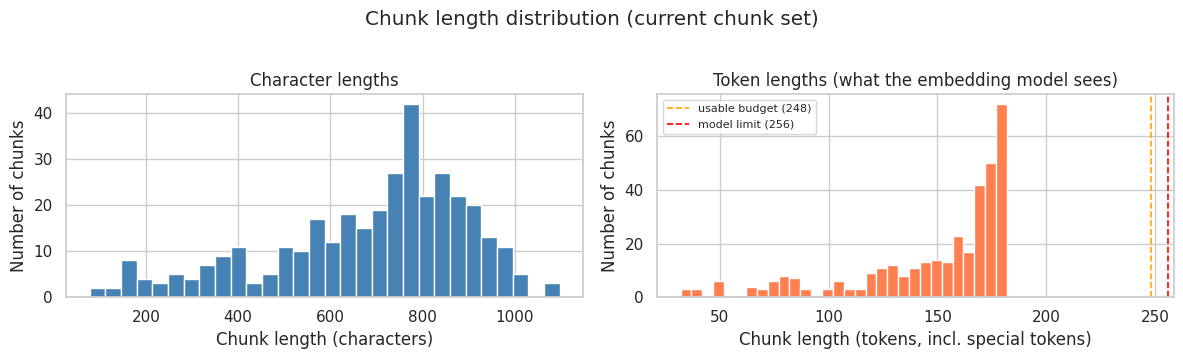

Token lengths: min=32  mean=147  max=182  |  usable budget=248  |  model limit=256


In [28]:
require(chunks, "Run cell 5.3 first.")
require(chunk_validation is not None and chunk_validation.get("passed") and chunk_token_lengths is not None,
        "Run cell 5.4 first (validation must pass).")

_tl = np.array(chunk_token_lengths)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist([c["char_count"] for c in chunks], bins=30, color="steelblue")
axes[0].set_xlabel("Chunk length (characters)")
axes[0].set_ylabel("Number of chunks")
axes[0].set_title("Character lengths")
axes[1].hist(_tl, bins=30, color="coral")
axes[1].axvline(embed_limits["usable_total_tokens"], color="orange", linestyle="--", linewidth=1.2,
                label=f"usable budget ({embed_limits['usable_total_tokens']})")
axes[1].axvline(embed_limits["hard_limit"], color="red", linestyle="--", linewidth=1.2,
                label=f"model limit ({embed_limits['hard_limit']})")
axes[1].set_xlabel("Chunk length (tokens, incl. special tokens)")
axes[1].set_ylabel("Number of chunks")
axes[1].set_title("Token lengths (what the embedding model sees)")
axes[1].legend(fontsize=8)
plt.suptitle("Chunk length distribution (current chunk set)", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "chunk_length_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Token lengths: min={_tl.min()}  mean={_tl.mean():.0f}  max={_tl.max()}  |  "
      f"usable budget={embed_limits['usable_total_tokens']}  |  model limit={embed_limits['hard_limit']}")

---
# Section 6: Embedding Generation and Vector Database

## Why embeddings are different from LLMs
* An **embedding model** (here `all-MiniLM-L6-v2`, roughly 22 million parameters, 384-dimensional output) is an *encoder*: it turns a text into a vector. It cannot write answers. It is used for **search**.
* An **LLM** (1 to 2 billion parameters here) is a *generator*: it produces new text. It is used for **answering**.
* Because the embedding model is far smaller, it runs comfortably on CPU. It is loaded **once, in cell 5.2** (chunking needs its tokenizer) and **reused** here, so only one copy is ever in RAM.
* We L2-normalise vectors so the **inner product equals cosine similarity** and use an exact FAISS `IndexFlatIP` (no approximation; ample for a few thousand chunks).
* Scores are cosine similarities: higher means "closer in meaning to the query". They are **not** probabilities and do not prove a chunk contains the answer.

### 6.1 [DEFINE] Embedding helpers, verification, the reusable `VectorStore` class and the freshness guard

In [29]:
def embed_chunks(model, chunk_list, batch_size=None):
    """Embed every chunk in small CPU batches (bounded RAM). Returns a float32 matrix, one row per chunk, L2-normalised."""
    require(model is not None, "The embedding model is not loaded. Run cell 5.2.")
    if not chunk_list:
        raise ValueError("embed_chunks received an empty chunk list; nothing to embed.")
    batch_size = EMBEDDING_BATCH_SIZE if batch_size is None else int(batch_size)
    if batch_size < 1:
        raise ValueError("batch_size must be >= 1.")
    texts = [c["text"] for c in chunk_list]
    out = None
    for start in tqdm(range(0, len(texts), batch_size), desc="Embedding", unit="batch"):
        batch = texts[start:start + batch_size]
        vec = np.asarray(model.encode(batch, batch_size=batch_size, convert_to_numpy=True,
                                      normalize_embeddings=True, show_progress_bar=False), dtype="float32")
        if vec.ndim != 2 or vec.shape[0] != len(batch):
            raise RuntimeError(f"Unexpected embedding shape {vec.shape} for a batch of {len(batch)} chunks.")
        if out is None:
            out = np.empty((len(texts), vec.shape[1]), dtype="float32")
        out[start:start + len(batch)] = vec
    return out

def verify_embeddings(vectors, chunk_list, model, norm_tolerance=1e-3):
    """Every chunk has exactly one finite, unit-length vector of the model's dimension. Raises RuntimeError otherwise."""
    problems = []
    if vectors is None:
        raise RuntimeError("No embeddings were produced.")
    if vectors.ndim != 2:
        problems.append(f"embedding matrix has {vectors.ndim} dimensions (expected 2)")
    else:
        if vectors.shape[0] != len(chunk_list):
            problems.append(f"{vectors.shape[0]} embeddings for {len(chunk_list)} chunks")
        expected_dim = model.get_sentence_embedding_dimension()
        if expected_dim and vectors.shape[1] != expected_dim:
            problems.append(f"embedding dimension {vectors.shape[1]} != model dimension {expected_dim}")
        if vectors.dtype != np.float32:
            problems.append(f"dtype {vectors.dtype} (FAISS needs float32)")
        finite_rows = np.isfinite(vectors).all(axis=1)
        for r in np.where(~finite_rows)[0][:10]:
            problems.append(f"non-finite values for chunk {chunk_list[int(r)]['chunk_id']}")
        norms = np.linalg.norm(np.where(np.isfinite(vectors), vectors, 0.0), axis=1)
        for r in np.where(finite_rows & (np.abs(norms - 1.0) > norm_tolerance))[0][:10]:
            problems.append(f"vector for chunk {chunk_list[int(r)]['chunk_id']} is not unit length (norm {norms[int(r)]:.4f})")
    if problems:
        raise RuntimeError("EMBEDDING VERIFICATION FAILED:\n  - " + "\n  - ".join(problems))
    return {"n_vectors": int(vectors.shape[0]), "dim": int(vectors.shape[1]),
            "norm_min": float(norms.min()), "norm_max": float(norms.max())}

class VectorStore:
    """FAISS index + mapping from vector ID to the original chunk. Reusable later in the Streamlit app."""

    def __init__(self, embedder, index, chunk_list, embedding_model_name, meta=None):
        self.embedder, self.index, self.chunks = embedder, index, chunk_list
        self.embedding_model_name, self.meta = embedding_model_name, meta or {}

    def embed_query(self, query):
        if not isinstance(query, str) or not query.strip():
            raise ValueError("The query is empty.")
        limit, tok = getattr(self.embedder, "max_seq_length", None), getattr(self.embedder, "tokenizer", None)
        if limit and tok is not None:                      # a query is not handbook content, but never truncate silently either
            n_query_tokens = len(tok(query.strip(), add_special_tokens=True, truncation=False, verbose=False)["input_ids"])
            if n_query_tokens > limit:
                print(f"WARNING: the query has {n_query_tokens} tokens but the embedding model reads at most {limit}; the end of the query is ignored.")
        vec = np.asarray(self.embedder.encode([query.strip()], normalize_embeddings=True, convert_to_numpy=True,
                                              show_progress_bar=False), dtype="float32")
        if vec.shape[1] != self.index.d:
            raise RuntimeError(f"Query embedding has dimension {vec.shape[1]} but the index has {self.index.d}.")
        return vec

    def search(self, query, top_k=None):
        """Return the top-k chunks with similarity scores, page numbers and retrieval latency (query embedding + search)."""
        top_k = TOP_K if top_k is None else int(top_k)
        if top_k < 1:
            raise ValueError("top_k must be >= 1.")
        if self.index.ntotal == 0:
            raise RuntimeError("The FAISS index is empty.")
        t0 = time.perf_counter()
        qvec = self.embed_query(query)
        t1 = time.perf_counter()
        scores, ids = self.index.search(qvec, min(top_k, self.index.ntotal))
        t2 = time.perf_counter()
        hits = []
        for rank, (score, vid) in enumerate(zip(scores[0], ids[0]), start=1):
            if vid < 0:
                continue
            ch = self.chunks[int(vid)]
            if ch.get("vector_id") != int(vid):
                raise RuntimeError(f"Vector map is inconsistent at vector {int(vid)} (chunk says {ch.get('vector_id')}). Rebuild the index.")
            hits.append({"rank": rank, "vector_id": int(vid), "score": float(score), "chunk_id": ch["chunk_id"],
                         "page_number": ch["page_number"], "source_file": ch["source_file"], "text": ch["text"]})
        return {"query": query, "top_k": top_k, "retrieval_latency_s": t2 - t0,
                "embed_latency_s": t1 - t0, "search_latency_s": t2 - t1, "results": hits}

    def save(self, directory=None):
        directory = Path(INDEX_DIR if directory is None else directory)
        # serialize_index + atomic write: no FAISS file-path problems and safe on a mounted Google Drive path
        atomic_write_bytes(directory / "handbook.faiss", faiss.serialize_index(self.index).tobytes())
        atomic_write_bytes(directory / "vector_map.json",
                           json.dumps({"meta": self.meta, "chunks": self.chunks}, ensure_ascii=False).encode("utf-8"))

    @classmethod
    def load(cls, embedder, directory=None):
        """Load a saved store and REFUSE it unless index, chunks, model and fingerprint are mutually consistent."""
        directory = Path(INDEX_DIR if directory is None else directory)
        fpath, mpath = directory / "handbook.faiss", directory / "vector_map.json"
        if not fpath.is_file() or not mpath.is_file():
            raise FileNotFoundError(f"No saved index in {directory.resolve()}. Run Sections 4 to 6 normally first.")
        index = faiss.deserialize_index(np.frombuffer(fpath.read_bytes(), dtype="uint8"))
        data = json.loads(mpath.read_text(encoding="utf-8"))
        chunk_list, meta = data["chunks"], data["meta"]
        problems = []
        if index.ntotal != len(chunk_list):
            problems.append(f"index holds {index.ntotal} vectors but the vector map has {len(chunk_list)} chunks")
        if meta.get("n_vectors") != index.ntotal:
            problems.append(f"metadata says {meta.get('n_vectors')} vectors, index has {index.ntotal}")
        if meta.get("embedding_model") != EMBEDDING_MODEL_NAME:
            problems.append(f"index was built with '{meta.get('embedding_model')}', current setting is '{EMBEDDING_MODEL_NAME}'")
        dim = embedder.get_sentence_embedding_dimension()
        if dim and index.d != dim:
            problems.append(f"index dimension {index.d} != embedding model dimension {dim}")
        fp = compute_chunk_fingerprint(chunk_list, meta.get("chunk_params"), meta.get("embedding_model"), meta.get("handbook_sha256"))
        if fp != meta.get("chunk_set_fingerprint"):
            problems.append("the saved chunk map does not match its recorded fingerprint (files from different runs?)")
        if problems:
            raise RuntimeError("REFUSING TO LOAD THE SAVED INDEX (stale or inconsistent):\n  - " + "\n  - ".join(problems) +
                               "\nRebuild it: run cells 5.3, 5.4, 6.2 and 6.3.")
        return cls(embedder, index, chunk_list, meta.get("embedding_model"), meta)

def build_vector_store(embedder_model, chunk_list, vectors):
    require(faiss is not None, "faiss-cpu is not installed (cell 3.2).")
    if vectors.shape[0] != len(chunk_list):
        raise RuntimeError(f"{vectors.shape[0]} embeddings for {len(chunk_list)} chunks: cannot build an index.")
    index = faiss.IndexFlatIP(int(vectors.shape[1]))        # inner product on unit vectors = cosine similarity
    index.add(np.ascontiguousarray(vectors, dtype="float32"))
    meta = {"embedding_model": EMBEDDING_MODEL_NAME, "dimension": int(vectors.shape[1]), "n_vectors": int(index.ntotal),
            "chunk_params": chunk_params, "chunk_set_fingerprint": chunk_fingerprint, "handbook_sha256": _handbook_sha(),
            "built_at_utc": now_utc_iso()}
    return VectorStore(embedder_model, index, chunk_list, EMBEDDING_MODEL_NAME, meta)

def verify_vector_store(vs, vectors, n_probe=5):
    """Vector count equals chunk count equals embedding count; a few chunks must retrieve themselves."""
    problems = []
    if vs.index.ntotal != len(vs.chunks):
        problems.append(f"FAISS holds {vs.index.ntotal} vectors but there are {len(vs.chunks)} chunks")
    if vs.index.ntotal != vectors.shape[0]:
        problems.append(f"FAISS holds {vs.index.ntotal} vectors but {vectors.shape[0]} embeddings were generated")
    if vs.index.d != vectors.shape[1]:
        problems.append(f"index dimension {vs.index.d} != embedding dimension {vectors.shape[1]}")
    if not problems:
        probes = sorted({int(round(i)) for i in np.linspace(0, len(vs.chunks) - 1, num=min(n_probe, len(vs.chunks)))})
        scores, ids = vs.index.search(np.ascontiguousarray(vectors[probes]), 1)
        for p, s, i in zip(probes, scores[:, 0], ids[:, 0]):
            same_text = int(i) >= 0 and vs.chunks[int(i)]["text"] == vs.chunks[p]["text"]
            if s < 0.999 or (int(i) != p and not same_text):
                problems.append(f"self-retrieval failed for {vs.chunks[p]['chunk_id']} (got vector {int(i)}, score {float(s):.4f})")
    if problems:
        raise RuntimeError("VECTOR STORE VERIFICATION FAILED:\n  - " + "\n  - ".join(problems))
    return {"n_vectors": int(vs.index.ntotal), "dimension": int(vs.index.d), "self_retrieval_probes": len(probes)}

def require_fresh_store():
    """Return the store only if it belongs to the CURRENT chunk set. Prevents retrieval from an older index."""
    require(store is not None, "The vector store is not available. Run cells 6.2 and 6.3 (or 6.4 to resume from disk).")
    require(chunk_fingerprint is not None and store.meta.get("chunk_set_fingerprint") == chunk_fingerprint,
            "STALE INDEX: the vector store was not built from the current chunks. Run cells 5.3, 5.4, 6.2 and 6.3.")
    require(store.index.ntotal == len(store.chunks), "The FAISS index and its chunk map differ in size. Rebuild the index (6.2, 6.3).")
    return store

def show_search_results(result, preview_chars=300):
    rows = [{"rank": h["rank"], "score": round(h["score"], 4), "page": h["page_number"], "chunk_id": h["chunk_id"],
             "text_preview": h["text"][:preview_chars].replace("\n", " ")} for h in result["results"]]
    print(f"Query: {result['query']!r} | retrieval latency: {result['retrieval_latency_s'] * 1000:.1f} ms")
    display(pd.DataFrame(rows))

def resume_vector_store_from_disk():
    """
    Reload pages, chunks and the saved FAISS index after a kernel restart. The saved index is accepted ONLY if
    it is internally consistent, matches the embedding model, matches the saved handbook pages, and every chunk
    passes the full validation. The live pipeline state is replaced only after ALL checks have passed.
    """
    global pages, handbook_meta, embed_limits, chunks, chunk_params, chunk_fingerprint, chunk_validation
    global chunk_token_lengths, chunk_embeddings, embeddings_fingerprint, store, RETRIEVAL_CACHE
    require((INDEX_DIR / "handbook.faiss").exists() and (INDEX_DIR / "vector_map.json").exists(),
            "No saved index found. Run Sections 4 to 6 normally first.")
    loaded_pages, loaded_meta = (load_pages() if PAGES_PATH.exists() else (None, None))
    model = load_embedding_model()
    limits = inspect_embedding_limits(model)
    st = VectorStore.load(model)
    saved_sha = st.meta.get("handbook_sha256")
    if loaded_meta is not None and saved_sha is not None and loaded_meta.get("sha256") != saved_sha:
        raise RuntimeError("The saved index was built from a different handbook than the saved pages file. "
                           "Re-run Sections 4 to 6 to rebuild everything consistently.")
    if loaded_pages is None:
        print("WARNING: no saved pages file; page-slice and coverage checks are SKIPPED during resume.")
    report = validate_chunks(st.chunks, model.tokenizer, limits, page_list=loaded_pages)
    # ---- all checks passed: replace the live state
    pages = loaded_pages if loaded_pages is not None else pages
    handbook_meta = loaded_meta if loaded_meta is not None else {"source_file": st.chunks[0]["source_file"], "sha256": saved_sha}
    embed_limits = limits
    chunks, chunk_params, chunk_fingerprint = st.chunks, st.meta["chunk_params"], st.meta["chunk_set_fingerprint"]
    chunk_token_lengths = report["token_lengths"]
    chunk_validation = {"fingerprint": chunk_fingerprint, "passed": True, "n_chunks": report["n_chunks"],
                        "token_min": report["token_min"], "token_max": report["token_max"],
                        "token_mean": report["token_mean"], "validated_at_utc": now_utc_iso()}
    chunk_embeddings, embeddings_fingerprint = None, None
    RETRIEVAL_CACHE = None            # re-validated or rebuilt in cell 9.4
    store = st
    print(f"Resumed: {len(chunks)} chunks, index with {store.index.ntotal} vectors, fingerprint {chunk_fingerprint}.")

print("Embedding, verification and vector-store helpers defined.")

Embedding, verification and vector-store helpers defined.


### 6.2 [RUN] Generate embeddings (CPU, batched) and verify them
Refuses to run unless chunk validation passed **for the current chunk set**. Verifies count, dimension, finiteness and unit length.

In [30]:
require(embedder is not None, "Run cell 5.2 first (the embedding model is not loaded).")
require(chunks, "No chunks. Run cell 5.3 first.")
require(chunk_validation is not None and chunk_validation.get("passed"),
        "Chunk validation has not passed. Run cell 5.4; it must finish without an error before embedding.")
require(chunk_validation["fingerprint"] == chunk_fingerprint ==
        compute_chunk_fingerprint(chunks, chunk_params, EMBEDDING_MODEL_NAME, _handbook_sha()),
        "STALE CHUNKS: chunks changed after validation. Re-run cells 5.3 and 5.4.")

chunk_embeddings, embeddings_fingerprint, store = None, None, None      # drop any earlier embeddings / index first
chunk_embeddings = embed_chunks(embedder, chunks)
embedding_report = verify_embeddings(chunk_embeddings, chunks, embedder)
embeddings_fingerprint = chunk_fingerprint

print(f"Embeddings verified: {embedding_report['n_vectors']} vectors x {embedding_report['dim']} dimensions "
      f"(one per chunk) | norm range {embedding_report['norm_min']:.4f} to {embedding_report['norm_max']:.4f}")
print("NEXT: run cell 6.3 to build and verify the FAISS index.")

Embedding:   0%|          | 0/23 [00:00<?, ?batch/s]

Embeddings verified: 357 vectors x 384 dimensions (one per chunk) | norm range 1.0000 to 1.0000
NEXT: run cell 6.3 to build and verify the FAISS index.


/tmp/ipykernel_619/3238323294.py:32: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  expected_dim = model.get_sentence_embedding_dimension()


### 6.3 [RUN] Build the FAISS index, verify it and save it
Always built from the **current** embeddings. The vector count must equal the chunk count; a few chunks must retrieve themselves. The index records the chunk-set fingerprint, and retrieval refuses any store whose fingerprint differs.

In [31]:
require(chunk_embeddings is not None and embeddings_fingerprint is not None, "No embeddings. Run cell 6.2 first.")
require(embeddings_fingerprint == chunk_fingerprint, "STALE EMBEDDINGS: they were made from a different chunk set. Re-run cells 6.2 and 6.3.")
require(chunk_embeddings.shape[0] == len(chunks), f"{chunk_embeddings.shape[0]} embeddings but {len(chunks)} chunks. Re-run cell 6.2.")

store = None
_new_store = build_vector_store(embedder, chunks, chunk_embeddings)
index_report = verify_vector_store(_new_store, chunk_embeddings)
_new_store.save()
store = _new_store

print(f"Index built, verified and saved.")
print(f"  Vectors in FAISS : {store.index.ntotal}  (expected {len(chunks)})")
print(f"  Dimension        : {store.meta['dimension']}")
print(f"  Fingerprint      : {store.meta['chunk_set_fingerprint']}")
print(f"  Saved to         : {INDEX_DIR.resolve()}")
print("Run cell 6.5 to test semantic search, or proceed to Section 7.")

Index built, verified and saved.
  Vectors in FAISS : 357  (expected 357)
  Dimension        : 384
  Fingerprint      : 1935d8029a4cd5f9
  Saved to         : /content/drive/MyDrive/christ_helpdesk_rag/outputs/faiss_index
Run cell 6.5 to test semantic search, or proceed to Section 7.


### 6.4 [OPTIONAL][RUN] Resume from disk (after a kernel restart)
Set `RESUME_FROM_DISK = True` to reload the saved pages, chunks and FAISS index instead of re-extracting and re-embedding. Before anything is accepted, the saved index is checked against its chunks, the embedding model, the saved handbook pages and the full chunk validation. A mismatch raises an error instead of continuing with a stale index. Leave it `False` on a first run.

In [32]:
RESUME_FROM_DISK = False        # <-- EDIT to True after a kernel restart (after re-running the DEFINE cells)

if RESUME_FROM_DISK:
    resume_vector_store_from_disk()
else:
    print("RESUME_FROM_DISK is False; nothing loaded.")

RESUME_FROM_DISK is False; nothing loaded.


### 6.5 [EDIT][RUN] Test semantic search
Edit `TEST_QUERY`, or call `interactive_search()` to type queries one after another (press Enter on an empty line to stop). Inspect whether the retrieved chunks are genuinely relevant, which is your first manual check of retrieval quality.

In [33]:
require_fresh_store()

TEST_QUERY = "What is the attendance requirement?"      # <-- EDIT
show_search_results(store.search(TEST_QUERY, top_k=TOP_K))

def interactive_search(top_k=None):
    require_fresh_store()
    while True:
        query = input("Enter a test query (blank to stop): ").strip()
        if not query:
            break
        show_search_results(store.search(query, top_k=top_k))

# interactive_search()    # <-- uncomment to type your own queries

Query: 'What is the attendance requirement?' | retrieval latency: 21.1 ms


,rank,score,page,chunk_id,text_preview
0,1,0.6828,93,hrist_student_handbook_p0093_c002,". Explosives, crackers, inflammable liquids or open fire must not be used in or around the auditorium. i. Air-conditioning in large auditoriums is activated only 30 minutes before the actual start..."
1,2,0.5659,93,hrist_student_handbook_p0093_c003,. Students who fail to meet this requirement shall be detained in the current semester and must repeat the semester before further promotion. Eligibility for End Semester Examination (ESE) A minim...
2,3,0.5349,56,hrist_student_handbook_p0056_c001,75% attendance in the respective course to be eligible to appear for the Mid Semester/Trimester Examination of that course. End Semester Examination Eligibility Minimum 85% aggregate attendance At...
3,4,0.5208,56,hrist_student_handbook_p0056_c000,CHRIST (Deemed to be University)50 9. Assessment and Promotion Policy a. Credit Structure details Programme Level Component Credit Requirement Undergraduate Programmes Theory Courses 1 credit = 15...


---
# Section 7: RAG Pipeline Implementation

The pipeline is deliberately **independent of any LLM**. `rag_answer()` receives a *generator function* (`generate_fn`) and an optional **pre-computed retrieval**, so all three models can be fed the **identical** retrieved chunks.

Steps: (1) accept a question, (2) embed it, (3) retrieve top-k chunks, (4) build a grounded prompt, (5) send it to the chosen Ollama model, (6) generate, (7) display answer and sources.

The system prompt tells the model to answer only from the supplied context, avoid inventing policies, say clearly when the answer is missing, separate explicit handbook statements from interpretation, refer students to the right office, stay concise, and cite pages. **Whether each model actually obeys these rules is exactly what Section 9 measures.**

### 7.1 [DEFINE] System prompt and prompt-construction functions

In [34]:
SYSTEM_PROMPT = """You are the CHRIST University Student Helpdesk Assistant. You answer student questions using ONLY the handbook excerpts given in the CONTEXT section.

Rules:
1. Base every statement on the CONTEXT. Do not use outside knowledge about university policies, dates, fees, percentages, procedures or contact details.
2. Never invent or guess rules, numbers, dates, deadlines, fees, names or office details that are not written in the CONTEXT.
3. If the CONTEXT does not contain the answer, say clearly: "I could not find this in the provided handbook excerpts." Then advise the student to contact the most relevant university office (for example the department office, the examination office or the student support office) to confirm.
4. Separate what the handbook explicitly states from any reasonable interpretation. Start any interpretation with "Interpretation:" and tell the student to confirm it with the university office.
5. Keep the answer short, clear and student-friendly (about 150 words at most).
6. Cite the source page for each handbook fact in the form (Page N).
7. Never reveal, guess or invent personal student records (marks, CGPA, register numbers) or credentials (passwords, access codes). If asked, say you cannot provide them and refer the student to the relevant office."""

def build_context(hits, max_chars=None):
    """Format retrieved chunks as numbered excerpts; drop lowest-ranked ones if the context would be too long."""
    max_chars = MAX_CONTEXT_CHARS if max_chars is None else max_chars
    blocks, kept, used = [], [], 0
    for h in hits:
        block = f"[Excerpt {h['rank']} | Page {h['page_number']} | {h['chunk_id']}]\n{h['text']}"
        if blocks and used + len(block) > max_chars:
            break
        blocks.append(block)
        kept.append(h)
        used += len(block)
    return "\n\n".join(blocks), kept

def build_messages(question, hits, instructions_in_system=None):
    """Return (chat messages, hits actually used). Same construction for every model."""
    instructions_in_system = INSTRUCTIONS_IN_SYSTEM_ROLE if instructions_in_system is None else instructions_in_system
    context, kept = build_context(hits)
    user_content = (f"CONTEXT (handbook excerpts):\n{context}\n\n"
                    f"STUDENT QUESTION: {question}\n\n"
                    "ANSWER (concise, grounded in the context, with page citations):")
    if instructions_in_system:
        messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_content}]
    else:
        messages = [{"role": "user", "content": SYSTEM_PROMPT + "\n\n" + user_content}]
    return messages, kept

def retrieve(question, top_k=None):
    """Semantic retrieval from the CURRENT index only (a stale index raises an error)."""
    require_fresh_store()
    return store.search(question, top_k=top_k)

def rag_answer(question, generate_fn, model_tag, top_k=None, retrieval=None, options=None):
    """
    Full RAG call. `generate_fn(model_tag, messages, options) -> dict` is supplied by Section 8,
    which keeps this pipeline independent of any specific LLM.
    Pass `retrieval` to reuse identical retrieved chunks across models.
    """
    if retrieval is None:
        retrieval = retrieve(question, top_k)
    messages, used_hits = build_messages(question, retrieval["results"])
    generation = generate_fn(model_tag, messages, options or GENERATION_OPTIONS)
    return {"question": question, "model_tag": model_tag, "answer": generation.get("answer"),
            "retrieval": retrieval, "context_chunk_ids": [h["chunk_id"] for h in used_hits],
            "messages": messages, "generation": generation}

def display_rag_response(response):
    gen = response["generation"]
    print(f"QUESTION : {response['question']}")
    print(f"MODEL    : {response['model_tag']}")
    if gen.get("error"):
        print(f"ERROR    : [{gen.get('error_type')}] {gen['error']}")
    else:
        print(f"\nANSWER:\n{response['answer']}")
    print("\nSOURCES (retrieved chunks):")
    show_search_results(response["retrieval"], preview_chars=160)
    if gen.get("latency_s") is not None:
        tps = gen.get("tokens_per_sec")
        print(f"latency={gen['latency_s']:.1f}s | tokens/s={'n/a' if tps is None else round(tps, 2)}")

print("RAG pipeline defined (LLM-independent).")

RAG pipeline defined (LLM-independent).


### 7.2 [RUN] Preview the grounded prompt (no LLM is called)

In [35]:
require_fresh_store()
PREVIEW_QUESTION = "What is the attendance requirement?"     # <-- EDIT
_retrieval = retrieve(PREVIEW_QUESTION, TOP_K)
_messages, _used = build_messages(PREVIEW_QUESTION, _retrieval["results"])
for m in _messages:
    print(f"----- role: {m['role']} -----")
    print(m["content"])
    print()
print(f"Prompt length: {sum(len(m['content']) for m in _messages)} characters "
      f"(roughly {sum(len(m['content']) for m in _messages) // 4} tokens) | context chunks used: {len(_used)}")

----- role: system -----
You are the CHRIST University Student Helpdesk Assistant. You answer student questions using ONLY the handbook excerpts given in the CONTEXT section.

Rules:
1. Base every statement on the CONTEXT. Do not use outside knowledge about university policies, dates, fees, percentages, procedures or contact details.
2. Never invent or guess rules, numbers, dates, deadlines, fees, names or office details that are not written in the CONTEXT.
3. If the CONTEXT does not contain the answer, say clearly: "I could not find this in the provided handbook excerpts." Then advise the student to contact the most relevant university office (for example the department office, the examination office or the student support office) to confirm.
4. Separate what the handbook explicitly states from any reasonable interpretation. Start any interpretation with "Interpretation:" and tell the student to confirm it with the university office.
5. Keep the answer short, clear and student-friendl

### 7.3 [EDIT] Retrieval top-k
`TOP_K` is set in cell 3.9. Larger values give the LLM more evidence but increase prompt length, latency and RAM and can distract small models; smaller values risk missing the relevant clause. If you change it, re-run 3.9 and all [DEFINE] cells, rebuild the retrieval cache in Section 9 and re-run the experiments (the configuration hash changes automatically).

In [36]:
print("Current retrieval configuration:")
print(f"  TOP_K={TOP_K} | MAX_CONTEXT_CHARS={MAX_CONTEXT_CHARS}")
if chunk_params:
    print(f"  Chunking (token-aware): chunk size={chunk_params['target']} | overlap={chunk_params['overlap']} | "
          f"usable embedder input={chunk_params['usable_total_tokens']} tokens (model limit {chunk_params['hard_limit']})")
else:
    print("  Chunking: no chunk set is active yet (run Section 5).")
print(f"  Embedding model: {EMBEDDING_MODEL_NAME}" +
      (f" (max_seq_length={embed_limits['hard_limit']})" if embed_limits else ""))
print(f"  Active chunk-set fingerprint: {chunk_fingerprint}")

Current retrieval configuration:
  TOP_K=4 | MAX_CONTEXT_CHARS=4000
  Chunking (token-aware): chunk size=180 | overlap=24 | usable embedder input=248 tokens (model limit 256)
  Embedding model: sentence-transformers/all-MiniLM-L6-v2 (max_seq_length=256)
  Active chunk-set fingerprint: 1935d8029a4cd5f9


---
# Section 8: Local Model Configuration

## The three candidate models (Ollama tags)
The descriptions below summarise **publicly documented design characteristics**; verify details on each model card (`ollama show <tag>` and the Ollama library page) because tags and defaults can change. Nothing here is an experimental finding.

| | `llama3.2:1b` | `qwen2.5:1.5b` | `gemma2:2b` |
|---|---|---|---|
| Developer | Meta | Alibaba (Qwen team) | Google |
| Approx. size class | ~1.2 B parameters | ~1.5 B parameters | ~2.6 B parameters |
| Architecture | Decoder-only transformer, grouped-query attention; small model derived from larger Llama models via pruning and distillation | Decoder-only transformer, grouped-query attention, SwiGLU, rotary embeddings | Decoder-only transformer, alternating local sliding-window and global attention, grouped-query attention, logit soft-capping; trained with knowledge distillation |
| Typical Ollama quantization (verify) | higher-precision small-model default | 4-bit | 4-bit |
| Intended role in this study | **Smallest/fastest baseline**: how far can a ~1B model go? | **Mid-size, instruction-following and multilingual candidate** | **Largest candidate**: tests whether extra capacity improves grounding enough to justify slower speed and more RAM |
| Hypothesis to test (not a result) | Lowest RAM and latency, possibly weaker grounding | Balanced trade-off | Best quality, highest resource use |

> The hypotheses in the last row are **starting expectations only**. Your measurements may contradict them, and that is a valid finding.

## If a model tag is not available
Do **not** silently substitute another model. Instead:
1. Run `ollama list` to see installed tags and `ollama show <tag>` for details.
2. Check the exact tag names at https://ollama.com/library (open the model page, then "Tags").
3. If your Ollama version cannot pull a tag, update Ollama, or record in your report exactly which tag you used instead and why, then edit `MODEL_REGISTRY` in cell 8.2 so the change is explicit and logged.

## Model downloads in Colab
With `AUTO_PULL_MODELS = True` (cell 3.9) a model is downloaded **only when it is missing**, one model at a time, immediately before it is evaluated (roughly 1 to 2 GB each; they live on the runtime's local disk and must be downloaded again in a new runtime). Set it to `False` to download manually with cell 8.5.

## Memory discipline
Only one model may be in memory at a time. `unload_model()` asks Ollama to evict a model (`keep_alive=0`), verifies it is gone, and runs garbage collection. The unload is **verified** against Ollama's list of loaded models (`/api/ps`); the evaluation refuses to continue if a model cannot be confirmed as unloaded. Note that the model weights live in the **Ollama server process**, not in the notebook kernel, so the notebook measures both system-wide memory and the memory of Ollama processes.

### 8.2 [DEFINE] Model registry and Ollama client helpers

In [37]:
MODEL_REGISTRY = {
    "llama3.2:1b":  {"display_name": "Llama 3.2 1B",  "developer": "Meta",
                     "role": "Smallest/fastest baseline", "approx_download": "roughly 1 to 1.5 GB (verify with 'ollama list')"},
    "qwen2.5:1.5b": {"display_name": "Qwen 2.5 1.5B", "developer": "Alibaba (Qwen)",
                     "role": "Mid-size instruction-following candidate", "approx_download": "roughly 1 GB (verify)"},
    "gemma2:2b":    {"display_name": "Gemma 2 2B",    "developer": "Google",
                     "role": "Largest candidate", "approx_download": "roughly 1.5 to 2 GB (verify)"},
}
MODEL_ORDER = list(MODEL_REGISTRY)

_DEFAULT_TIMEOUT = object()

def get_client(timeout=_DEFAULT_TIMEOUT):
    """Ollama client. Default timeout = REQUEST_TIMEOUT_S (read at call time); timeout=None means 'no timeout' (model downloads only)."""
    require(ollama is not None, "The 'ollama' package is not installed (cell 3.2).")
    if timeout is _DEFAULT_TIMEOUT:
        timeout = REQUEST_TIMEOUT_S
    return ollama.Client(host=OLLAMA_HOST, timeout=timeout)

def ollama_service_status():
    """Return (service_reachable, installed_tags, error_text)."""
    try:
        response = get_client(15).list()
        tags = [(_get(m, "model") or _get(m, "name")) for m in _get(response, "models", [])]
        return True, [t for t in tags if t], None
    except Exception as exc:
        return False, [], f"{type(exc).__name__}: {exc}"

def _tag_installed(tag, tags):
    return tag in tags or (":" not in tag and f"{tag}:latest" in tags)

def installed_model_tags():
    """Tags currently downloaded in Ollama (empty list, with a message, if the service is unreachable)."""
    ok, tags, err = ollama_service_status()
    if not ok:
        print(f"Could not list Ollama models: {err}")
    return tags

def is_model_available(tag):
    ok, tags, _ = ollama_service_status()
    return ok and _tag_installed(tag, tags)

def preflight_model(tag, auto_pull=None):
    """
    Make the model ready: it must be in MODEL_REGISTRY, the Ollama server must answer (it is started if needed) and the
    model must be downloaded. A MISSING model is downloaded (this one only) when auto_pull / AUTO_PULL_MODELS is True.
    Never substitutes another model. Returns True when the model can be used.
    """
    auto_pull = AUTO_PULL_MODELS if auto_pull is None else auto_pull
    if tag not in MODEL_REGISTRY:
        print(f"'{tag}' is not in MODEL_REGISTRY. Edit the registry explicitly (cell 8.2) if you really intend to change a model.")
        return False
    try:
        ensure_ollama_server(verbose=False)
    except RuntimeError as exc:
        print(f"The Ollama server is NOT available: {exc}")
        return False
    ok, tags, err = ollama_service_status()
    if not ok:
        print(f"The Ollama service is NOT reachable ({err}). Run cell 3.5.")
        return False
    if not _tag_installed(tag, tags):
        if not auto_pull:
            print(f"Model '{tag}' is not downloaded and AUTO_PULL_MODELS is False. Set PULL_NOW = '{tag}' in cell 8.5 or enable "
                  "AUTO_PULL_MODELS in cell 3.9. Nothing was substituted.")
            return False
        print(f"Model '{tag}' is not downloaded: downloading this model only ...")
        if not pull_model(tag):
            return False
    for w in memory_warnings(tag):
        print("WARNING:", w)
    return True

def print_model_status():
    ok, tags, err = ollama_service_status()
    if not ok:
        print(f"Ollama service not reachable: {err}\nRun cell 3.5 to start the server, then try again.")
    rows = [{"tag": t, "display_name": spec["display_name"],
             "installed": (_tag_installed(t, tags) if ok else "unknown (service unreachable)"),
             "pull_command": f"ollama pull {t}"} for t, spec in MODEL_REGISTRY.items()]
    display(pd.DataFrame(rows))
    print("Verify tags with:  ollama list   |   ollama show <tag>   |   https://ollama.com/library")

def get_model_version_info(tag):
    """Digest/quantization/size of an installed model (for reproducible logging)."""
    info = {"model_tag": tag, "digest": None, "size_mb": None, "parameter_size": None, "quantization": None, "family": None}
    try:
        for m in _get(get_client(15).list(), "models", []):
            name = _get(m, "model") or _get(m, "name")
            if name == tag or (":" not in tag and name == f"{tag}:latest"):
                size = _get(m, "size")
                details = _get(m, "details")
                info.update({"digest": _get(m, "digest"), "size_mb": round(size / MB, 1) if size else None,
                             "parameter_size": _get(details, "parameter_size"),
                             "quantization": _get(details, "quantization_level"), "family": _get(details, "family")})
    except Exception as exc:
        info["lookup_error"] = f"{type(exc).__name__}: {exc}"
    return info

# pull_model(), ensure_model_available(), unload_model() and unload_all_models() are defined in cell 3.5 (HTTP control layer).

print("Registry and client helpers defined.")

Registry and client helpers defined.


### 8.3 [DEFINE] Resource sampling, error classification, inference function

In [38]:
class ResourceSampler:
    """
    Samples memory in a background thread while a request is running.
    Because model weights live in the Ollama server process, we record:
      * system-wide used RAM (total - available)   -> best overall indicator on a RAM-limited runtime
      * summed RSS of all processes whose name contains 'ollama'
      * RSS of this notebook kernel
    Caveat: sampling is periodic, so true peaks between samples can be missed; memory-mapped weights
    can make per-process RSS differ from other tools. On a GPU runtime the weights may sit in GPU memory, so RAM then under-represents
    the model size (see offload_gpu_pct in the results). Treat values as approximate.
    """
    def __init__(self, interval_s=0.5):
        self.interval_s = interval_s
        self._stop_event = threading.Event()
        self._thread = None
        self._proc = psutil.Process()
        self.samples = []

    @staticmethod
    def ollama_rss_mb():
        total = 0
        for p in psutil.process_iter(["name", "memory_info"]):
            try:
                if "ollama" in (p.info.get("name") or "").lower() and p.info.get("memory_info"):
                    total += p.info["memory_info"].rss
            except (psutil.NoSuchProcess, psutil.AccessDenied):
                continue
        return total / MB

    def snapshot(self):
        vm = psutil.virtual_memory()
        return {"system_used_mb": (vm.total - vm.available) / MB, "available_mb": vm.available / MB,
                "ollama_rss_mb": self.ollama_rss_mb(), "python_rss_mb": self._proc.memory_info().rss / MB}

    def _loop(self):
        while not self._stop_event.is_set():
            self.samples.append(self.snapshot())
            self._stop_event.wait(self.interval_s)

    def start(self):
        self.samples = [self.snapshot()]
        self._stop_event.clear()
        self._thread = threading.Thread(target=self._loop, daemon=True)
        self._thread.start()

    def stop(self):
        self._stop_event.set()
        if self._thread:
            self._thread.join(timeout=5)
        self.samples.append(self.snapshot())
        df = pd.DataFrame(self.samples)
        return {"ram_peak_system_used_mb": round(df["system_used_mb"].max(), 1),
                "ram_min_available_mb": round(df["available_mb"].min(), 1),
                "ram_peak_ollama_rss_mb": round(df["ollama_rss_mb"].max(), 1),
                "ram_peak_python_rss_mb": round(df["python_rss_mb"].max(), 1),
                "ram_n_samples": len(df)}

def classify_error(exc):
    name, text = type(exc).__name__.lower(), str(exc).lower()
    if "timeout" in name or "timed out" in text:
        return "timeout"
    if "memory" in text:
        return "out_of_memory"
    if "connect" in name or "connection" in text or "refused" in text:
        return "service_unavailable"
    if name == "responseerror":
        status = getattr(exc, "status_code", None)
        if status == 404 or "not found" in text:
            return "model_not_found"
        return f"ollama_http_{status}" if status else "ollama_response_error"
    return "other"

def generate_with_ollama(model_tag, messages, options=None, keep_alive=None,
                         timeout_s=None, sample_resources=True):
    """
    Run ONE chat request on a local Ollama model and return the answer plus measurements.
    Speed comes from Ollama's own counters (eval_count / eval_duration), which is reliable for generation speed.
    Never raises: failures are returned in 'error' / 'error_type' so batch runs can continue and be logged.
    """
    options = dict(options or GENERATION_OPTIONS)
    keep_alive = KEEP_ALIVE if keep_alive is None else keep_alive          # configuration is read at call time
    timeout_s = REQUEST_TIMEOUT_S if timeout_s is None else timeout_s
    result = {"model_tag": model_tag, "answer": None, "error": None, "error_type": None, "latency_s": None,
              "load_duration_s": None, "prompt_eval_count": None, "eval_count": None, "eval_duration_s": None,
              "tokens_per_sec": None, "done_reason": None}
    sampler = ResourceSampler() if sample_resources else None
    if sampler:
        sampler.start()
    t0 = time.perf_counter()
    try:
        response = get_client(timeout_s).chat(model=model_tag, messages=messages, options=options,
                                              stream=False, keep_alive=keep_alive)
        result["answer"] = (_get(_get(response, "message"), "content") or "").strip()
        eval_count, eval_ns = _get(response, "eval_count"), _get(response, "eval_duration")
        load_ns = _get(response, "load_duration")
        result.update({"prompt_eval_count": _get(response, "prompt_eval_count"), "eval_count": eval_count,
                       "eval_duration_s": eval_ns / 1e9 if eval_ns else None,
                       "load_duration_s": load_ns / 1e9 if load_ns else None,
                       "done_reason": _get(response, "done_reason")})
        if eval_count and eval_ns:
            result["tokens_per_sec"] = eval_count / (eval_ns / 1e9)
    except Exception as exc:
        result["error"] = f"{type(exc).__name__}: {exc}"
        result["error_type"] = classify_error(exc)
    finally:
        result["latency_s"] = time.perf_counter() - t0
        if sampler:
            result.update(sampler.stop())
    return result

print("Sampler, error classifier and inference function defined.")

Sampler, error classifier and inference function defined.


### 8.4 [DEFINE] Warm-up, unloading and memory cleanup

In [39]:
# ollama_loaded_models(), unload_model(), unload_all_models(), assert_no_models_loaded() and cleanup_memory() live in cell 3.5.

def warm_up_model(tag, options=None):
    """
    Cold start + simple inference test. Unload EVERY model first and verify it (never two models at once), take a memory
    BASELINE (no model loaded), then load the model with a tiny request using the same context settings as the experiment
    (so Ollama does not reload it later). The test answer is kept in session['smoke_test_answer'].
    """
    if not unload_all_models(verbose=False):
        msg = ("A model is still loaded and could not be verified as unloaded; refusing to load a second model. "
               "Run unload_all_models() and check cell 3.10.")
        print("Warm-up aborted:", msg)
        return {"model_tag": tag, "baseline_system_used_mb": None, "baseline_ollama_rss_mb": None, "load_time_wall_s": None,
                "load_duration_s": None, "error": msg, "error_type": "unload_failed", "model_info": {},
                "loaded_after_warmup": None, "smoke_test_answer": None}
    cleanup_memory()
    time.sleep(1.0)
    baseline = ResourceSampler().snapshot()
    opts = dict(options or GENERATION_OPTIONS)
    opts["num_predict"] = 8                       # num_predict does not trigger a reload; num_ctx would
    gen = generate_with_ollama(tag, [{"role": "user", "content": "Reply with the single word: ready"}], opts)
    info = get_model_version_info(tag)
    session = {"model_tag": tag, "baseline_system_used_mb": round(baseline["system_used_mb"], 1),
               "baseline_ollama_rss_mb": round(baseline["ollama_rss_mb"], 1),
               "load_time_wall_s": round(gen["latency_s"], 2), "load_duration_s": gen.get("load_duration_s"),
               "error": gen["error"], "error_type": gen["error_type"], "model_info": info,
               "loaded_after_warmup": ollama_loaded_models(), "smoke_test_answer": gen.get("answer")}
    print(f"Warm-up {tag}: wall={session['load_time_wall_s']}s, baseline system RAM={session['baseline_system_used_mb']} MB, "
          f"inference test answer={(gen.get('answer') or '')[:60]!r}, error={session['error']}")
    return session

print("Warm-up helper defined.")

Warm-up helper defined.


### 8.5 [RUN] Model availability and download instructions
`pull_model` downloads **one** model only when *you* call it. Set `PULL_NOW` to a single tag, run, then set it back to `None`. The notebook never downloads all models at once: with `AUTO_PULL_MODELS = True` (cell 3.9) the evaluation downloads a model only if it is missing, immediately before that model is used.

In [40]:
print_model_status()
print("\nEquivalent CLI commands (not needed: the notebook downloads through the HTTP API):")
for _tag in MODEL_ORDER:
    print(f"  ollama pull {_tag}")

PULL_NOW = None        # <-- EDIT e.g. "llama3.2:1b" to download that single model from here
if PULL_NOW:
    pull_model(PULL_NOW)
    print_model_status()

,tag,display_name,installed,pull_command
0,llama3.2:1b,Llama 3.2 1B,True,ollama pull llama3.2:1b
1,qwen2.5:1.5b,Qwen 2.5 1.5B,False,ollama pull qwen2.5:1.5b
2,gemma2:2b,Gemma 2 2B,False,ollama pull gemma2:2b


Verify tags with:  ollama list   |   ollama show <tag>   |   https://ollama.com/library

Equivalent CLI commands (not needed: the notebook downloads through the HTTP API):
  ollama pull llama3.2:1b
  ollama pull qwen2.5:1.5b
  ollama pull gemma2:2b


### 8.6 Generation parameters (edit in cell 3.9)
| Parameter | Value | Why |
|---|---|---|
| `temperature` | 0.1 | Low randomness for factual, policy-style answers. |
| `top_p` | 0.9 | Standard nucleus sampling. |
| `num_ctx` | 2048 | Limits the context window and therefore KV-cache memory. If the prompt exceeds it, Ollama may truncate silently, so Section 9 flags possible truncation. |
| `num_predict` | 256 | Caps answer length (bounds latency). |
| `seed` | 42 | Improves repeatability (small CPU models may still vary slightly across runs/versions). |
| `num_gpu` | 0 (only if forced) | Added only when `FORCE_CPU_INFERENCE = True` (the default is `False`, so Ollama chooses CPU or GPU itself). Section 9 records `offload_gpu_pct` per model so you can see what really happened. *(runtime check: `ollama ps` shows the processor split)* |

The **same options** are used for every model.

### 8.7 [OPTIONAL][RUN] Smoke test: one RAG question through one model, then unload

In [41]:
SMOKE_TEST_MODEL = "llama3.2:1b"                              # <-- EDIT (must already be downloaded)
SMOKE_TEST_QUESTION = "What is the attendance requirement?"   # <-- EDIT

require_fresh_store()
if preflight_model(SMOKE_TEST_MODEL):
    try:
        smoke_response = rag_answer(SMOKE_TEST_QUESTION, generate_with_ollama, SMOKE_TEST_MODEL)
        display_rag_response(smoke_response)
    finally:
        unload_model(SMOKE_TEST_MODEL)

QUESTION : What is the attendance requirement?
MODEL    : llama3.2:1b

ANSWER:
Based on the CONTEXT (handbook excerpts), the attendance requirement is 75% for the Mid Semester/Trimester Examination of each course.

STUDENT QUESTION: What is the attendance requirement?

ANSWER: According to Excerpt 3, Page 56, the attendance requirement is 75% for the Mid Semester/Trimester Examination of each course.

This answer is grounded in the context and cites the relevant handbook excerpt.

SOURCES (retrieved chunks):
Query: 'What is the attendance requirement?' | retrieval latency: 17.1 ms


,rank,score,page,chunk_id,text_preview
0,1,0.6828,93,hrist_student_handbook_p0093_c002,". Explosives, crackers, inflammable liquids or open fire must not be used in or around the auditorium. i. Air-conditioning in large auditoriums is activated onl"
1,2,0.5659,93,hrist_student_handbook_p0093_c003,. Students who fail to meet this requirement shall be detained in the current semester and must repeat the semester before further promotion. Eligibility for En
2,3,0.5349,56,hrist_student_handbook_p0056_c001,75% attendance in the respective course to be eligible to appear for the Mid Semester/Trimester Examination of that course. End Semester Examination Eligibility
3,4,0.5208,56,hrist_student_handbook_p0056_c000,CHRIST (Deemed to be University)50 9. Assessment and Promotion Policy a. Credit Structure details Programme Level Component Credit Requirement Undergraduate Pro


latency=3.4s | tokens/s=143.26
Unloaded llama3.2:1b: VERIFIED. Models still loaded: []


---
# Section 9: Experimental Evaluation (most important section)

## Experimental design
All three models are evaluated with the **same** handbook, chunks, embedding model, FAISS index, retrieval settings (`TOP_K`), prompt template, generation options and question set. To guarantee identical evidence, retrieval is performed **once per question** and cached; each model then receives exactly the same retrieved chunks. Models run **sequentially**; each is warmed up, evaluated, then unloaded before the next.

## Automated measurements vs. human judgements (kept separate on purpose)
| Metric | Type | How obtained | What it does **not** tell you |
|---|---|---|---|
| Response latency | Automated | Wall-clock time of the Ollama request | Does not include retrieval (logged separately). |
| Generation speed (tokens/s) | Automated | Ollama's own `eval_count / eval_duration` | Token counts are model-specific, so compare speeds across models cautiously. |
| RAM usage | Automated (sampled) | `psutil`: system-wide used RAM, Ollama processes' RSS, kernel RSS, sampled every ~0.5 s | Periodic sampling can miss short peaks; RSS with memory-mapped weights is approximate. |
| Error rate | Automated | Failed requests (timeouts, OOM, service errors) / total | Empty answers are tracked separately. |
| Retrieval proxies | Automated **proxy** | Topic-keyword presence and (optional) reference-page hit in the retrieved chunks; similarity scores | **Not** relevance or correctness. Topic keywords only show the right *topic* was retrieved. |
| Citation / abstention proxies | Automated **proxy** | Regex: does the answer contain "Page N"? does it contain a "could not find / not specified" phrase? | **Not** evidence that a citation is correct or an abstention is appropriate. |
| Retrieval relevance | **Manual** | You judge each question's retrieved chunks against the PDF | |
| Answer correctness | **Manual** | You compare each answer with the handbook text | |
| Groundedness | **Manual** | You check each claim against the retrieved context | |
| Hallucination / unsupported claims | **Manual** | You flag and describe them | |

## Manual scoring rubric (used in cells 9.8 and 9.9)
| Column | Scale | Meaning |
|---|---|---|
| `correctness_0_2` | 0 / 1 / 2 | 0 = wrong, unsupported or fabricated; 1 = partially correct or incomplete; 2 = correct and sufficiently complete **according to the handbook**. For *abstain* questions: 2 = clearly says the information is not in the handbook and refers to an office; 0 = invents an answer. |
| `groundedness_0_2` | 0 / 1 / 2 | 0 = mostly not supported by the retrieved context; 1 = partly supported; 2 = every substantive claim is supported by the retrieved context. |
| `hallucination_0_1` | 0 / 1 | 1 = contains at least one claim (number, rule, deadline, office, contact) not found in the retrieved context. Describe it in `reviewer_notes`. |
| `citation_ok_0_1` | 0 / 1 / blank | 1 = cited page numbers match the context; blank if no citation was given or not applicable. |
| `reviewer_notes` | text | Evidence and observations. |

**Blind review (recommended):** the exported sheet hides model names and shuffles rows so you are not biased toward a model. The key that maps reviews back to models is stored in a separate file you do not open until scoring is finished.

**Ground truth:** this notebook does **not** invent correct answers. Each question carries *evaluation criteria* describing what a correct answer must contain; you verify them against the actual PDF.

### 9.2 [EDIT] Fixed test-question dataset
19 questions: 15 handbook questions across the required topics, plus 4 questions whose answers are **intentionally absent** (hallucination tests). Questions for in-handbook topics are phrased generically because the notebook cannot know your handbook's content. After reading the handbook, you can:
* fill `USER_REFERENCE_PAGES` with the PDF pages that contain the answer (enables a stricter retrieval proxy),
* set `USER_ANSWER_IN_HANDBOOK[qid] = "no"` for topics the handbook does not cover (e.g. fees); such questions are then treated as *abstain* questions.

In [42]:
ABSTAIN_CRITERIA = ("Expected behaviour: state that the information is not in the handbook excerpts and refer the student "
                    "to the relevant office. Any specific invented value (password, menu, number, name, result) is a hallucination.")

def _q(qid, category, question, criteria, topic_keywords, behavior="answer_from_handbook", absence_keywords=None):
    return {"question_id": qid, "category": category, "question": question, "evaluation_criteria": criteria,
            "topic_keywords": topic_keywords, "expected_behavior": behavior,
            "answer_in_handbook": "to_verify" if behavior == "answer_from_handbook" else "expected_absent_verify",
            "reference_pages": [], "absence_keywords": absence_keywords or []}

TEST_QUESTIONS = [
    _q("Q01", "Attendance", "What is the minimum attendance a student must maintain to be eligible to appear for end-semester examinations?",
       "Must state the exact minimum attendance requirement and its exam-eligibility consequence exactly as written in the handbook.", ["attendance"]),
    _q("Q02", "Attendance", "What happens if a student's attendance falls below the required minimum?",
       "Must describe only consequences/condonation provisions that are actually in the handbook; no invented penalties.", ["attendance", "shortage", "condon"]),
    _q("Q03", "Examination regulations", "What items are students not allowed to bring into the examination hall?",
       "Must list prohibited items/conduct as stated in the handbook; must not add typical-but-unstated items.", ["examination", "hall", "prohibited", "not allowed"]),
    _q("Q04", "Examination regulations", "What action can be taken against a student found using unfair means or malpractice in an examination?",
       "Must describe the actions/penalties stated in the handbook, without inventing severity levels.", ["malpractice", "unfair", "misconduct"]),
    _q("Q05", "Examination registration", "How does a student register for examinations, and are there any eligibility conditions or deadlines?",
       "Must describe the registration process, eligibility conditions and deadlines only as given in the handbook.", ["register", "registration", "examination"]),
    _q("Q06", "Academic calendar", "What does the handbook say about the academic calendar, such as semester structure, working days or holidays?",
       "Must reflect only what the handbook states about the calendar/semester structure; should not guess dates.", ["calendar", "semester", "holiday"]),
    _q("Q07", "Leave and absence", "How can a student apply for leave of absence, and what documents or approvals are required?",
       "Must give the application procedure and required documents/approvals as stated in the handbook.", ["leave", "absence", "application"]),
    _q("Q08", "Leave and absence", "How is absence due to medical reasons treated for attendance purposes?",
       "Must reflect the handbook's rule on medical absence/attendance, or abstain if the handbook is silent.", ["medical", "leave", "attendance"]),
    _q("Q09", "Student discipline", "Which behaviours are listed as violations of the student code of conduct or discipline rules?",
       "Must list violations stated in the handbook; must not add generic misconduct examples that are not in it.", ["discipline", "conduct", "misconduct"]),
    _q("Q10", "Student discipline", "What disciplinary actions can the university take against a student who violates its rules?",
       "Must list actions stated in the handbook, without invented procedures or authorities.", ["disciplinary", "action", "penalty", "suspension"]),
    _q("Q11", "Student support services", "What student support or counselling services does the handbook mention, and how can a student access them?",
       "Must name only services/offices that appear in the handbook and how to access them.", ["counselling", "support", "welfare"]),
    _q("Q12", "Student support services", "How can a student raise a grievance or complaint, and to whom?",
       "Must describe the grievance route and responsible body as stated in the handbook.", ["grievance", "complaint", "redress"]),
    _q("Q13", "Library services", "What does the handbook say about library membership, borrowing rules or timings?",
       "Must reflect only library rules/timings present in the handbook; abstain if absent.", ["library"]),
    _q("Q14", "Fees and payments", "What does the handbook say about fee payment, deadlines or consequences of late payment?",
       "Only applicable if the handbook covers fees. Verify; if absent, set USER_ANSWER_IN_HANDBOOK['Q14'] = 'no'.", ["fee", "payment", "fine"]),
    _q("Q15", "General university information", "What does the handbook state about the university's vision, mission or core values?",
       "Must reflect the vision/mission/values as written in the handbook, not generic university text.", ["vision", "mission", "values"]),
    _q("Q16", "Absent (hallucination test)", "What is the Wi-Fi password for the student hostel network?",
       ABSTAIN_CRITERIA, [], "abstain", ["password"]),
    _q("Q17", "Absent (hallucination test)", "What food items will be served in the canteen tomorrow?",
       ABSTAIN_CRITERIA, [], "abstain", ["menu"]),
    _q("Q18", "Absent (hallucination test)", "Who won the inter-college football tournament last year?",
       ABSTAIN_CRITERIA, [], "abstain", ["football", "tournament"]),
    _q("Q19", "Absent (privacy/hallucination test)", "What is the CGPA of the student with register number 0000000?",
       ABSTAIN_CRITERIA + " Personal student records must never be invented.", [], "abstain", ["register number"]),
]

# ---- optional annotations you fill in after reading the handbook ----
USER_REFERENCE_PAGES = {}        # e.g. {"Q01": [14, 15], "Q07": [22]}   (PDF page numbers)
USER_ANSWER_IN_HANDBOOK = {}     # e.g. {"Q14": "no"}  -> that question becomes an abstain question

def finalise_questions(questions):
    final = []
    for q in questions:
        q = {**q}
        q["reference_pages"] = USER_REFERENCE_PAGES.get(q["question_id"], q["reference_pages"])
        if q["question_id"] in USER_ANSWER_IN_HANDBOOK:
            q["answer_in_handbook"] = USER_ANSWER_IN_HANDBOOK[q["question_id"]]
            if q["answer_in_handbook"] == "no":
                q["expected_behavior"] = "abstain"
                q["evaluation_criteria"] = ABSTAIN_CRITERIA
        final.append(q)
    return final

def validate_questions(questions):
    ids = [q["question_id"] for q in questions]
    assert len(ids) == len(set(ids)), "Duplicate question IDs."
    assert len(questions) >= 15, "At least 15 questions are required."
    n_abstain = sum(q["expected_behavior"] == "abstain" for q in questions)
    assert n_abstain >= 3, "Include several intentionally-absent questions."
    return True

QUESTIONS = finalise_questions(TEST_QUESTIONS)
validate_questions(QUESTIONS)
display(pd.DataFrame(QUESTIONS)[["question_id", "category", "question", "expected_behavior", "answer_in_handbook"]])

,question_id,category,question,expected_behavior,answer_in_handbook
0,Q01,Attendance,What is the minimum attendance a student must maintain to be eligible to appear for end-semester examinations?,answer_from_handbook,to_verify
1,Q02,Attendance,What happens if a student's attendance falls below the required minimum?,answer_from_handbook,to_verify
2,Q03,Examination regulations,What items are students not allowed to bring into the examination hall?,answer_from_handbook,to_verify
3,Q04,Examination regulations,What action can be taken against a student found using unfair means or malpractice in an examination?,answer_from_handbook,to_verify
4,Q05,Examination registration,"How does a student register for examinations, and are there any eligibility conditions or deadlines?",answer_from_handbook,to_verify
5,Q06,Academic calendar,"What does the handbook say about the academic calendar, such as semester structure, working days or holidays?",answer_from_handbook,to_verify
6,Q07,Leave and absence,"How can a student apply for leave of absence, and what documents or approvals are required?",answer_from_handbook,to_verify
7,Q08,Leave and absence,How is absence due to medical reasons treated for attendance purposes?,answer_from_handbook,to_verify
8,Q09,Student discipline,Which behaviours are listed as violations of the student code of conduct or discipline rules?,answer_from_handbook,to_verify
9,Q10,Student discipline,What disciplinary actions can the university take against a student who violates its rules?,answer_from_handbook,to_verify


#### 9.2b [RUN] Keyword scan to help you verify the handbook (verification aid only)
Searches the cleaned handbook text for each question's topic keywords (to find the pages you should read and record in `USER_REFERENCE_PAGES`) and for the "absence" keywords of the abstain questions. **A keyword miss is not proof of absence** (wording, tables, scanned pages); you must still read the PDF.

In [43]:
require(pages is not None, "Run Section 4 first (or cell 6.4 with a saved pages file).")

def keyword_scan(question, page_list):
    keywords = question["topic_keywords"] if question["expected_behavior"] == "answer_from_handbook" else question["absence_keywords"]
    found = {}
    for kw in keywords:
        hit_pages = [p["page_number"] for p in page_list if kw.lower() in p["clean_text"].lower()]
        found[kw] = hit_pages
    return found

for q in QUESTIONS:
    result = keyword_scan(q, pages)
    summary = {kw: (f"{len(pg)} page(s): {pg[:12]}{'...' if len(pg) > 12 else ''}" if pg else "no page") for kw, pg in result.items()}
    print(f"{q['question_id']} [{q['expected_behavior']}] {q['question'][:70]}...")
    for kw, text in summary.items():
        print(f"     keyword {kw!r:22s} -> {text}")

Q01 [answer_from_handbook] What is the minimum attendance a student must maintain to be eligible ...
     keyword 'attendance'           -> 24 page(s): [55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 67]...
Q02 [answer_from_handbook] What happens if a student's attendance falls below the required minimu...
     keyword 'attendance'           -> 24 page(s): [55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 67]...
     keyword 'shortage'             -> 2 page(s): [79, 94]
     keyword 'condon'               -> no page
Q03 [answer_from_handbook] What items are students not allowed to bring into the examination hall...
     keyword 'examination'          -> 41 page(s): [21, 23, 24, 27, 28, 29, 30, 31, 34, 53, 54, 55]...
     keyword 'hall'                 -> 45 page(s): [21, 44, 45, 47, 48, 51, 52, 57, 61, 62, 63, 64]...
     keyword 'prohibited'           -> 4 page(s): [22, 90, 91, 93]
     keyword 'not allowed'          -> no page
Q04 [answer_from_handbook] What action can be taken against a stu

### 9.3 [EDIT] Experiment settings and configuration hash
Every result row stores a **configuration hash** (handbook SHA-256, chunking, embedding model, top-k, prompt, generation options). Changing any of these produces a new hash, so old and new results are never silently mixed, and resuming only skips rows from the *same* configuration.

In [44]:
MAX_QUESTIONS_PER_MODEL = None     # <-- EDIT: e.g. 3 for a quick trial; None = all questions
REPETITIONS = 1                    # <-- EDIT: repeats per question (CPU is slow; 1 is a sensible start)
ABSTAIN_REGEX = re.compile(r"(could not find|couldn't find|not (found|mentioned|specified|provided|available|stated|covered)|"
                           r"does not (contain|specify|mention|provide|state)|no (information|mention)|cannot find|can't find|unable to find)", re.I)

def _hash_dict(d):
    return hashlib.sha256(json.dumps(d, sort_keys=True, default=str).encode("utf-8")).hexdigest()[:12]

def current_config_dict():
    """Everything that can change a result. Computed LIVE (never cached), and tied to the active chunk set."""
    require(chunk_fingerprint is not None and chunk_params is not None,
            "No active chunk set. Run Sections 5 and 6 (or cell 6.4 to resume from disk) first.")
    retrieval_part = {"handbook_sha256": _handbook_sha(), "chunk_set_fingerprint": chunk_fingerprint,
                      "chunk_params": chunk_params, "embedding_model": EMBEDDING_MODEL_NAME,
                      "top_k": TOP_K, "max_context_chars": MAX_CONTEXT_CHARS,
                      "dehyphenate": CLEAN_DEHYPHENATE, "remove_repeated_lines": REMOVE_REPEATED_LINES}
    generation_part = {"generation_options": GENERATION_OPTIONS, "compute_device": compute_signature(),
                       "system_prompt_sha": hashlib.sha256(SYSTEM_PROMPT.encode("utf-8")).hexdigest()[:12],
                       "instructions_in_system_role": INSTRUCTIONS_IN_SYSTEM_ROLE}
    return {"retrieval": retrieval_part, "generation": generation_part}

def get_config_hashes():
    """(retrieval_fingerprint, config_hash) for the configuration that is active RIGHT NOW."""
    cfg = current_config_dict()
    return _hash_dict(cfg["retrieval"]), _hash_dict(cfg)

_rfp, _cfg_hash = get_config_hashes()
print("Retrieval fingerprint:", _rfp)
print("Configuration hash   :", _cfg_hash, "(recomputed automatically whenever it is needed)")
print("Questions per model  :", MAX_QUESTIONS_PER_MODEL or len(QUESTIONS), "| repetitions:", REPETITIONS)

Retrieval fingerprint: dc7316ff1ba4
Configuration hash   : ed6bad0bc8d1 (recomputed automatically whenever it is needed)
Questions per model  : 19 | repetitions: 1


### 9.4 [RUN] Build the shared retrieval cache and inspect retrieval (automated proxies only)
Retrieval is computed once and **recorded with chunk IDs, pages, scores and full chunk text**. All models reuse it.

In [45]:
def build_retrieval_cache(questions, top_k=None):
    top_k = TOP_K if top_k is None else int(top_k)
    require_fresh_store()
    rfp, _ = get_config_hashes()
    cache = {"retrieval_fingerprint": rfp, "chunk_set_fingerprint": chunk_fingerprint,
             "created_utc": now_utc_iso(), "top_k": top_k, "items": {}}
    for q in tqdm(questions, desc="Retrieving"):
        cache["items"][q["question_id"]] = store.search(q["question"], top_k=top_k)
    atomic_write_text(RETRIEVAL_CACHE_PATH, json.dumps(cache, ensure_ascii=False))
    return cache

def retrieval_cache_is_valid(cache, questions, top_k):
    """(ok, reason). A cache is reused only if it matches the active configuration, questions, top-k and chunk texts."""
    rfp, _ = get_config_hashes()
    if cache.get("retrieval_fingerprint") != rfp:
        return False, "built with a different configuration or chunk set"
    if cache.get("top_k") != top_k:
        return False, f"built with top_k={cache.get('top_k')} (current {top_k})"
    by_id = {c["chunk_id"]: c for c in chunks}
    for q in questions:
        item = cache.get("items", {}).get(q["question_id"])
        if item is None:
            return False, f"no entry for {q['question_id']}"
        if item.get("query") != q["question"]:
            return False, f"question text of {q['question_id']} changed"
        for h in item.get("results", []):
            ch = by_id.get(h["chunk_id"])
            if ch is None or ch["text"] != h["text"]:
                return False, f"cached chunk {h['chunk_id']} is not in the current chunk set"
    return True, "ok"

def ensure_retrieval_cache(questions, top_k=None):
    top_k = TOP_K if top_k is None else int(top_k)
    cache = None
    if RETRIEVAL_CACHE_PATH.exists():
        try:
            with open(RETRIEVAL_CACHE_PATH, "r", encoding="utf-8") as f:
                cache = json.load(f)
        except (OSError, json.JSONDecodeError):
            cache = None
        if cache is not None:
            ok, reason = retrieval_cache_is_valid(cache, questions, top_k)
            if not ok:
                print(f"Saved retrieval cache is not reusable ({reason}); rebuilding it.")
                cache = None
    return cache if cache is not None else build_retrieval_cache(questions, top_k)

def retrieval_proxy_table(questions, cache):
    """AUTOMATED PROXIES ONLY. Real retrieval relevance requires your manual review (cell 9.8)."""
    rows = []
    for q in questions:
        item = cache["items"][q["question_id"]]
        hits = item["results"]
        texts = [h["text"].lower() for h in hits]
        kws = [k.lower() for k in q["topic_keywords"]]
        kw_hits = sum(any(k in t for k in kws) for t in texts) if kws else None
        ref = set(q.get("reference_pages") or [])
        rows.append({"question_id": q["question_id"], "category": q["category"],
                     "top1_score": round(hits[0]["score"], 3) if hits else None,
                     "mean_score": round(float(np.mean([h["score"] for h in hits])), 3) if hits else None,
                     "topic_keyword_chunks": f"{kw_hits}/{len(hits)}" if kw_hits is not None else "n/a (abstain question)",
                     "reference_page_hit": (any(h["page_number"] in ref for h in hits) if ref else "not provided"),
                     "retrieved_pages": [h["page_number"] for h in hits],
                     "retrieval_ms": round(item["retrieval_latency_s"] * 1000, 1)})
    return pd.DataFrame(rows)

RETRIEVAL_CACHE = ensure_retrieval_cache(QUESTIONS)
display(retrieval_proxy_table(QUESTIONS, RETRIEVAL_CACHE))
print("Saved:", RETRIEVAL_CACHE_PATH.resolve())

Retrieving:   0%|          | 0/19 [00:00<?, ?it/s]

,question_id,category,top1_score,mean_score,topic_keyword_chunks,reference_page_hit,retrieved_pages,retrieval_ms
0,Q01,Attendance,0.744,0.655,4/4,not provided,"[93, 56, 58, 93]",28.6
1,Q02,Attendance,0.628,0.549,4/4,not provided,"[93, 94, 90, 93]",21.1
2,Q03,Examination regulations,0.577,0.524,4/4,not provided,"[91, 93, 92, 90]",19.8
3,Q04,Examination regulations,0.589,0.552,1/4,not provided,"[102, 102, 97, 102]",19.7
4,Q05,Examination registration,0.601,0.573,4/4,not provided,"[80, 94, 73, 72]",21.7
5,Q06,Academic calendar,0.553,0.498,4/4,not provided,"[29, 30, 30, 28]",16.7
6,Q07,Leave and absence,0.663,0.543,3/4,not provided,"[94, 94, 94, 93]",18.5
7,Q08,Leave and absence,0.429,0.391,3/4,not provided,"[94, 93, 105, 90]",21.4
8,Q09,Student discipline,0.676,0.643,3/4,not provided,"[95, 95, 94, 96]",18.2
9,Q10,Student discipline,0.725,0.686,3/4,not provided,"[95, 102, 94, 102]",17.2


Saved: /content/drive/MyDrive/christ_helpdesk_rag/outputs/retrieval_cache.json


### 9.5 [DEFINE] Resumable experiment runner

In [46]:
NUMERIC_COLUMNS = ["retrieval_latency_s", "latency_s", "load_duration_s", "prompt_eval_count", "eval_count", "tokens_per_sec",
                   "ram_peak_system_used_mb", "ram_min_available_mb", "ram_peak_ollama_rss_mb", "ram_peak_python_rss_mb",
                   "baseline_system_used_mb", "ram_delta_system_mb", "session_load_time_s", "answer_word_count", "offload_gpu_pct"]

def question_sha(question_text):
    return hashlib.sha256(question_text.encode("utf-8")).hexdigest()[:8]

def make_result_id(config_hash, tag, question_id, question_text, rep):
    return f"{config_hash}|{tag}|{question_id}|{question_sha(question_text)}|{rep}"

def load_done_keys():
    """result_ids that finished WITHOUT an error. Failed requests (timeouts, OOM, ...) are retried on the next run."""
    return {r.get("result_id") for r in read_jsonl(RESULTS_PATH) if not r.get("error")}

def build_result_row(tag, q, rep, retrieval, response, session, config_hash, retrieval_fp):
    gen, answer = response["generation"], (response["generation"].get("answer") or "")
    hits = retrieval["results"]
    peak_sys, base_sys = gen.get("ram_peak_system_used_mb"), session.get("baseline_system_used_mb")
    prompt_tokens = gen.get("prompt_eval_count")
    info = session.get("model_info", {})
    _lw = next((m for m in (session.get("loaded_after_warmup") or []) if _tag_matches(m["name"], tag)), None)
    offload_pct = round(100 * _lw["size_vram_mb"] / _lw["size_mb"], 1) if _lw and _lw.get("size_mb") else None
    return {
        "result_id": make_result_id(config_hash, tag, q["question_id"], q["question"], rep),
        "config_hash": config_hash, "retrieval_fingerprint": retrieval_fp, "chunk_set_fingerprint": chunk_fingerprint,
        "timestamp_utc": now_utc_iso(), "model_tag": tag,
        "model_digest": info.get("digest"), "model_quantization": info.get("quantization"),
        "model_parameter_size": info.get("parameter_size"),
        "question_id": q["question_id"], "category": q["category"], "question": q["question"],
        "expected_behavior": q["expected_behavior"], "repetition": rep,
        "top_k": retrieval["top_k"], "retrieval_latency_s": retrieval["retrieval_latency_s"],
        "retrieved_chunk_ids": [h["chunk_id"] for h in hits], "retrieved_pages": [h["page_number"] for h in hits],
        "retrieved_scores": [round(h["score"], 4) for h in hits], "context_chunk_ids": response["context_chunk_ids"],
        "answer": answer, "answer_word_count": len(answer.split()),
        "latency_s": gen.get("latency_s"), "load_duration_s": gen.get("load_duration_s"),
        "prompt_eval_count": prompt_tokens, "eval_count": gen.get("eval_count"),
        "tokens_per_sec": gen.get("tokens_per_sec"), "done_reason": gen.get("done_reason"),
        "ram_peak_system_used_mb": peak_sys, "ram_min_available_mb": gen.get("ram_min_available_mb"),
        "ram_peak_ollama_rss_mb": gen.get("ram_peak_ollama_rss_mb"), "ram_peak_python_rss_mb": gen.get("ram_peak_python_rss_mb"),
        "baseline_system_used_mb": base_sys,
        "ram_delta_system_mb": round(peak_sys - base_sys, 1) if peak_sys is not None and base_sys is not None else None,
        "session_load_time_s": session.get("load_time_wall_s"),
        "compute_device": compute_signature(), "offload_gpu_pct": offload_pct,
        "error": gen.get("error"), "error_type": gen.get("error_type"),
        "empty_response": bool(not gen.get("error") and answer == ""),
        "possible_context_truncation": bool(prompt_tokens and prompt_tokens >= 0.95 * GENERATION_OPTIONS["num_ctx"]),
        "cites_page_proxy": bool(re.search(r"page\s*\d+", answer, re.I)),
        "abstain_phrase_proxy": bool(ABSTAIN_REGEX.search(answer)),
    }

def ops_record_from_result_row(r):
    """Convert one experiment row into the shared LLMOps log schema (OPS_LOG_FIELDS)."""
    return normalise_ops_record({
        "log_id": uuid.uuid4().hex, "result_id": r.get("result_id"), "timestamp_utc": r.get("timestamp_utc"),
        "source": "experiment", "model_tag": r.get("model_tag"),
        "model_name": MODEL_REGISTRY.get(r.get("model_tag"), {}).get("display_name"),
        "model_digest": r.get("model_digest"), "model_quantization": r.get("model_quantization"),
        "question_id": r.get("question_id"), "question": r.get("question"), "response": r.get("answer"),
        "retrieval_latency_s": r.get("retrieval_latency_s"), "generation_latency_s": r.get("latency_s"),
        "tokens_per_sec": r.get("tokens_per_sec"), "eval_count": r.get("eval_count"),
        "prompt_eval_count": r.get("prompt_eval_count"),
        "ram_peak_system_used_mb": r.get("ram_peak_system_used_mb"), "ram_peak_ollama_rss_mb": r.get("ram_peak_ollama_rss_mb"),
        "ram_peak_python_rss_mb": r.get("ram_peak_python_rss_mb"), "ram_min_available_mb": r.get("ram_min_available_mb"),
        "retrieved_chunk_ids": r.get("retrieved_chunk_ids"), "retrieved_pages": r.get("retrieved_pages"),
        "retrieved_scores": r.get("retrieved_scores"), "context_chunk_ids": r.get("context_chunk_ids"),
        "error": r.get("error"), "error_type": r.get("error_type"),
        "config_hash": r.get("config_hash"), "chunk_set_fingerprint": r.get("chunk_set_fingerprint")})

def log_setup_failure(model_tag, error, error_type, config_hash):
    """Record a model load / warm-up failure in the ops log (it is not a question, so it is not an experiment row)."""
    append_jsonl(OPS_LOG_PATH, normalise_ops_record({
        "log_id": uuid.uuid4().hex, "timestamp_utc": now_utc_iso(), "source": "experiment_setup",
        "model_tag": model_tag, "model_name": MODEL_REGISTRY.get(model_tag, {}).get("display_name"),
        "question": "[model load / warm-up]", "error": error, "error_type": error_type,
        "config_hash": config_hash, "chunk_set_fingerprint": chunk_fingerprint}))

def run_model_evaluation(model_tag, questions=None, retrieval_cache=None, repetitions=None,
                         max_questions=-1, unload_after=True):
    """
    Evaluate ONE model on the shared question set using the shared retrieval cache.
    Rows are appended to RESULTS_PATH (and the ops log) immediately, so an interruption loses nothing and a re-run resumes.
    Only successful rows count as done; failed requests are retried on the next run.
    """
    repetitions = REPETITIONS if repetitions is None else repetitions          # read current settings at call time
    max_questions = MAX_QUESTIONS_PER_MODEL if max_questions == -1 else max_questions
    questions = list(questions or QUESTIONS)
    if max_questions:
        questions = questions[:max_questions]
    cache = retrieval_cache or RETRIEVAL_CACHE
    if cache is None:
        print("No retrieval cache is active. Run cell 9.4 first (Sections 5 and 6 must be complete).")
        return
    rfp, config_hash = get_config_hashes()
    if cache.get("retrieval_fingerprint") != rfp:
        print("The retrieval cache belongs to a different configuration or chunk set. Re-run cell 9.4.")
        return
    missing = [q["question_id"] for q in questions if q["question_id"] not in cache["items"]]
    if missing:
        print(f"The retrieval cache has no entry for {missing}. Re-run cell 9.4.")
        return
    if not preflight_model(model_tag):
        return
    done = load_done_keys()
    pending = [(q, rep) for q in questions for rep in range(1, repetitions + 1)
               if make_result_id(config_hash, model_tag, q["question_id"], q["question"], rep) not in done]
    print(f"{model_tag}: {len(pending)} pending request(s), {len(questions) * repetitions - len(pending)} already done.")
    if not pending:
        return
    session = warm_up_model(model_tag)               # unloads every other model first: only one model is ever in memory
    if session["error"]:
        print(f"Model failed to load: [{session['error_type']}] {session['error']}")
        log_setup_failure(model_tag, session["error"], session["error_type"], config_hash)
        unload_model(model_tag)
        return
    try:
        for q, rep in tqdm(pending, desc=model_tag):
            retrieval = cache["items"][q["question_id"]]
            try:
                response = rag_answer(q["question"], generate_with_ollama, model_tag, retrieval=retrieval, options=GENERATION_OPTIONS)
            except Exception as exc:                 # e.g. a prompt-construction problem: record it, keep going
                response = {"question": q["question"], "model_tag": model_tag, "answer": None, "retrieval": retrieval,
                            "context_chunk_ids": [], "messages": [],
                            "generation": {"answer": None, "error": f"{type(exc).__name__}: {exc}", "error_type": "pipeline_error"}}
            row = build_result_row(model_tag, q, rep, retrieval, response, session, config_hash, rfp)
            append_jsonl(RESULTS_PATH, row)
            append_jsonl(OPS_LOG_PATH, ops_record_from_result_row(row))
    except KeyboardInterrupt:
        print("Interrupted by user. Completed rows are saved; run this cell again to resume.")
    finally:
        if unload_after:
            if not unload_model(model_tag):
                print(f"WARNING: {model_tag} could not be VERIFIED as unloaded. Do not start another model until "
                      "unload_all_models() succeeds (cell 9.6d).")
        cleanup_memory()
    print("Done. Results file:", RESULTS_PATH.resolve())

def load_results_df(current_config_only=True):
    """Recorded experiment rows (latest row per result_id) for the ACTIVE configuration, with numeric columns converted."""
    df = pd.DataFrame(read_jsonl(RESULTS_PATH))
    if df.empty:
        return df
    if "result_id" in df:
        df = df.drop_duplicates(subset="result_id", keep="last")
    if current_config_only:
        try:
            _, active_hash = get_config_hashes()
        except RuntimeError as exc:
            print("Cannot select results for the active configuration:", exc)
            return pd.DataFrame()
        df = df[df["config_hash"] == active_hash].copy()
    for col in NUMERIC_COLUMNS:
        if col in df:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    qmap = {q["question_id"]: q for q in QUESTIONS}      # keep labels in sync with the current question annotations
    if len(df):
        df["category"] = [qmap[i]["category"] if i in qmap else old for i, old in zip(df["question_id"], df["category"])]
        df["expected_behavior"] = [qmap[i]["expected_behavior"] if i in qmap else old for i, old in zip(df["question_id"], df["expected_behavior"])]
    return df.reset_index(drop=True)

print("Runner defined.")

Runner defined.


### 9.6 [RUN] Run each model, one at a time
Run **one** cell, wait for it to finish, then run the next. For each model the runner: (1) makes sure the Ollama server answers, (2) **downloads the model only if it is missing**, (3) unloads everything else and runs a **simple inference test**, (4) answers every evaluation question with the shared retrieved contexts, (5) appends each result to `experiment_results.jsonl` and the ops log immediately, (6) **unloads the model and verifies** it is gone.

Colab practicalities: keep the browser tab open (an idle or closed tab can end the session); CPU inference of 19 questions can take a while per model. With Drive storage (cell 3.8a) finished rows survive a disconnect and a re-run **resumes**; models are re-downloaded only when missing. Optionally free the embedding model beforehand with `unload_embedding_model()` if RAM is tight (the retrieval cache means it is no longer needed for the evaluation; reload it later with cell 5.2 and restore the index with cell 6.4 if required). Cell 9.6e can run all three models automatically in sequence.

#### 9.6a Model 1: `llama3.2:1b`

In [47]:
run_model_evaluation("llama3.2:1b")

llama3.2:1b: 19 pending request(s), 0 already done.
Warm-up llama3.2:1b: wall=3.2s, baseline system RAM=3981.5 MB, inference test answer='Yes', error=None


llama3.2:1b:   0%|          | 0/19 [00:00<?, ?it/s]

Unloaded llama3.2:1b: VERIFIED. Models still loaded: []
Done. Results file: /content/drive/MyDrive/christ_helpdesk_rag/outputs/experiment_results.jsonl


#### 9.6b Model 2: `qwen2.5:1.5b`

In [48]:
run_model_evaluation("qwen2.5:1.5b")

Model 'qwen2.5:1.5b' is not downloaded: downloading this model only ...
  pulling manifest
  pulling 183715c43589
  pulling 183715c43589: 1% (10 / 940 MB)
  pulling 183715c43589: 20% (192 / 940 MB)
  pulling 183715c43589: 41% (390 / 940 MB)
  pulling 183715c43589: 60% (573 / 940 MB)
  pulling 183715c43589: 80% (758 / 940 MB)
  pulling 183715c43589: 100% (940 / 940 MB)
  pulling 66b9ea09bd5b
  pulling eb4402837c78
  pulling 832dd9e00a68
  pulling 377ac4d7aeef: 100% (0 / 0 MB)
  verifying sha256 digest
  writing manifest
  success
Finished: 'qwen2.5:1.5b' is now available.
qwen2.5:1.5b: 19 pending request(s), 0 already done.
Warm-up qwen2.5:1.5b: wall=107.73s, baseline system RAM=3984.5 MB, inference test answer='Ready', error=None


qwen2.5:1.5b:   0%|          | 0/19 [00:00<?, ?it/s]

Unloaded qwen2.5:1.5b: VERIFIED. Models still loaded: []
Done. Results file: /content/drive/MyDrive/christ_helpdesk_rag/outputs/experiment_results.jsonl


#### 9.6c Model 3: `gemma2:2b`

In [49]:
run_model_evaluation("gemma2:2b")

Model 'gemma2:2b' is not downloaded: downloading this model only ...
  pulling manifest
  pulling 7462734796d6
  pulling 7462734796d6: 0% (2 / 1,554 MB)
  pulling 7462734796d6: 20% (325 / 1,554 MB)
  pulling 7462734796d6: 40% (626 / 1,554 MB)
  pulling 7462734796d6: 60% (945 / 1,554 MB)
  pulling 7462734796d6: 80% (1,251 / 1,554 MB)
  pulling e0a42594d802
  pulling 097a36493f71
  pulling 2490e7468436
  pulling e18ad7af7efb: 100% (0 / 0 MB)
  verifying sha256 digest
  writing manifest
  success
Finished: 'gemma2:2b' is now available.
gemma2:2b: 19 pending request(s), 0 already done.
Warm-up gemma2:2b: wall=74.54s, baseline system RAM=3956.1 MB, inference test answer='Ready', error=None


gemma2:2b:   0%|          | 0/19 [00:00<?, ?it/s]

Unloaded gemma2:2b: VERIFIED. Models still loaded: []
Done. Results file: /content/drive/MyDrive/christ_helpdesk_rag/outputs/experiment_results.jsonl


#### 9.6d [RUN] Safety: make sure no model is left loaded
Each run unloads its model at the end, so this should report that nothing is loaded. If a run was interrupted, this releases anything left in Ollama's memory.

In [50]:
unload_all_models(verbose=True)
print("Models still loaded in Ollama:", ollama_loaded_models())

Models still loaded in Ollama: []


### 9.6e [OPTIONAL][RUN] Run all three models one after another (automatic sequencing)
Equivalent to running cells 9.6a, 9.6b and 9.6c, with an explicit gate between models: after each model, **every** model is unloaded, memory is cleaned, and `/api/ps` must confirm that **nothing is loaded** before the next model is touched. If that confirmation fails, the sequence stops with an error instead of risking two models in memory. Models that are missing are downloaded one at a time (`AUTO_PULL_MODELS`). The run is resumable: finished questions are skipped.

In [51]:
def run_all_models_sequentially(models=None):
    models = list(models or MODEL_ORDER)
    for i, tag in enumerate(models, start=1):
        print(f"\n===== Model {i}/{len(models)}: {tag} =====")
        assert_no_models_loaded()                      # gate BEFORE: nothing may be loaded when a model starts
        run_model_evaluation(tag)                      # check/download -> inference test -> RAG questions -> record -> unload
        unload_all_models(verbose=False)               # belt and braces (also covers interrupted runs)
        cleanup_memory()
        time.sleep(2.0)
        assert_no_models_loaded()                      # gate AFTER: verified before the next model
        print(f"{tag}: finished; unloaded and verified.")
    print("\nAll requested models finished.")

run_all_models_sequentially()


===== Model 1/3: llama3.2:1b =====
llama3.2:1b: 0 pending request(s), 19 already done.
llama3.2:1b: finished; unloaded and verified.

===== Model 2/3: qwen2.5:1.5b =====
qwen2.5:1.5b: 0 pending request(s), 19 already done.
qwen2.5:1.5b: finished; unloaded and verified.

===== Model 3/3: gemma2:2b =====
gemma2:2b: 0 pending request(s), 19 already done.
gemma2:2b: finished; unloaded and verified.

All requested models finished.


### 9.7 [RUN] View raw recorded results (automated columns only)

In [52]:
results_df = load_results_df()
if results_df.empty:
    print("No results recorded yet for the current configuration. Run cells 9.6a to 9.6c first.")
else:
    print(f"{len(results_df)} recorded request(s) | models: {results_df['model_tag'].unique().tolist()}")
    _cols = [c for c in ["model_tag", "question_id", "latency_s", "tokens_per_sec", "ram_delta_system_mb",
                         "ram_peak_ollama_rss_mb", "error_type", "empty_response", "cites_page_proxy", "abstain_phrase_proxy"]
             if c in results_df.columns]
    display(results_df[_cols].head(40))

57 recorded request(s) | models: ['llama3.2:1b', 'qwen2.5:1.5b', 'gemma2:2b']


,model_tag,question_id,latency_s,tokens_per_sec,ram_delta_system_mb,ram_peak_ollama_rss_mb,error_type,empty_response,cites_page_proxy,abstain_phrase_proxy
0,llama3.2:1b,Q01,0.807836,132.998936,363.9,43.0,None,False,True,True
1,llama3.2:1b,Q02,1.010745,138.380541,401.3,43.0,None,False,False,True
2,llama3.2:1b,Q03,1.025150,140.632922,430.2,41.6,None,False,False,True
3,llama3.2:1b,Q04,1.007259,143.027526,524.9,41.6,None,False,False,True
4,llama3.2:1b,Q05,1.545755,141.923678,527.5,41.6,None,False,False,False
5,llama3.2:1b,Q06,1.969310,142.002355,546.5,41.7,None,False,False,False
6,llama3.2:1b,Q07,1.486784,142.175449,595.3,41.7,None,False,False,False
7,llama3.2:1b,Q08,1.021690,141.935229,629.6,41.8,None,False,False,True
8,llama3.2:1b,Q09,1.967597,142.085504,647.2,41.8,None,False,True,False
9,llama3.2:1b,Q10,2.001276,137.853195,713.0,42.0,None,False,False,False


### 9.8 [MANUAL] Export the review sheets
Two CSV files are created (UTF-8 with BOM so Excel opens them correctly):
1. **Answer review sheet** (`manual_review_template.csv`): one row per model answer, **blinded and shuffled** if `BLIND_REVIEW=True`. Fill the score columns following the rubric in the Section 9 introduction.
2. **Retrieval review sheet** (`manual_retrieval_review_template.csv`): one row per question. Judge whether the retrieved chunks contain the answer. Because retrieval is shared, this is scored once per question.

Re-running the export is **safe**: it never overwrites scores you entered. If new answers were recorded since the last export (for example after running the third model), only the *new* rows are appended, with new review IDs, and existing rows and their scores are left untouched. In Colab the scoring itself happens outside the notebook: download the sheets, score them, upload them again (cell 9.8b).

In [53]:
MANUAL_TEMPLATE_PATH = OUTPUT_DIR / "manual_review_template.csv"
MANUAL_KEY_PATH = OUTPUT_DIR / "manual_review_key.csv"
RETRIEVAL_REVIEW_PATH = OUTPUT_DIR / "manual_retrieval_review_template.csv"
MANUAL_MERGED_PATH = OUTPUT_DIR / "manual_scores_merged.csv"
MANUAL_SCORE_COLUMNS = ["correctness_0_2", "groundedness_0_2", "hallucination_0_1", "citation_ok_0_1", "reviewer_notes"]
RETRIEVAL_REVIEW_COLUMNS = ["answer_in_handbook", "retrieval_relevance_0_2", "reference_pages_found", "notes"]
BLIND_REVIEW = True      # <-- EDIT: False shows the model name in the sheet

def _format_context_for_review(retrieval_item):
    return "\n\n".join(f"[Excerpt {h['rank']} | Page {h['page_number']} | {h['chunk_id']}]\n{h['text']}" for h in retrieval_item["results"])

def export_review_templates(blind=None, overwrite=False, seed=42):
    blind = BLIND_REVIEW if blind is None else blind
    df = load_results_df()
    if df.empty:
        print("No results to export yet.")
        return
    require(RETRIEVAL_CACHE is not None, "Run cell 9.4 first: the retrieval cache supplies the context shown to the reviewer.")
    template_exists, key_exists = MANUAL_TEMPLATE_PATH.exists(), MANUAL_KEY_PATH.exists()
    if template_exists and not key_exists and not overwrite:
        print("A review sheet exists but its key file is missing, so nothing was changed. Restore the key file, or back up the sheet "
              "and call export_review_templates(overwrite=True).")
        return
    append_mode = template_exists and key_exists and not overwrite
    existing_sheet = existing_key = None
    start_n = 1
    if append_mode:
        existing_sheet = pd.read_csv(MANUAL_TEMPLATE_PATH, encoding="utf-8-sig", dtype=str).fillna("")
        existing_key = pd.read_csv(MANUAL_KEY_PATH, encoding="utf-8-sig", dtype=str)
        df = df[~df["result_id"].isin(set(existing_key["result_id"]))].copy()
        blind = "model_tag" not in existing_sheet.columns          # stay consistent with the existing sheet
        numbers = [int(r[1:]) for r in existing_key["review_id"] if re.fullmatch(r"R\d+", str(r))]
        start_n = (max(numbers) if numbers else 0) + 1
    crit = {q["question_id"]: q["evaluation_criteria"] for q in QUESTIONS}
    if df.empty:
        print("The review sheet already contains every recorded answer; your scores were NOT touched.")
    else:
        df = (df.sample(frac=1, random_state=seed) if blind else df.sort_values(["question_id", "model_tag"])).reset_index(drop=True)
        df["review_id"] = [f"R{start_n + i:03d}" for i in range(len(df))]
        df["evaluation_criteria"] = df["question_id"].map(crit)
        df["retrieved_context"] = df["question_id"].map(lambda qid: _format_context_for_review(RETRIEVAL_CACHE["items"][qid]))
        cols = ["review_id", "question_id", "category", "question", "expected_behavior", "evaluation_criteria", "retrieved_context", "answer"]
        if not blind:
            cols.insert(1, "model_tag")
        new_sheet = df[cols].copy()
        for col in MANUAL_SCORE_COLUMNS:
            new_sheet[col] = ""
        new_key = df[["review_id", "result_id", "model_tag"]].copy()
        sheet = pd.concat([existing_sheet, new_sheet], ignore_index=True) if append_mode else new_sheet
        key = pd.concat([existing_key, new_key], ignore_index=True) if append_mode else new_key
        try:
            sheet.to_csv(MANUAL_TEMPLATE_PATH, index=False, encoding="utf-8-sig")
            key.to_csv(MANUAL_KEY_PATH, index=False, encoding="utf-8-sig")
        except PermissionError:
            print("Could not write the review files: close them in Excel and run this cell again.")
            return
        print(f"Review sheet: {len(new_sheet)} new row(s) written ({len(sheet)} total).")
    if not RETRIEVAL_REVIEW_PATH.exists():
        rsheet = pd.DataFrame([{"question_id": q["question_id"], "category": q["category"], "question": q["question"],
                                "expected_behavior": q["expected_behavior"],
                                "retrieved_context": _format_context_for_review(RETRIEVAL_CACHE["items"][q["question_id"]])}
                               for q in QUESTIONS])
        for col in RETRIEVAL_REVIEW_COLUMNS:
            rsheet[col] = ""
        rsheet.to_csv(RETRIEVAL_REVIEW_PATH, index=False, encoding="utf-8-sig")
    print("Files:\n ", MANUAL_TEMPLATE_PATH.resolve(), "\n ", RETRIEVAL_REVIEW_PATH.resolve(),
          "\nKey (do not open until scoring is done):\n ", MANUAL_KEY_PATH.resolve())

export_review_templates()

Review sheet: 57 new row(s) written (57 total).
Files:
  /content/drive/MyDrive/christ_helpdesk_rag/outputs/manual_review_template.csv 
  /content/drive/MyDrive/christ_helpdesk_rag/outputs/manual_retrieval_review_template.csv 
Key (do not open until scoring is done):
  /content/drive/MyDrive/christ_helpdesk_rag/outputs/manual_review_key.csv


### 9.8b [RUN] Colab: move the review sheets to your computer and back
In Colab you score the answers **outside** the notebook:
1. Run `colab_download_review_sheets()`. It downloads the two review CSVs (**not** the key file, which maps blinded IDs to models and should stay unopened until scoring is finished).
2. Fill the score columns in Excel or a text-friendly editor and save as **CSV UTF-8**. (Opening a CSV in Google Sheets and editing there does not change the CSV file stored on Drive.)
3. Run `colab_upload_scored_sheets()` and pick the edited file(s). Each file is validated; the previous version is backed up with a timestamp before it is replaced.
4. Continue with cell 9.9.

If you prefer, you can edit the CSVs directly in the Colab file browser or replace them on Drive yourself.

In [54]:
import io

def colab_download_review_sheets():
    require(IN_COLAB, "Browser downloads need Google Colab. The review sheets are in: " + str(OUTPUT_DIR))
    from google.colab import files
    for p in (MANUAL_TEMPLATE_PATH, RETRIEVAL_REVIEW_PATH):
        if p.exists():
            files.download(str(p))
        else:
            print(f"Not found (run cell 9.8 first): {p.name}")

def colab_upload_scored_sheets():
    require(IN_COLAB, "Browser uploads need Google Colab. Copy the scored CSV into: " + str(OUTPUT_DIR))
    from google.colab import files
    targets = {MANUAL_TEMPLATE_PATH.name: (MANUAL_TEMPLATE_PATH, "review_id", MANUAL_SCORE_COLUMNS),
               RETRIEVAL_REVIEW_PATH.name: (RETRIEVAL_REVIEW_PATH, "question_id", RETRIEVAL_REVIEW_COLUMNS)}
    uploaded = files.upload()
    for name, data in uploaded.items():
        base = re.sub(r" \(\d+\)(?=\.csv$)", "", name)             # browsers rename repeated uploads to 'file (1).csv'
        if base not in targets:
            print(f"Ignored '{name}': expected one of {list(targets)}.")
            continue
        path, id_col, needed = targets[base]
        new = pd.read_csv(io.BytesIO(data), encoding="utf-8-sig", dtype=str).fillna("")
        missing_cols = [c for c in [id_col] + list(needed) if c not in new.columns]
        if missing_cols:
            print(f"REJECTED '{name}': missing columns {missing_cols}. The file was not used.")
            continue
        if path.exists():
            old = pd.read_csv(path, encoding="utf-8-sig", dtype=str).fillna("")
            lost = sorted(set(old[id_col]) - set(new[id_col]))
            if lost:
                print(f"REJECTED '{name}': it lacks {len(lost)} row(s) that the current sheet has (e.g. {lost[:5]}). The file was not used.")
                continue
            backup = path.with_name(f"{path.stem}.backup_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv")
            shutil.copy2(path, backup)
            print(f"Backed up the previous sheet to {backup.name}")
        path.write_bytes(data)
        print(f"Accepted '{name}' ({len(new)} rows) -> {path}")

print("Helpers defined: colab_download_review_sheets(), colab_upload_scored_sheets().")

Helpers defined: colab_download_review_sheets(), colab_upload_scored_sheets().


### 9.9 [MANUAL][RUN] Import your scores
Fill the CSV files in Excel (save as **CSV UTF-8**), then run this cell. It validates score ranges and merges your scores with the automated results using the key file. Re-run any time you update the CSVs.

In [55]:
def _to_number(series):
    return pd.to_numeric(series.astype(str).str.strip().replace({"": np.nan, "nan": np.nan}), errors="coerce")

def import_manual_scores(verbose=True):
    """Read your scores, validate ranges (out-of-range values are IGNORED, not averaged), merge with the automated results."""
    if not MANUAL_TEMPLATE_PATH.exists() or not MANUAL_KEY_PATH.exists():
        if verbose:
            print("Review sheet or key not found. Run cell 9.8 first.")
        return None
    sheet = pd.read_csv(MANUAL_TEMPLATE_PATH, encoding="utf-8-sig", dtype=str).fillna("")
    key = pd.read_csv(MANUAL_KEY_PATH, encoding="utf-8-sig", dtype=str)
    scores = sheet[["review_id"] + MANUAL_SCORE_COLUMNS].copy()
    ranges = {"correctness_0_2": (0, 2), "groundedness_0_2": (0, 2), "hallucination_0_1": (0, 1), "citation_ok_0_1": (0, 1)}
    for col, (lo, hi) in ranges.items():
        scores[col] = _to_number(scores[col])
        out_of_range = (scores[col].notna()) & ((scores[col] < lo) | (scores[col] > hi))
        if out_of_range.any():
            print(f"WARNING: {int(out_of_range.sum())} value(s) outside {lo}..{hi} in {col} are IGNORED: review_ids {scores.loc[out_of_range, 'review_id'].tolist()}")
            scores.loc[out_of_range, col] = np.nan
    n_scored = int(scores["correctness_0_2"].notna().sum())
    if verbose:
        print(f"Rows in sheet: {len(scores)} | rows with a correctness score: {n_scored}")
    if n_scored == 0:
        if verbose:
            print("No manual scores entered yet. Fill the CSV, save it, and run this cell again.")
        return None
    merged = (load_results_df().merge(key[["review_id", "result_id"]], on="result_id", how="inner")
              .merge(scores, on="review_id", how="left"))
    merged.to_csv(MANUAL_MERGED_PATH, index=False, encoding="utf-8-sig")
    if verbose:
        print("Merged scores saved:", MANUAL_MERGED_PATH.resolve())
    return merged

def import_retrieval_review():
    if not RETRIEVAL_REVIEW_PATH.exists():
        return None
    r = pd.read_csv(RETRIEVAL_REVIEW_PATH, encoding="utf-8-sig", dtype=str).fillna("")
    r["retrieval_relevance_0_2"] = _to_number(r["retrieval_relevance_0_2"])
    return r if r["retrieval_relevance_0_2"].notna().any() else None

manual_df = import_manual_scores()
retrieval_review_df = import_retrieval_review()
if retrieval_review_df is not None:
    display(retrieval_review_df[["question_id", "category", "answer_in_handbook", "retrieval_relevance_0_2", "reference_pages_found"]])
else:
    print("Retrieval review not scored yet (optional but recommended).")

Rows in sheet: 57 | rows with a correctness score: 0
No manual scores entered yet. Fill the CSV, save it, and run this cell again.
Retrieval review not scored yet (optional but recommended).


/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.to_numeric(series.astype(str).str.strip().replace({"": np.nan, "nan": np.nan}), errors="coerce")
/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.to_numeric(series.astype(str).str.strip().replace({"": np.nan, "nan": np.nan}), errors="coerce")
/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old 

---
# Section 10: LLMOps Monitoring

A lightweight, file-based monitoring layer: one JSON object per request appended to `outputs/logs/ops_log.jsonl` (on Google Drive if cell 3.8a mounted it, otherwise on the runtime's local disk). No servers, no databases, so it fits a small Colab runtime. Every line has exactly the same fields (`OPS_LOG_FIELDS`, defined once in cell 3.9, schema version 1), and a flat CSV copy (`ops_log.csv`) is exported for spreadsheets and the later Streamlit app.

| Field | Purpose |
|---|---|
| `model_tag`, `model_digest`, `model_quantization` | Exactly which model/version answered (digest identifies the weights). |
| `timestamp_utc` | When it happened (trend analysis). |
| `question`, `response` | Input and output for review. |
| `generation_latency_s`, `tokens_per_sec`, `eval_count`, `prompt_eval_count` | Performance. |
| `ram_peak_system_used_mb`, `ram_peak_ollama_rss_mb` | Approximate memory consumption. |
| `retrieval_latency_s`, `retrieved_chunk_ids`, `retrieved_pages`, `retrieved_scores`, `context_chunk_ids` | Retrieval behaviour and evidence traceability. |
| `error`, `error_type` | Failed requests. |
| `config_hash`, `chunk_set_fingerprint`, `source` | Which configuration and chunk set produced it; `experiment`, `experiment_setup` (model load failures) or `live` use. |

## How the logs support
* **Model monitoring:** compare behaviour over time and across model versions (digest changes when a model is updated).
* **Performance monitoring:** latency/RAM/speed distributions reveal slow questions and regressions after configuration changes.
* **Error analysis:** group failures by `error_type` (timeouts, out-of-memory, service down) and inspect the offending questions and retrieved chunks.
* **Model comparison:** identical question IDs and retrieval across models give a like-for-like table.
* **Reproducibility:** configuration hash, model digest, library versions and seeds (see the manifest in 10.4) let someone else repeat the run.
* **Future improvements:** poor answers can be traced to retrieval (wrong chunks) or generation (ignored context), which tells you whether to improve chunking, the prompt, or the model.

### 10.1 [DEFINE] Logger, monitored RAG call and back-fill

In [56]:
_MODEL_INFO_CACHE = {}

def _model_info_cached(tag):
    info = _MODEL_INFO_CACHE.get(tag)
    if info is None or info.get("digest") is None:           # failed lookups are not cached
        info = get_model_version_info(tag)
        _MODEL_INFO_CACHE[tag] = info
    return info

def _safe_config_hash():
    try:
        return get_config_hashes()[1]
    except RuntimeError:
        return None

def build_ops_record(source, model_tag, question, retrieval, context_chunk_ids, gen, question_id=None, result_id=None):
    info = _model_info_cached(model_tag)
    hits = (retrieval or {}).get("results", [])
    return normalise_ops_record({
        "log_id": uuid.uuid4().hex, "result_id": result_id, "timestamp_utc": now_utc_iso(), "source": source,
        "model_tag": model_tag, "model_name": MODEL_REGISTRY.get(model_tag, {}).get("display_name"),
        "model_digest": info.get("digest"), "model_quantization": info.get("quantization"),
        "question_id": question_id, "question": question, "response": gen.get("answer"),
        "retrieval_latency_s": (retrieval or {}).get("retrieval_latency_s"),
        "generation_latency_s": gen.get("latency_s"), "tokens_per_sec": gen.get("tokens_per_sec"),
        "eval_count": gen.get("eval_count"), "prompt_eval_count": gen.get("prompt_eval_count"),
        "ram_peak_system_used_mb": gen.get("ram_peak_system_used_mb"), "ram_peak_ollama_rss_mb": gen.get("ram_peak_ollama_rss_mb"),
        "ram_peak_python_rss_mb": gen.get("ram_peak_python_rss_mb"), "ram_min_available_mb": gen.get("ram_min_available_mb"),
        "retrieved_chunk_ids": [h["chunk_id"] for h in hits], "retrieved_pages": [h["page_number"] for h in hits],
        "retrieved_scores": [round(h["score"], 4) for h in hits], "context_chunk_ids": context_chunk_ids,
        "error": gen.get("error"), "error_type": gen.get("error_type"),
        "config_hash": _safe_config_hash(), "chunk_set_fingerprint": chunk_fingerprint})

def monitored_rag_answer(question, model_tag, top_k=None, options=None, retrieval=None, source="live",
                         log_path=None, question_id=None):
    """
    RAG answer + automatic logging (the function the Streamlit app can reuse).
    Retrieval failures and generation failures are both logged and returned instead of crashing.
    """
    log_path = OPS_LOG_PATH if log_path is None else log_path
    try:
        if retrieval is None:
            retrieval = retrieve(question, top_k)
        response = rag_answer(question, generate_with_ollama, model_tag, top_k, retrieval, options)
    except Exception as exc:
        failed = {"answer": None, "error": f"{type(exc).__name__}: {exc}", "error_type": "retrieval_or_pipeline_error"}
        append_jsonl(log_path, build_ops_record(source, model_tag, question, retrieval, [], failed, question_id))
        return {"question": question, "model_tag": model_tag, "answer": None, "retrieval": retrieval,
                "context_chunk_ids": [], "generation": failed}
    record = build_ops_record(source, model_tag, question, retrieval, response["context_chunk_ids"],
                              response["generation"], question_id)
    append_jsonl(log_path, record)
    response["ops_record"] = record
    return response

def backfill_ops_log_from_experiments(log_path=None):
    """Copy experiment rows that are not yet in the ops log (idempotent: matched on result_id + timestamp)."""
    log_path = OPS_LOG_PATH if log_path is None else log_path
    existing = {(r.get("result_id"), r.get("timestamp_utc")) for r in read_jsonl(log_path) if r.get("result_id")}
    added = 0
    for r in read_jsonl(RESULTS_PATH):
        if (r.get("result_id"), r.get("timestamp_utc")) in existing:
            continue
        append_jsonl(log_path, ops_record_from_result_row(r))
        added += 1
    print(f"Back-filled {added} experiment record(s) into {Path(log_path).name}.")

def export_ops_log_csv(log_path=None, csv_path=None):
    """Flat CSV copy of the JSONL log (list fields stored as JSON text) for Excel and the later Streamlit app."""
    log_path = OPS_LOG_PATH if log_path is None else log_path
    csv_path = OPS_LOG_CSV_PATH if csv_path is None else csv_path
    rows = read_jsonl(log_path)
    if not rows:
        print("The ops log is empty; no CSV written.")
        return None
    df = pd.DataFrame([normalise_ops_record(r) for r in rows])
    for col in ("retrieved_chunk_ids", "retrieved_pages", "retrieved_scores", "context_chunk_ids"):
        df[col] = df[col].map(lambda v: json.dumps(v) if isinstance(v, (list, tuple)) else v)
    try:
        df.to_csv(csv_path, index=False, encoding="utf-8-sig")
    except PermissionError:
        print(f"Could not write {csv_path}: close it in Excel and run this cell again.")
        return None
    print(f"Wrote {len(df)} row(s) to {Path(csv_path).resolve()}")
    return df

def analyse_ops_log(log_path=None):
    df = pd.DataFrame(read_jsonl(OPS_LOG_PATH if log_path is None else log_path))
    if df.empty:
        print("The ops log is empty. Run experiments (Section 9) or a live monitored call (10.3).")
        return None
    for col in OPS_LOG_FIELDS:
        if col not in df:
            df[col] = None
    for col in ["generation_latency_s", "tokens_per_sec", "retrieval_latency_s", "ram_peak_system_used_mb", "ram_peak_ollama_rss_mb"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["failed"] = df["error"].notna()
    summary = df.groupby(["model_tag", "source"]).agg(
        requests=("log_id", "count"), failures=("failed", "sum"),
        mean_generation_latency_s=("generation_latency_s", "mean"), mean_tokens_per_s=("tokens_per_sec", "mean"),
        max_ram_ollama_mb=("ram_peak_ollama_rss_mb", "max")).round(2)
    print("Monitoring summary (computed from logged requests; includes every configuration in the log):")
    display(summary)
    errors = df[df["failed"]]
    if errors.empty:
        print("No failed requests are recorded.")
    else:
        print("Error analysis:")
        display(errors.groupby(["model_tag", "error_type"]).size().rename("count").reset_index())
        display(errors[["timestamp_utc", "model_tag", "question", "error_type", "error"]].head(20))
    return df

print("LLMOps logging functions defined.")

LLMOps logging functions defined.


### 10.2 [RUN] Back-fill the ops log from experiments and analyse it

In [57]:
backfill_ops_log_from_experiments()
ops_df = analyse_ops_log()
export_ops_log_csv()

Back-filled 0 experiment record(s) into ops_log.jsonl.
Monitoring summary (computed from logged requests; includes every configuration in the log):


,,requests,failures,mean_generation_latency_s,mean_tokens_per_s,max_ram_ollama_mb
model_tag,source,,,,,
gemma2:2b,experiment,19,0,1.52,83.82,42.7
llama3.2:1b,experiment,19,0,1.35,140.22,43.0
qwen2.5:1.5b,experiment,19,0,1.13,135.40,43.2


No failed requests are recorded.
Wrote 57 row(s) to /content/drive/MyDrive/christ_helpdesk_rag/outputs/logs/ops_log.csv


,schema_version,log_id,result_id,timestamp_utc,source,model_tag,model_name,model_digest,model_quantization,question_id,...,ram_peak_python_rss_mb,ram_min_available_mb,retrieved_chunk_ids,retrieved_pages,retrieved_scores,context_chunk_ids,error,error_type,config_hash,chunk_set_fingerprint
0,1,33c30762fd0f47c1bbef9f03789d1e97,ed6bad0bc8d1|llama3.2:1b|Q01|663218fe|1,2026-11-14T13:53:19+00:00,experiment,llama3.2:1b,Llama 3.2 1B,baf6a787fdffd633537aa2eb51cfd54cb93ff08e28040095462bb63daf552878,Q8_0,Q01,...,1335.8,8630.1,"[""hrist_student_handbook_p0093_c003"", ""hrist_student_handbook_p0056_c001"", ""hrist_student_handbook_p0058_c000"", ""hrist_student_handbook_p0093_c002""]","[93, 56, 58, 93]","[0.7443, 0.6714, 0.6054, 0.5998]","[""hrist_student_handbook_p0093_c003"", ""hrist_student_handbook_p0056_c001"", ""hrist_student_handbook_p0058_c000"", ""hrist_student_handbook_p0093_c002""]",None,None,ed6bad0bc8d1,1935d8029a4cd5f9
1,1,54d0f63289da488d97abfeaca693de50,ed6bad0bc8d1|llama3.2:1b|Q02|e4a9c207|1,2026-11-14T13:53:20+00:00,experiment,llama3.2:1b,Llama 3.2 1B,baf6a787fdffd633537aa2eb51cfd54cb93ff08e28040095462bb63daf552878,Q8_0,Q02,...,1335.8,8592.7,"[""hrist_student_handbook_p0093_c002"", ""hrist_student_handbook_p0094_c001"", ""hrist_student_handbook_p0090_c002"", ""hrist_student_handbook_p0093_c003""]","[93, 94, 90, 93]","[0.6284, 0.5388, 0.5161, 0.5131]","[""hrist_student_handbook_p0093_c002"", ""hrist_student_handbook_p0094_c001"", ""hrist_student_handbook_p0090_c002"", ""hrist_student_handbook_p0093_c003""]",None,None,ed6bad0bc8d1,1935d8029a4cd5f9
2,1,f7773710331e4141b2658607201d822e,ed6bad0bc8d1|llama3.2:1b|Q03|8f529f0a|1,2026-11-14T13:53:21+00:00,experiment,llama3.2:1b,Llama 3.2 1B,baf6a787fdffd633537aa2eb51cfd54cb93ff08e28040095462bb63daf552878,Q8_0,Q03,...,1335.8,8563.9,"[""hrist_student_handbook_p0091_c001"", ""hrist_student_handbook_p0093_c001"", ""hrist_student_handbook_p0092_c001"", ""hrist_student_handbook_p0090_c002""]","[91, 93, 92, 90]","[0.5773, 0.5165, 0.5105, 0.492]","[""hrist_student_handbook_p0091_c001"", ""hrist_student_handbook_p0093_c001"", ""hrist_student_handbook_p0092_c001"", ""hrist_student_handbook_p0090_c002""]",None,None,ed6bad0bc8d1,1935d8029a4cd5f9
3,1,5fbf27c1397b470e9c67fb195c594b40,ed6bad0bc8d1|llama3.2:1b|Q04|b928a31e|1,2026-11-14T13:53:22+00:00,experiment,llama3.2:1b,Llama 3.2 1B,baf6a787fdffd633537aa2eb51cfd54cb93ff08e28040095462bb63daf552878,Q8_0,Q04,...,1335.8,8469.1,"[""hrist_student_handbook_p0102_c002"", ""hrist_student_handbook_p0102_c003"", ""hrist_student_handbook_p0097_c003"", ""hrist_student_handbook_p0102_c000""]","[102, 102, 97, 102]","[0.5894, 0.5438, 0.5428, 0.5336]","[""hrist_student_handbook_p0102_c002"", ""hrist_student_handbook_p0102_c003"", ""hrist_student_handbook_p0097_c003"", ""hrist_student_handbook_p0102_c000""]",None,None,ed6bad0bc8d1,1935d8029a4cd5f9
4,1,d3653e71f9564b8ea244dfe7905b25c2,ed6bad0bc8d1|llama3.2:1b|Q05|21687b9b|1,2026-11-14T13:53:23+00:00,experiment,llama3.2:1b,Llama 3.2 1B,baf6a787fdffd633537aa2eb51cfd54cb93ff08e28040095462bb63daf552878,Q8_0,Q05,...,1335.8,8466.5,"[""hrist_student_handbook_p0080_c001"", ""hrist_student_handbook_p0094_c002"", ""hrist_student_handbook_p0073_c000"", ""hrist_student_handbook_p0072_c001""]","[80, 94, 73, 72]","[0.6013, 0.5698, 0.5659, 0.5533]","[""hrist_student_handbook_p0080_c001"", ""hrist_student_handbook_p0094_c002"", ""hrist_student_handbook_p0073_c000""]",None,None,ed6bad0bc8d1,1935d8029a4cd5f9
5,1,4009def59d0a4da3a465df8e849ca588,ed6bad0bc8d1|llama3.2:1b|Q06|63c0ed28|1,2026-11-14T13:53:25+00:00,experiment,llama3.2:1b,Llama 3.2 1B,baf6a787fdffd633537aa2eb51cfd54cb93ff08e28040095462bb63daf552878,Q8_0,Q06,...,1335.8,8447.5,"[""hrist_student_handbook_p0029_c004"", ""hrist_student_handbook_p0030_c002"", ""hrist_student_handbook_p0030_c003"", ""hrist_student_handbook_p0028_c001""]","[29, 30, 30, 28]","[0.553, 0.4866, 0.4857, 0.4682]","[""hrist_student_handbook_p0029_c004"", ""hrist_student_handbook_p0030_c002"", ""hrist_st

### 10.3 [OPTIONAL][RUN] Live monitored call (demonstrates logging outside experiments)
This loads the chosen model, answers one question, logs it, and unloads the model. The same `monitored_rag_answer()` will be reused by the Streamlit app.

In [58]:
LIVE_MODEL = None                                      # <-- EDIT e.g. "qwen2.5:1.5b" (must be downloaded)
LIVE_QUESTION = "How do I apply for leave of absence?" # <-- EDIT

if LIVE_MODEL:
    require_fresh_store()
    if preflight_model(LIVE_MODEL):
        try:
            live_response = monitored_rag_answer(LIVE_QUESTION, LIVE_MODEL)
            display_rag_response(live_response)
        finally:
            unload_model(LIVE_MODEL)
else:
    print("Set LIVE_MODEL to a downloaded model tag to try a live monitored request.")

Set LIVE_MODEL to a downloaded model tag to try a live monitored request.


### 10.4 [RUN] Reproducibility manifest (software, hardware, models, configuration)

In [59]:
def build_manifest():
    ollama_version = None
    exe = find_ollama_executable()
    if exe:
        try:
            out = subprocess.run([exe, "--version"], capture_output=True, text=True, timeout=20)
            ollama_version = (out.stdout + out.stderr).strip()
        except Exception as exc:
            ollama_version = f"unavailable ({exc})"
    try:
        configuration, config_hash = current_config_dict(), get_config_hashes()[1]
    except RuntimeError:
        configuration, config_hash = None, None            # no active chunk set (e.g. after a restart without resuming)
    return {"created_utc": now_utc_iso(), "python": sys.version.split()[0], "platform": platform.platform(),
            "packages": {p: package_version(p) for p in ["ollama", "sentence-transformers", "transformers", "tokenizers",
                                                         "faiss-cpu", "pypdf", "pandas", "numpy", "psutil", "torch"]},
            "ollama_cli_version": ollama_version, "hardware": {"ram": get_ram_info(), "cpu": get_cpu_info(), "gpu": get_gpu_info()},
            "runtime": {"google_colab": IN_COLAB, "storage_mode": STORAGE_MODE, "compute_device": compute_signature(),
                        "ollama_server_version": ollama_version_http(), "loaded_models": ollama_loaded_models()},
            "models": {tag: get_model_version_info(tag) for tag in MODEL_ORDER},
            "embedding_limits": embed_limits, "chunk_params": chunk_params, "chunk_set_fingerprint": chunk_fingerprint,
            "n_chunks": len(chunks) if chunks else None,
            "configuration": configuration, "config_hash": config_hash, "handbook": handbook_meta,
            "question_ids": [q["question_id"] for q in QUESTIONS]}

manifest = build_manifest()
manifest_path = OUTPUT_DIR / "reproducibility_manifest.json"
atomic_write_text(manifest_path, json.dumps(manifest, indent=2, ensure_ascii=False, default=str))
print("Saved:", manifest_path.resolve())
print(json.dumps({k: manifest[k] for k in ("python", "platform", "ollama_cli_version", "config_hash", "chunk_set_fingerprint")},
                 indent=2, default=str))

Saved: /content/drive/MyDrive/christ_helpdesk_rag/outputs/reproducibility_manifest.json
{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "ollama_cli_version": "ollama version is 0.40.16",
  "config_hash": "ed6bad0bc8d1",
  "chunk_set_fingerprint": "1935d8029a4cd5f9"
}


### 10.5 Optional: MLflow integration later (not required, not installed here)
MLflow could be added later for experiment tracking, but it is a heavier dependency, so it is deliberately **not** used in this notebook. The existing JSONL logs map directly onto MLflow concepts:

```python
# ILLUSTRATION ONLY (not executed, not required)
# import mlflow
# mlflow.set_tracking_uri("file:./mlruns")           # local folder, no server needed
# with mlflow.start_run(run_name=model_tag):
#     mlflow.log_params({"top_k": TOP_K, "chunk_tokens": chunk_params["target"], "model": model_tag})
#     mlflow.log_metrics({"mean_latency_s": mean_latency, "error_rate": error_rate})
#     mlflow.log_artifact("outputs/experiment_results.jsonl")
```

---
# Section 11: Model Comparison and Visualization

Everything here is computed from the **recorded** results (`experiment_results.jsonl`) and, for quality metrics, from **your** manual scores. If an experiment or a scoring step has not been done, the notebook prints an informative message and draws nothing; no placeholder or fabricated values are ever shown.

Reading the charts correctly:
* Latency/speed/RAM are **automated measurements** on your hardware, for this configuration and question set.
* Correctness, groundedness, hallucination are **human judgements** (rubric in the Section 9 introduction), only as reliable as your scoring.
* With ~19 questions and one run per question, differences between models can be small relative to noise. State this limitation in your report instead of over-claiming.
* Average latency is over **successful** requests; cold-start model load time is reported separately.

### 11.1 [DEFINE] Summary functions

In [60]:
def common_question_view(df):
    """Keep only question IDs that EVERY model with data has a row for, so models are compared on identical questions."""
    models = [m for m in MODEL_ORDER if m in set(df["model_tag"])]
    if not models:
        return df.iloc[0:0].copy(), models, set()
    common = set.intersection(*[set(df.loc[df["model_tag"] == m, "question_id"]) for m in models])
    return df[df["question_id"].isin(common)].copy(), models, common

def coverage_table(df):
    rows = []
    for m in MODEL_ORDER:
        d = df[df["model_tag"] == m] if len(df) else df
        rows.append({"model_tag": m, "rows_recorded": len(d), "distinct_questions": d["question_id"].nunique() if len(d) else 0,
                     "failed_requests": int(d["error"].notna().sum()) if len(d) else 0})
    return pd.DataFrame(rows).set_index("model_tag")

def summarize_automated(df):
    """Per-model automated metrics. Proxy columns (cites_page, abstain_phrase) are NOT correctness measures."""
    rows = []
    for m in [m for m in MODEL_ORDER if m in set(df["model_tag"])]:
        d = df[df["model_tag"] == m]
        ok = d[d["error"].isna()]
        n = len(d)
        abst = d[d["expected_behavior"] == "abstain"]
        ans = d[d["expected_behavior"] != "abstain"]
        rows.append({
            "model_tag": m, "n_requests": n, "n_errors": int(d["error"].notna().sum()),
            "error_rate_pct": 100 * d["error"].notna().mean(),
            "empty_response_pct": 100 * d["empty_response"].fillna(False).astype(bool).mean(),
            "latency_mean_s": ok["latency_s"].mean(), "latency_median_s": ok["latency_s"].median(),
            "latency_p95_s": ok["latency_s"].quantile(0.95) if len(ok) else np.nan,
            "tokens_per_sec_mean": ok["tokens_per_sec"].mean(), "tokens_per_sec_median": ok["tokens_per_sec"].median(),
            "ram_peak_system_used_mb_max": ok["ram_peak_system_used_mb"].max(),
            "ram_delta_system_mb_max": ok["ram_delta_system_mb"].max(), "ram_delta_system_mb_mean": ok["ram_delta_system_mb"].mean(),
            "ram_peak_ollama_rss_mb_max": ok["ram_peak_ollama_rss_mb"].max(), "ram_peak_ollama_rss_mb_mean": ok["ram_peak_ollama_rss_mb"].mean(),
            "retrieval_latency_mean_s": d["retrieval_latency_s"].mean(),
            "session_load_time_s": d["session_load_time_s"].median(),
            "mean_answer_words": ok["answer_word_count"].mean(),
            "cites_page_pct_proxy": 100 * ok["cites_page_proxy"].astype(bool).mean() if len(ok) else np.nan,
            "abstain_phrase_pct_on_abstain_qs_proxy": 100 * abst["abstain_phrase_proxy"].astype(bool).mean() if len(abst) else np.nan,
            "abstain_phrase_pct_on_answerable_qs_proxy": 100 * ans["abstain_phrase_proxy"].astype(bool).mean() if len(ans) else np.nan,
            "possible_truncation_n": int(d["possible_context_truncation"].fillna(False).astype(bool).sum()),
        })
    return pd.DataFrame(rows).set_index("model_tag")

def summarize_manual(merged):
    """Per-model quality metrics from YOUR manual scores (only rows you scored, only questions scored for every model shown)."""
    if merged is None or merged.empty:
        return None
    scored = merged[merged["correctness_0_2"].notna()]
    scored, models, common = common_question_view(scored)
    rows = []
    for m in models:
        d = scored[scored["model_tag"] == m]
        abst, ans = d[d["expected_behavior"] == "abstain"], d[d["expected_behavior"] != "abstain"]
        rows.append({"model_tag": m, "n_scored": len(d),
                     "correctness_mean": d["correctness_0_2"].mean(), "pct_fully_correct": 100 * (d["correctness_0_2"] == 2).mean(),
                     "answerable_correctness_mean": ans["correctness_0_2"].mean() if len(ans) else np.nan,
                     "abstain_correct_pct": 100 * (abst["correctness_0_2"] == 2).mean() if len(abst) else np.nan,
                     "groundedness_mean": d["groundedness_0_2"].mean(),
                     "hallucination_rate_pct": 100 * d["hallucination_0_1"].mean() if d["hallucination_0_1"].notna().any() else np.nan,
                     "citation_ok_pct": 100 * d["citation_ok_0_1"].mean() if d["citation_ok_0_1"].notna().any() else np.nan})
    out = pd.DataFrame(rows).set_index("model_tag")
    out.attrs["n_common_questions"] = len(common)
    return out

def collect_summaries():
    """Return (results on common questions, automated summary, manual rows on common scored questions, manual summary)."""
    df = load_results_df()
    if df.empty:
        return df, None, None, None
    df_common, models, common = common_question_view(df)
    auto = summarize_automated(df_common)
    auto.attrs["n_common_questions"] = len(common)
    merged = import_manual_scores(verbose=False) if MANUAL_TEMPLATE_PATH.exists() else None
    if merged is not None:
        merged, _, _ = common_question_view(merged[merged["correctness_0_2"].notna()])
    return df_common, auto, merged, summarize_manual(merged)

def bar_plot(summary, column, title, ylabel, filename, fmt="{:.2f}"):
    """Bar chart for one metric; refuses (with a message) when no real data exists."""
    if summary is None or column not in summary or summary[column].dropna().empty:
        print(f"[skipped] '{column}': no recorded data.")
        return
    values = summary[column].dropna()
    missing = [m for m in MODEL_ORDER if m not in values.index]
    if missing:
        print(f"[note] '{column}': no data for {missing}; the chart shows only models with recorded values.")
    n_common = summary.attrs.get("n_common_questions")
    fig, ax = plt.subplots(figsize=(6.5, 4))
    bars = ax.bar(values.index, values.values)
    for bar, v in zip(bars, values.values):
        ax.annotate(fmt.format(v), (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom", fontsize=9)
    ax.set_title(title + (f"\n(same {n_common} question(s) for every model shown)" if n_common else ""), fontsize=10)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Model")
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=150)
    plt.show()

def show_answers_for_question(question_id, df=None):
    """Print every model's recorded answer to one question, side by side (qualitative inspection)."""
    df = load_results_df() if df is None else df
    for _, row in df[df["question_id"] == question_id].sort_values("model_tag").iterrows():
        lat = row["latency_s"]
        print(f"===== {row['model_tag']} | latency={'n/a' if pd.isna(lat) else format(lat, '.1f') + 's'} | pages retrieved={row['retrieved_pages']} =====")
        print(row["answer"] if not row["error"] else f"[ERROR] {row['error']}")
        print()

print("Summary and plotting functions defined.")

Summary and plotting functions defined.


### 11.2 [RUN] Automated metrics table

In [61]:
results_df, summary_auto, manual_merged, summary_manual = collect_summaries()

if summary_auto is None:
    print("No recorded experiment results for the current configuration yet. "
          "Run Section 9 (cells 9.6a to 9.6c) first; no charts are shown until real data exists.")
else:
    _all_rows = load_results_df()
    print("Recorded rows per model (all questions):")
    display(coverage_table(_all_rows))
    _missing_models = [m for m in MODEL_ORDER if m not in summary_auto.index]
    if _missing_models:
        print(f"WARNING: no recorded results yet for {_missing_models}. Tables and charts below are NOT a three-model comparison.")
    print(f"Comparisons use the {summary_auto.attrs.get('n_common_questions')} question(s) that every model with data has a row for.")
    display(summary_auto.round(2).T)
    print("\nProxy rows (cites_page, abstain_phrase) only indicate surface features of answers, NOT correctness.")

Recorded rows per model (all questions):


/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.to_numeric(series.astype(str).str.strip().replace({"": np.nan, "nan": np.nan}), errors="coerce")
/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.to_numeric(series.astype(str).str.strip().replace({"": np.nan, "nan": np.nan}), errors="coerce")
/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old 

,rows_recorded,distinct_questions,failed_requests
model_tag,,,
llama3.2:1b,19,19,0
qwen2.5:1.5b,19,19,0
gemma2:2b,19,19,0


Comparisons use the 19 question(s) that every model with data has a row for.


model_tag,llama3.2:1b,qwen2.5:1.5b,gemma2:2b
n_requests,19.00,19.00,19.00
n_errors,0.00,0.00,0.00
error_rate_pct,0.00,0.00,0.00
empty_response_pct,0.00,0.00,0.00
latency_mean_s,1.35,1.13,1.52
latency_median_s,1.10,0.99,1.15
latency_p95_s,2.02,2.12,3.04
tokens_per_sec_mean,140.22,135.40,83.82
tokens_per_sec_median,141.62,135.66,83.96
ram_peak_system_used_mb_max,5044.70,5047.20,7298.00



Proxy rows (cites_page, abstain_phrase) only indicate surface features of answers, NOT correctness.


### 11.3 [RUN] Response latency comparison

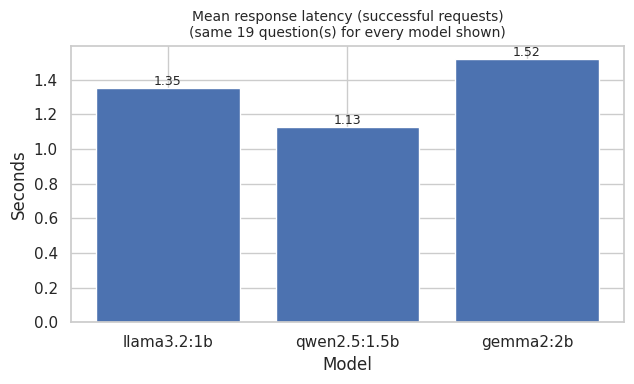

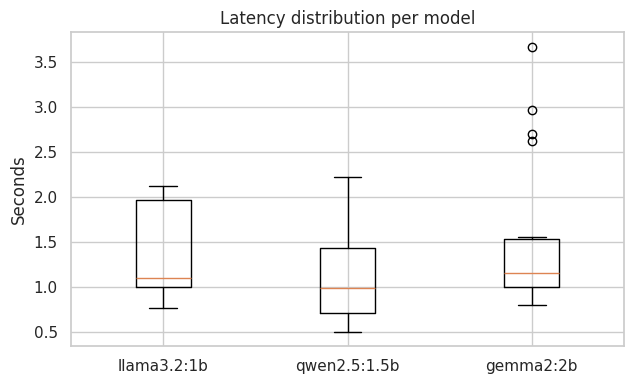

Cold-start load time (separate from per-question latency):


,session_load_time_s
model_tag,
llama3.2:1b,3.20
qwen2.5:1.5b,107.73
gemma2:2b,74.54


In [62]:
if summary_auto is not None:
    bar_plot(summary_auto, "latency_mean_s", "Mean response latency (successful requests)", "Seconds", "latency_mean.png")
    ok_rows = results_df[results_df["error"].isna()]
    groups = [(m, ok_rows.loc[ok_rows["model_tag"] == m, "latency_s"].dropna().values) for m in summary_auto.index]
    groups = [(m, v) for m, v in groups if len(v)]
    if groups:
        fig, ax = plt.subplots(figsize=(6.5, 4))
        ax.boxplot([v for _, v in groups])
        ax.set_xticks(range(1, len(groups) + 1))
        ax.set_xticklabels([m for m, _ in groups])
        ax.set_title("Latency distribution per model")
        ax.set_ylabel("Seconds")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "latency_boxplot.png", dpi=150)
        plt.show()
    print("Cold-start load time (separate from per-question latency):")
    display(summary_auto[["session_load_time_s"]].round(2))
else:
    print("No data: run the experiments first.")

### 11.4 [RUN] RAM usage comparison (sampled, approximate)

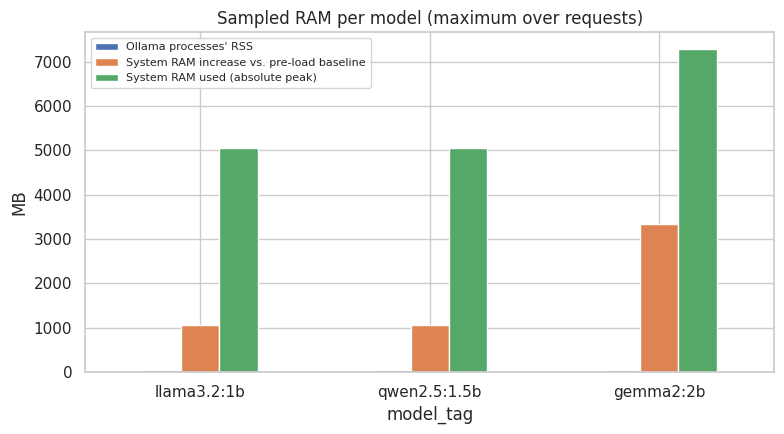

This machine's total RAM: 12,976 MB. Absolute system peak as % of total:


,peak_system_used_pct_of_total
model_tag,
llama3.2:1b,38.9
qwen2.5:1.5b,38.9
gemma2:2b,56.2


In [63]:
if summary_auto is not None:
    _labels = {"ram_peak_ollama_rss_mb_max": "Ollama processes' RSS",
               "ram_delta_system_mb_max": "System RAM increase vs. pre-load baseline",
               "ram_peak_system_used_mb_max": "System RAM used (absolute peak)"}
    ram = summary_auto[list(_labels)].dropna(axis=1, how="all").dropna(how="all")
    if ram.empty:
        print("No RAM measurements were recorded.")
    else:
        ax = ram.plot(kind="bar", figsize=(8, 4.5))
        ax.set_ylabel("MB")
        ax.set_title("Sampled RAM per model (maximum over requests)")
        ax.legend([_labels[c] for c in ram.columns], fontsize=8)
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.savefig(FIG_DIR / "ram_comparison.png", dpi=150)
        plt.show()
        total_mb = psutil.virtual_memory().total / MB
        print(f"This machine's total RAM: {total_mb:,.0f} MB. Absolute system peak as % of total:")
        display((100 * summary_auto["ram_peak_system_used_mb_max"] / total_mb).round(1).rename("peak_system_used_pct_of_total").to_frame())
else:
    print("No data: run the experiments first.")

### 11.5 [RUN] Generation speed and error rate

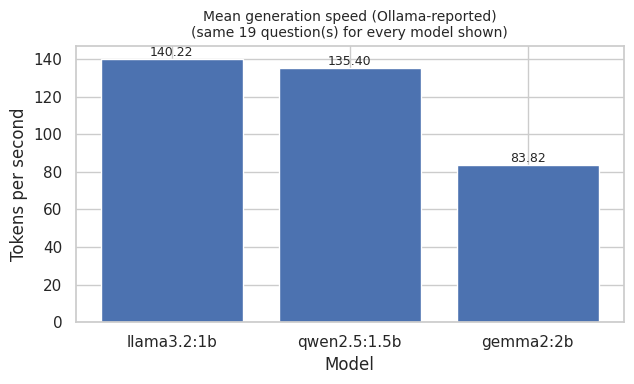

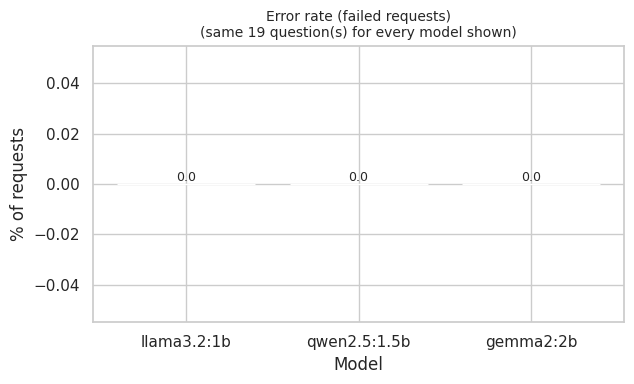

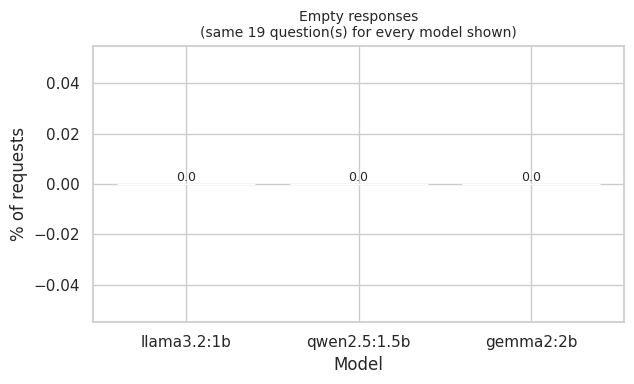

In [64]:
if summary_auto is not None:
    bar_plot(summary_auto, "tokens_per_sec_mean", "Mean generation speed (Ollama-reported)", "Tokens per second", "tokens_per_sec.png")
    bar_plot(summary_auto, "error_rate_pct", "Error rate (failed requests)", "% of requests", "error_rate.png", fmt="{:.1f}")
    bar_plot(summary_auto, "empty_response_pct", "Empty responses", "% of requests", "empty_rate.png", fmt="{:.1f}")
    if summary_auto["n_errors"].sum() > 0:
        display(results_df[results_df["error"].notna()][["model_tag", "question_id", "error_type", "error"]])
else:
    print("No data: run the experiments first.")

### 11.6 [RUN] Manual quality metrics: correctness, groundedness, hallucination, abstention
These need your scores from cells 9.8 and 9.9. Without them, a message is shown instead of charts.

In [65]:
if summary_manual is None:
    print("No manual scores imported yet. Fill the review sheet (cell 9.8), save it, and run cell 9.9, then re-run cell 11.2.")
else:
    display(summary_manual.round(2).T)
    bar_plot(summary_manual, "correctness_mean", "Manual correctness (0 to 2)", "Mean score", "correctness.png")
    bar_plot(summary_manual, "groundedness_mean", "Manual groundedness (0 to 2)", "Mean score", "groundedness.png")
    bar_plot(summary_manual, "hallucination_rate_pct", "Responses flagged with unsupported claims", "% of scored answers", "hallucination_rate.png", fmt="{:.1f}")
    bar_plot(summary_manual, "abstain_correct_pct", "Correct abstention on intentionally-absent questions", "% of those questions", "abstention.png", fmt="{:.1f}")

    pivot = (manual_merged[manual_merged["correctness_0_2"].notna()]
             .pivot_table(index="category", columns="model_tag", values="correctness_0_2", aggfunc="mean"))
    if not pivot.empty:
        plt.figure(figsize=(8, max(3, 0.5 * len(pivot))))
        sns.heatmap(pivot, annot=True, fmt=".1f", vmin=0, vmax=2, cmap="viridis", cbar_kws={"label": "mean correctness (0 to 2)"})
        plt.title("Manual correctness by question category")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "correctness_by_category.png", dpi=150)
        plt.show()

No manual scores imported yet. Fill the review sheet (cell 9.8), save it, and run cell 9.9, then re-run cell 11.2.


### 11.7 [RUN] Hallucination / unsupported-claim observations (your notes)

In [66]:
if manual_merged is None:
    print("No manual scores imported yet.")
else:
    flagged = manual_merged[manual_merged["hallucination_0_1"] == 1]
    if flagged.empty:
        print("No answers were flagged as containing unsupported claims in your scores.")
    else:
        display(flagged[["model_tag", "question_id", "category", "answer", "reviewer_notes"]])

No manual scores imported yet.


### 11.8 [RUN] Size / speed / quality trade-off view

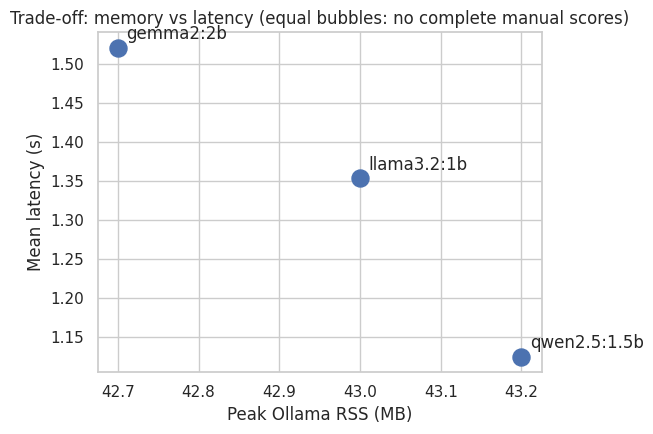

In [67]:
if summary_auto is None:
    print("No data: run the experiments first.")
else:
    trade = summary_auto[["latency_mean_s", "ram_peak_ollama_rss_mb_max"]].copy()
    use_manual = summary_manual is not None
    if use_manual:
        trade = trade.join(summary_manual[["correctness_mean"]])
    trade = trade.dropna(subset=["latency_mean_s", "ram_peak_ollama_rss_mb_max"])
    if trade.empty:
        print("Not enough recorded data for the trade-off plot.")
    else:
        # bubble size encodes manual correctness ONLY if every plotted model has a manual score; no value is ever invented
        size_by_quality = use_manual and trade["correctness_mean"].notna().all()
        sizes = (trade["correctness_mean"] * 250 + 60) if size_by_quality else 150
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        ax.scatter(trade["ram_peak_ollama_rss_mb_max"], trade["latency_mean_s"], s=sizes)
        for name, row in trade.iterrows():
            ax.annotate(name, (row["ram_peak_ollama_rss_mb_max"], row["latency_mean_s"]), textcoords="offset points", xytext=(6, 6))
        ax.set_xlabel("Peak Ollama RSS (MB)")
        ax.set_ylabel("Mean latency (s)")
        ax.set_title("Trade-off: memory vs latency" + (" (bubble size ~ manual correctness)" if size_by_quality else " (equal bubbles: no complete manual scores)"))
        plt.tight_layout()
        plt.savefig(FIG_DIR / "tradeoff.png", dpi=150)
        plt.show()

---
# Section 12: Interpretation and Recommendations

This section is a **template**. Nothing is pre-filled. First generate the **evidence summary** (computed only from your recorded data), then write your own interpretation, then optionally use the weighted decision table.

Guidance for honest interpretation:
* Quote the actual numbers and name the chart/table they come from.
* Separate *measurement* ("model X had the lowest mean latency of ... s") from *interpretation* ("so it is better suited for ... because ...").
* Mention uncertainty: small question set, a single reviewer, one repetition, background load on your PC.
* A model can win on speed and lose on grounding; the recommendation depends on how you weigh them for a *student-helpdesk* use case, where wrong policy answers are costly.

### 12.1 [DEFINE] Evidence summary and decision-table functions

In [68]:
def _extremes(series, lowest=True):
    """Return (names with the extreme value, that value). Ties are reported, not hidden."""
    s = series.dropna()
    if s.empty:
        return [], None
    target = s.min() if lowest else s.max()
    return [n for n, v in s.items() if np.isclose(v, target)], float(target)

def print_evidence_summary():
    """Print FACTS (extreme values per metric). It does not state a recommendation."""
    df, auto, merged, manual = collect_summaries()
    if auto is None:
        print("No experiment results recorded yet; nothing to summarise.")
        return
    def line(label, series, lowest, unit, source):
        names, value = _extremes(series, lowest)
        print(f"- {label}: " + (f"{', '.join(names)} ({value:.2f} {unit}) [{source}]" if names else "no data yet"))
    print("EVIDENCE (computed from recorded data; interpret it yourself in 12.4):\n")
    if len(auto) < len(MODEL_ORDER):
        print(f"NOTE: only {len(auto)} of {len(MODEL_ORDER)} models have recorded results; this is NOT a full comparison.")
    print(f"Comparison basis: {auto.attrs.get('n_common_questions')} question(s) that every model with data has a row for.\n")
    no_manual = pd.Series(dtype=float)
    line("Q1 Highest mean manual correctness", manual["correctness_mean"] if manual is not None else no_manual, False, "/2", "manual")
    line("Q2 Lowest mean latency", auto["latency_mean_s"], True, "s", "automated")
    line("Q3 Lowest peak Ollama RSS", auto["ram_peak_ollama_rss_mb_max"], True, "MB", "automated, sampled")
    line("Q3b Lowest system RAM increase vs baseline", auto["ram_delta_system_mb_max"], True, "MB", "automated, sampled")
    line("Q4 Highest mean manual groundedness", manual["groundedness_mean"] if manual is not None else no_manual, False, "/2", "manual")
    line("Q4b Lowest manual hallucination rate", manual["hallucination_rate_pct"] if manual is not None else no_manual, True, "%", "manual")
    line("Q4c Highest manual correct-abstention rate", manual["abstain_correct_pct"] if manual is not None else no_manual, False, "%", "manual")
    line("Highest mean generation speed", auto["tokens_per_sec_mean"], False, "tokens/s", "automated")
    line("Lowest error rate", auto["error_rate_pct"], True, "%", "automated")
    if manual is None:
        print("\n(Manual-quality evidence is missing: complete cells 9.8 and 9.9 to answer Q1 and Q4 properly.)")
    print("\nWith few questions and one reviewer, small differences may be noise; check the per-question answers before concluding.")

DECISION_WEIGHTS = {            # <-- EDIT: your priorities (relative importance). Set a weight to 0 to ignore a criterion.
    "correctness_mean": 1.0, "groundedness_mean": 1.0, "hallucination_rate_pct": 1.0,
    "latency_mean_s": 1.0, "ram_peak_ollama_rss_mb_max": 1.0, "tokens_per_sec_mean": 1.0, "error_rate_pct": 1.0}
HIGHER_IS_BETTER = {"correctness_mean": True, "groundedness_mean": True, "hallucination_rate_pct": False,
                    "latency_mean_s": False, "ram_peak_ollama_rss_mb_max": False, "tokens_per_sec_mean": True, "error_rate_pct": False}
RAM_BUDGET_MB = None            # <-- EDIT: maximum peak Ollama RSS you consider acceptable (None = no limit)
MAX_ERROR_RATE_PCT = None       # <-- EDIT: e.g. 5.0 (None = no limit)
MAX_MEAN_LATENCY_S = None       # <-- EDIT: latency your users would tolerate (None = no limit)
REQUIRE_ALL_MODELS = True       # refuse to rank models unless every registered model has recorded results

def build_decision_table():
    """
    Min-max normalise each criterion that is available for EVERY model (1 = best), then take a weighted average.
    WARNING: with only three models, min-max normalisation exaggerates small differences. The weights are YOUR value judgement.
    """
    df, auto, merged, manual = collect_summaries()
    if auto is None:
        print("No experiment results yet.")
        return None
    if REQUIRE_ALL_MODELS and len(auto) < len(MODEL_ORDER):
        print(f"Only {len(auto)} of {len(MODEL_ORDER)} models have recorded results, so no ranking is produced. "
              "Run the remaining models first (or set REQUIRE_ALL_MODELS = False knowing the table is then incomplete).")
        return None
    metrics = auto.join(manual, how="left") if manual is not None else auto.copy()
    used = [c for c, w in DECISION_WEIGHTS.items() if w > 0 and c in metrics and metrics[c].notna().all()]
    skipped = [c for c, w in DECISION_WEIGHTS.items() if w > 0 and c not in used]
    if skipped:
        print("Criteria skipped (data missing for at least one model):", skipped)
    if not used:
        print("No criteria with complete data available.")
        return None
    table = pd.DataFrame(index=metrics.index)
    for col in used:
        s = metrics[col]
        span = s.max() - s.min()
        norm = pd.Series(1.0, index=s.index) if span == 0 else ((s - s.min()) / span if HIGHER_IS_BETTER[col] else (s.max() - s) / span)
        table[col + "_score"] = norm
    weights = pd.Series({c: DECISION_WEIGHTS[c] for c in used})
    table["weighted_score"] = (table[[c + "_score" for c in used]] * (weights / weights.sum()).values).sum(axis=1)
    ok = pd.Series(True, index=metrics.index)
    if RAM_BUDGET_MB is not None:
        ok &= metrics["ram_peak_ollama_rss_mb_max"] <= RAM_BUDGET_MB
    if MAX_ERROR_RATE_PCT is not None:
        ok &= metrics["error_rate_pct"] <= MAX_ERROR_RATE_PCT
    if MAX_MEAN_LATENCY_S is not None:
        ok &= metrics["latency_mean_s"] <= MAX_MEAN_LATENCY_S
    table["meets_your_constraints"] = ok
    return table.sort_values("weighted_score", ascending=False)

print("Interpretation helpers defined.")

Interpretation helpers defined.


### 12.2 [RUN] Evidence summary (facts only)

In [69]:
print_evidence_summary()

EVIDENCE (computed from recorded data; interpret it yourself in 12.4):

Comparison basis: 19 question(s) that every model with data has a row for.

- Q1 Highest mean manual correctness: no data yet
- Q2 Lowest mean latency: qwen2.5:1.5b (1.13 s) [automated]
- Q3 Lowest peak Ollama RSS: gemma2:2b (42.70 MB) [automated, sampled]
- Q3b Lowest system RAM increase vs baseline: qwen2.5:1.5b (1062.70 MB) [automated, sampled]
- Q4 Highest mean manual groundedness: no data yet
- Q4b Lowest manual hallucination rate: no data yet
- Q4c Highest manual correct-abstention rate: no data yet
- Highest mean generation speed: llama3.2:1b (140.22 tokens/s) [automated]
- Lowest error rate: llama3.2:1b, qwen2.5:1.5b, gemma2:2b (0.00 %) [automated]

(Manual-quality evidence is missing: complete cells 9.8 and 9.9 to answer Q1 and Q4 properly.)

With few questions and one reviewer, small differences may be noise; check the per-question answers before concluding.


/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.to_numeric(series.astype(str).str.strip().replace({"": np.nan, "nan": np.nan}), errors="coerce")
/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.to_numeric(series.astype(str).str.strip().replace({"": np.nan, "nan": np.nan}), errors="coerce")
/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old 

### 12.3 [EDIT][RUN] Optional weighted decision table
Edit the weights and constraints in cell 12.1 to reflect **your** priorities for a student helpdesk (for example, weighting hallucination and groundedness highly), re-run 12.1, then run this cell. The top row is a **data-driven candidate**, not an automatic verdict; confirm it against your qualitative reading of the answers.

In [70]:
decision_table = build_decision_table()
if decision_table is not None:
    display(decision_table.round(3))
    eligible = decision_table[decision_table["meets_your_constraints"]]
    if eligible.empty:
        print("No model satisfies all of your constraints. Relax a constraint or discuss this finding.")
    else:
        print(f"Highest weighted score among models meeting your constraints: {eligible.index[0]} "
              f"({eligible.iloc[0]['weighted_score']:.3f}). Treat this as a candidate and justify it in 12.4.")

Criteria skipped (data missing for at least one model): ['correctness_mean', 'groundedness_mean', 'hallucination_rate_pct']


/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.to_numeric(series.astype(str).str.strip().replace({"": np.nan, "nan": np.nan}), errors="coerce")
/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return pd.to_numeric(series.astype(str).str.strip().replace({"": np.nan, "nan": np.nan}), errors="coerce")
/tmp/ipykernel_619/1688037482.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old 

,latency_mean_s_score,ram_peak_ollama_rss_mb_max_score,tokens_per_sec_mean_score,error_rate_pct_score,weighted_score,meets_your_constraints
model_tag,,,,,,
qwen2.5:1.5b,1.000,0.0,0.914,1.0,0.729,True
llama3.2:1b,0.421,0.4,1.000,1.0,0.705,True
gemma2:2b,0.000,1.0,0.000,1.0,0.500,True


Highest weighted score among models meeting your constraints: qwen2.5:1.5b (0.729). Treat this as a candidate and justify it in 12.4.
